# Used Cars Cost Prediction (India)
## 1. Business problem and data source
**Problem:** buyers and sellers of used cars in India struggle to know whether a listing is fairly priced. We build a model that predicts a fair price range and flags listings as over- or under-priced.
**Data:** CarDekho used-car listings (Kaggle, 'Vehicle dataset'). The target is the listing price in INR. Limitations: no city column, the data ends in 2020, and prices are listing prices, not confirmed transaction prices.

### 1.1 Load the data

In [1]:
# Cell 1: imports and load
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
pd.set_option("display.max_columns", 50)
RAW = "../data/raw/Car details v3.csv"
df_raw = pd.read_csv(RAW)
print("Raw shape:", df_raw.shape)
df_raw.head()

Raw shape: (8128, 13)


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats
0,Maruti Swift Dzire VDI,2014,450000,145500,Diesel,Individual,Manual,First Owner,23.4 kmpl,1248 CC,74 bhp,190Nm@ 2000rpm,5.0
1,Skoda Rapid 1.5 TDI Ambition,2014,370000,120000,Diesel,Individual,Manual,Second Owner,21.14 kmpl,1498 CC,103.52 bhp,250Nm@ 1500-2500rpm,5.0
2,Honda City 2017-2020 EXi,2006,158000,140000,Petrol,Individual,Manual,Third Owner,17.7 kmpl,1497 CC,78 bhp,"12.7@ 2,700(kgm@ rpm)",5.0
3,Hyundai i20 Sportz Diesel,2010,225000,127000,Diesel,Individual,Manual,First Owner,23.0 kmpl,1396 CC,90 bhp,22.4 kgm at 1750-2750rpm,5.0
4,Maruti Swift VXI BSIII,2007,130000,120000,Petrol,Individual,Manual,First Owner,16.1 kmpl,1298 CC,88.2 bhp,"11.5@ 4,500(kgm@ rpm)",5.0


### 1.2 Data audit
Before modelling, we check data quality. Duplicates matter most: if identical rows land in both train and test, the model memorises them and the score is inflated.

In [2]:
# Cell 2: audit table
audit = {
    "rows_raw": len(df_raw),
    "exact_duplicates": int(df_raw.duplicated().sum()),
    "rows_after_dedupe": len(df_raw.drop_duplicates()),
    "year_min": int(df_raw.year.min()), "year_max": int(df_raw.year.max()),
    "price_min": int(df_raw.selling_price.min()), "price_max": int(df_raw.selling_price.max()),
    "median_price": int(df_raw.selling_price.median()),
}
print(pd.Series(audit))
print("\nMissing values:\n", df_raw.isna().sum()[lambda s: s > 0])

rows_raw                 8128
exact_duplicates         1202
rows_after_dedupe        6926
year_min                 1983
year_max                 2020
price_min               29999
price_max            10000000
median_price           450000
dtype: int64

Missing values:
 mileage      221
engine       221
max_power    215
torque       222
seats        221
dtype: int64


### 1.3 Are the missing values the same rows?
If the gaps in mileage, engine, max_power, torque and seats are the same rows, they are systematic (a scraping gap), not random, and this decides how we treat them.

In [3]:
# Cell 3: missing-value pattern
spec_cols = ["mileage", "engine", "max_power", "torque", "seats"]
miss = df_raw[spec_cols].isna()
print("Rows missing ANY spec:", miss.any(axis=1).sum())
print("Rows missing ALL specs:", miss.all(axis=1).sum())

Rows missing ANY spec: 222
Rows missing ALL specs: 215


### 1.4 Listings per car model
Later we validate by holding out whole car models, so the model is tested on cars it has never seen. This check shows whether we have enough listings per model for that.

In [4]:
# Cell 4: listings per model
df_raw["brand"] = df_raw["name"].str.split().str[0]
df_raw["model_key"] = df_raw["name"].str.split().str[:2].str.join(" ")
per_model = df_raw.drop_duplicates().model_key.value_counts()
print("Distinct brand+model:", per_model.size)
print(per_model.describe())
print("Models with < 5 listings:", (per_model < 5).sum())

Distinct brand+model: 210
count    210.000000
mean      32.980952
std       68.986717
min        1.000000
25%        3.000000
50%        8.000000
75%       32.000000
max      670.000000
Name: count, dtype: float64
Models with < 5 listings: 77


### 1.5 Findings
- **Duplicates:** 1,202 of 8,128 rows (14.8%) are exact duplicates. We remove them before any split, leaving 6,926 rows. There is no listing ID, so we assume identical rows are repeats. That is a limitation.
- **Price is heavily skewed:** median ₹4.5L, maximum ₹1 crore. This motivates modelling log(price) (justified in Section 3).
- **Missing specs are systematic, not random:** 215 of the 222 rows with any missing spec lack all five fields at once, so the gap looks like a source issue. We will test whether missingness relates to price before choosing an imputation.
- **Validation design:** a naive brand+model key gives 210 groups, and 77 of them (37%) have fewer than 5 listings. Grouped cross-validation is feasible, but the model key needs a better definition (Section 2).

## 2. Cleaning and feature parsing
Raw columns carry units inside strings and the car `name` packs brand, model and variant together. We turn them into clean numeric features and a **model key** that we will later use to keep whole car models out of the training folds.

**Decisions made in this section**
- Units are parsed to numbers. Engine is always in CC and power in bhp. Mileage is kmpl for most rows but **km/kg for 87 CNG/LPG cars**, so `fuel` stays in the model.
- A mileage or power of 0 is treated as missing, not as a real value.
- `torque` is dropped: it comes in inconsistent formats and mostly repeats engine and power.
- `age = 2020 − year`, because the data ends in 2020.
- A custom `model_key` replaces the naive "first two words" rule, which merged the Swift Dzire sedan into Swift and turned "Wagon R" into "Wagon".
- **Outlier rule:** a car with implied usage above 100,000 km per year is physically implausible and is removed (4 rows). High-priced cars and high-mileage taxis are kept because they are real.

In [5]:
# Cell 5: cleaning functions (defined inline so the notebook is self-contained)
import re
REF_YEAR = 2020                       # dataset ends in 2020, so we treat 2020 as "now"
MULTI_BRANDS = ["Land Rover", "Ashok Leyland"]            # brands written with two words
BRAND_FIX = {"Force": "Force Motors"}                     # one-word prefix -> full brand
MULTI_MODELS = ["Swift Dzire", "Wagon R", "Grand i10", "Alto 800", "Alto K10", "Santro Xing",
                "Indica Vista", "Vitara Brezza", "Innova Crysta", "Range Rover", "S Cross", "Grand Vitara"]

def split_brand_model(name):
    """Split 'Maruti Swift Dzire VDI' -> ('Maruti', 'Swift Dzire'); variant words are dropped."""
    s = name.strip()
    for b in MULTI_BRANDS:
        if s.startswith(b + " "):
            brand, rest = b, s[len(b) + 1:]
            break
    else:
        brand, _, rest = s.partition(" ")
        brand = BRAND_FIX.get(brand, brand)
    for m in MULTI_MODELS:                       # known two-word models first
        if rest.startswith(m):
            return brand, m
    toks = rest.split()
    if len(toks) > 1 and toks[0] == "New":       # 'New Safari', 'New C-Class'
        return brand, "New " + toks[1]
    if len(toks) > 1 and toks[1] == "Class":     # 'GLA Class', 'B Class'
        return brand, toks[0] + " Class"
    return brand, (toks[0] if toks else "")

def num(series, pattern):
    """Pull the leading number out of strings like '23.4 kmpl'; anything unparseable becomes NaN."""
    return pd.to_numeric(series.str.extract(pattern)[0], errors="coerce")

def clean(raw, dedupe=True):
    d = (raw.drop_duplicates() if dedupe else raw).reset_index(drop=True).copy()   # 1. remove exact duplicates first
    bm = d["name"].map(split_brand_model)
    d["brand"], d["model"] = bm.str[0], bm.str[1]
    d["model_key"] = d["brand"] + " " + d["model"]            # grouping key for leakage-safe CV
    d["mileage_val"] = num(d.mileage, r"^([\d.]+)")           # kmpl (km/kg for CNG/LPG)
    d["engine_cc"]   = num(d.engine,  r"^([\d.]+)")
    d["power_bhp"]   = num(d.max_power, r"^([\d.]+)")
    d.loc[d.mileage_val == 0, "mileage_val"] = np.nan         # a 0 kmpl car is a data gap
    d.loc[d.power_bhp == 0, "power_bhp"] = np.nan
    d["age"] = REF_YEAR - d.year
    d["km_per_year"] = d.km_driven / (d.age + 1)              # +1 so a 2020 car does not divide by 0
    d["owner"] = d.owner.replace({"Test Drive Car": "First Owner"})
    return d.drop(columns=["torque", "mileage", "engine", "max_power"])

df = clean(df_raw[df_raw.columns[:13]])    # only the 13 original columns (Cell 4 added helper columns to df_raw)
print("After de-dup and parsing:", df.shape)

After de-dup and parsing: (6926, 17)


In [6]:
# Cell 6: outlier rule - physically impossible usage, NOT 'expensive' or 'high-mileage taxi'
bad = df[df.km_per_year > 100_000]
print("Rows removed:", len(bad))
display(bad[["name", "year", "km_driven", "selling_price"]])
df = df[df.km_per_year <= 100_000].reset_index(drop=True)
print("Final shape:", df.shape)

Rows removed: 4


,name,year,km_driven,selling_price
1325,Mahindra XUV500 W7,2020,120000,830000
1646,Mahindra XUV500 W6 2WD,2012,1500000,500000
2131,Maruti Celerio X ZXI,2020,120000,250000
3161,Hyundai i20 Asta 1.2,2007,2360457,550000


Final shape: (6922, 17)


In [7]:
# Cell 7: sanity checks (the notebook fails loudly if the cleaning is wrong)
assert df.duplicated().sum() == 0
assert (df.age >= 0).all() and df.selling_price.min() > 0
print("Unique model keys:", df.model_key.nunique())
print("Models with < 5 listings:", (df.model_key.value_counts() < 5).sum())
print("\nMissing values after parsing:\n", df.isna().sum()[lambda s: s > 0])
df.describe().T

Unique model keys: 218
Models with < 5 listings: 79

Missing values after parsing:
 seats          208
mileage_val    223
engine_cc      208
power_bhp      209
dtype: int64


,count,mean,std,min,25%,50%,75%,max
year,6922.0,2013.419532,4.077165,1983.0,2011.000000,2014.000000,2017.000000,2020.0
selling_price,6922.0,517261.877925,519893.457931,29999.0,250000.000000,400000.000000,633500.000000,10000000.0
km_driven,6922.0,73446.055764,48554.496519,1.0,40000.000000,70000.000000,100000.000000,577414.0
seats,6714.0,5.434316,0.984123,2.0,5.000000,5.000000,5.000000,14.0
mileage_val,6699.0,19.510004,3.947796,9.0,16.800000,19.490000,22.540000,42.0
engine_cc,6714.0,1430.767799,493.434805,624.0,1197.000000,1248.000000,1498.000000,3604.0
power_bhp,6713.0,87.752599,31.716550,32.8,67.100000,81.830000,100.000000,400.0
age,6922.0,6.580468,4.077165,0.0,3.000000,6.000000,9.000000,37.0
km_per_year,6922.0,10570.466745,6713.515387,0.1,6153.846154,9166.666667,13333.333333,70000.0


## 3. Exploratory analysis
We look for what drives price, and for traps that would mislead a model. Four questions: are the missing specs random, what shape is the target, how fast do cars lose value, and what does mileage really do?

In [8]:
# Cell 8: is missingness random? (decides imputation vs dropping)
from scipy.stats import mannwhitneyu
df["specs_missing"] = df[["engine_cc", "power_bhp", "seats"]].isna().any(axis=1)
display(df.groupby("specs_missing").agg(rows=("selling_price", "size"), median_price=("selling_price", "median"),
                                        median_year=("year", "median"), median_km=("km_driven", "median")))
stat, p = mannwhitneyu(df.loc[df.specs_missing, "selling_price"], df.loc[~df.specs_missing, "selling_price"])
print(f"Mann-Whitney p-value (price: missing vs present): {p:.2e}")
has_specs = df.groupby("model_key")["engine_cc"].apply(lambda s: s.notna().any())
print("Share of missing-spec rows whose model has specs elsewhere:",
      round(df.loc[df.specs_missing, "model_key"].map(has_specs).mean(), 3))

,rows,median_price,median_year,median_km
specs_missing,,,,
False,6713,420000.0,2014.0,68089.0
True,209,175000.0,2008.0,90000.0


Mann-Whitney p-value (price: missing vs present): 2.83e-50
Share of missing-spec rows whose model has specs elsewhere: 0.904


**Insight:** the 209 rows with missing specs have a median price of ₹1.75L against ₹4.2L for the rest, and they are older (2008 vs 2014). Missingness is therefore **not random**. Dropping them would remove the cheapest segment, and filling with the global mean would misprice them. Since 90% belong to a model that has specs elsewhere, our first idea was to impute within model and fuel. Section 5 tests that idea against simple median imputation (done inside each CV fold, to avoid leakage) and keeps missing-indicator features.

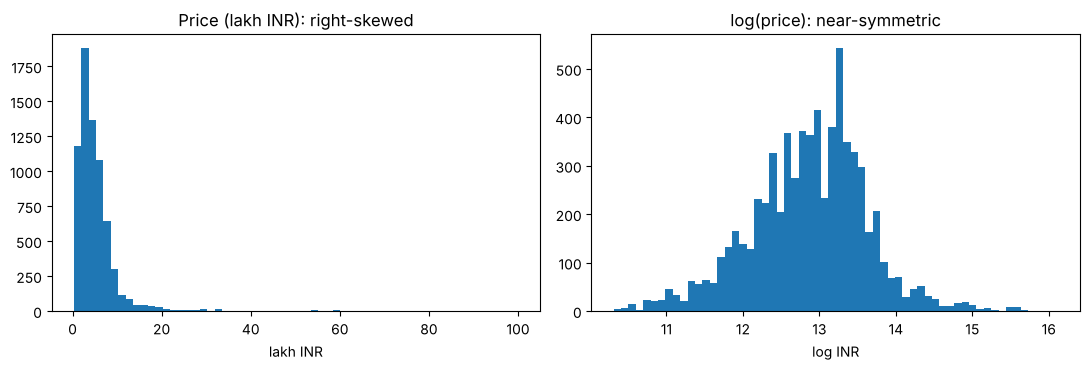

Skewness  raw: 5.57 | log: -0.16


In [9]:
# Cell 9: target distribution and the log transform
from scipy.stats import skew
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].hist(df.selling_price / 1e5, bins=60); ax[0].set_title("Price (lakh INR): right-skewed"); ax[0].set_xlabel("lakh INR")
ax[1].hist(np.log(df.selling_price), bins=60); ax[1].set_title("log(price): near-symmetric"); ax[1].set_xlabel("log INR")
plt.tight_layout(); plt.savefig("../reports/figures/price_distribution.png", dpi=120); plt.show()
print("Skewness  raw:", round(skew(df.selling_price), 2), "| log:", round(skew(np.log(df.selling_price)), 2))

**Insight:** raw price has skewness 5.6, because a few luxury cars stretch the tail, and log-price has −0.16. We model **log(price)** for two reasons. A ₹50,000 error means very different things on a ₹1L car and a ₹50L car, and depreciation works in percentages (a car loses roughly a fixed share per year, not a fixed rupee amount). Predictions are converted back with `exp()`, and we report errors in rupees and in percent.

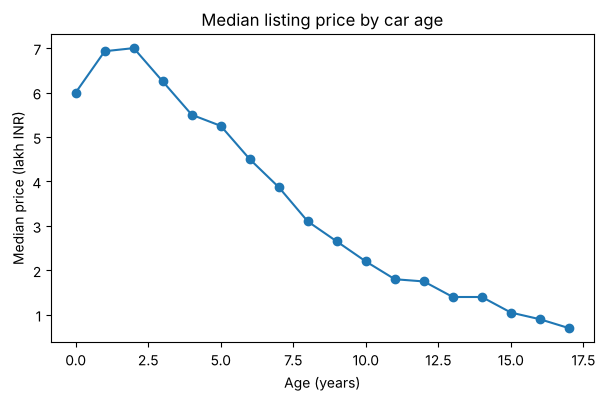

,brand,n,min_age,max_age,naive_annual_dep_%
6,Renault,206,1,9,-0.3
9,Volkswagen,174,0,12,8.5
4,Mahindra,721,0,37,9.5
2,Honda,362,0,18,11.9
8,Toyota,357,0,20,12.5
5,Maruti,2164,0,29,12.5
3,Hyundai,1266,0,21,12.9
0,Chevrolet,216,3,15,13.2
1,Ford,361,0,17,13.9
7,Tata,647,0,21,14.1


In [10]:
# Cell 10: depreciation by age, and a naive per-brand estimate (we will test its weakness next)
import matplotlib.pyplot as plt
med = df.groupby("age").selling_price.agg(median="median", n="size")
med = med[med.n >= 30]                                  # ignore ages with too few cars
plt.figure(figsize=(7, 4)); plt.plot(med.index, med["median"] / 1e5, marker="o")
plt.xlabel("Age (years)"); plt.ylabel("Median price (lakh INR)"); plt.title("Median listing price by car age")
plt.savefig("../reports/figures/price_by_age.png", dpi=120); plt.show()

rows = []
for b, g in df.groupby("brand"):
    if len(g) >= 150:
        slope = np.polyfit(g.age, np.log(g.selling_price), 1)[0]       # slope of log-price per year of age
        rows.append((b, len(g), g.age.min(), g.age.max(), round((1 - np.exp(slope)) * 100, 1)))
brand_dep = pd.DataFrame(rows, columns=["brand", "n", "min_age", "max_age", "naive_annual_dep_%"]).sort_values("naive_annual_dep_%")
display(brand_dep)

In [11]:
# Cell 10b: evidence for the insight below - the age curve and the Renault slope are mix effects
young, new = df[df.age.isin([1, 2])], df[df.age == 0]
print("Maruti share of listings   age 0: %.0f%% | ages 1-2: %.0f%%" % (100 * (new.brand == "Maruti").mean(),
                                                                        100 * (young.brand == "Maruti").mean()))
both = set(new.model_key) & set(young.model_key)
print("Car models present at both age 0 and ages 1-2:", len(both))
display(df[df.model_key.isin(both) & (df.age <= 2)].groupby("age").selling_price.agg(median_price="median", rows="size"))
ren = df[df.brand == "Renault"]
rows = []
for m in ["KWID", "Duster"]:
    g = ren[ren.model == m]
    rows.append((m, len(g), g.age.min(), g.age.max(), round((1 - np.exp(np.polyfit(g.age, np.log(g.selling_price), 1)[0])) * 100, 1)))
display(pd.DataFrame(rows, columns=["Renault model", "n", "min_age", "max_age", "annual_dep_%"]))

Maruti share of listings   age 0: 46% | ages 1-2: 30%
Car models present at both age 0 and ages 1-2: 32


,median_price,rows
age,,
0,600000.0,57
1,610000.0,203
2,620000.0,327


,Renault model,n,min_age,max_age,annual_dep_%
0,KWID,99,1,5,8.2
1,Duster,71,2,8,11.1


**Insight (and a warning about it):** the median price *rises* from age 0 to age 2 (about ₹6.0L to ₹7.0L) before falling. That is not appreciation: Maruti makes up 46% of the age-0 listings against about 30% at ages 1–2, and among the car models that appear at both ages the median price is flat (about ₹6.0L–₹6.2L from age 0 to 2). The curve mixes car type with age. The per-brand slopes have the same problem: Renault shows about 0% depreciation only because its young cars are mostly the cheap KWID (ages 1–5) while its older cars are mostly the pricier Duster (ages 2–8); within each model the slope is about 8% (KWID) and 11% (Duster) a year. **Raw brand comparisons confound age with which models and variants a brand sells.** The next cells separate them.

In [12]:
# Cell 11: mileage looks like it RAISES price - why?
band = df[df.age.between(5, 7)].copy()                  # hold age roughly constant
band["km_quartile"] = pd.qcut(band.km_driven, 4, labels=["Q1 low", "Q2", "Q3", "Q4 high"])
display(band.groupby("km_quartile", observed=True).agg(median_price=("selling_price", "median"),
        diesel_share=("fuel", lambda s: (s == "Diesel").mean()), rows=("fuel", "size")).round(2))

,median_price,diesel_share,rows
km_quartile,,,
Q1 low,420000.0,0.34,521
Q2,450000.0,0.64,399
Q3,465000.0,0.79,457
Q4 high,500000.0,0.91,447


**Insight (a confounding trap):** among 5–7-year-old cars, the *highest*-mileage quartile has the *highest* median price (₹5.0L vs ₹4.2L). Diesel share explains why: it rises from 34% to 91% across the quartiles, and diesel cars are driven more and priced higher. Mileage itself isn't raising prices. A naive plot of price against km would give a wrong story.

In [13]:
# Cell 12: depreciation WITHIN a model (model fixed effects, by de-meaning each variable within model_key)
d = df[df.groupby("model_key")["model_key"].transform("size") >= 10].copy()    # models with >= 10 listings
d["log_price"] = np.log(d.selling_price); d["km_10k"] = d.km_driven / 10_000
d["is_diesel"] = (d.fuel == "Diesel").astype(float); d["is_auto"] = (d.transmission == "Automatic").astype(float)
d["not_first_owner"] = (d.owner != "First Owner").astype(float)
cols = ["age", "km_10k", "is_diesel", "is_auto", "not_first_owner"]
dm = d[cols + ["log_price"]] - d.groupby("model_key")[cols + ["log_price"]].transform("mean")   # remove model identity
beta, *_ = np.linalg.lstsq(dm[cols].values, dm["log_price"].values, rcond=None)
effects = pd.DataFrame({"effect_on_price_%": ((np.exp(beta) - 1) * 100).round(1)}, index=cols)
print("Rows:", len(d), "| models:", d.model_key.nunique()); display(effects)

Rows: 6540 | models: 104


,effect_on_price_%
age,-9.8
km_10k,-0.9
is_diesel,13.6
is_auto,11.3
not_first_owner,-7.7


**Insight:** comparing cars *of the same model*, each extra year of age lowers price by about **9.8%**, and each extra 10,000 km lowers it by only about **0.9%** once age is held fixed. Diesel adds about 13.6%, an automatic gearbox adds about 11.3%, and a non-first owner costs about 7.7%. **Age matters far more than mileage.** These are descriptive associations within models, not causal effects, and the models with few listings are excluded.

## 4. Validation design and baselines
Before fitting anything strong we decide **how we will judge it**. We lock away a final test set made of whole car models the model never sees, tune only on the development set, and compare every model with simple baselines. We also measure how much a careless split would flatter the results.

**Decisions made in this section**
- **Final test set:** 20% of the car models, locked away until the very end.
- **Development validation:** `StratifiedGroupKFold`, grouped by `model_key` (a model never sits on both sides of a split) and stratified by price band (cheap and expensive cars stay balanced).
- **Metrics:** RMSE and R² on log-price (approximate relative error), MAE in rupees (easy to read), and **MedAPE**, the median absolute percentage error (robust to luxury outliers, and the number a buyer cares about).
- **Baselines:** global median, median by age, and a linear model on age and log-mileage.

In [14]:
# Cell 13: target, features, and the locked-away final test set
from sklearn.model_selection import StratifiedGroupKFold
df["log_price"] = np.log(df.selling_price)                       # target (see Section 3)
df["log_km"] = np.log1p(df.km_driven)                            # log of mileage; 1p guards km = 0
NUM = ["age", "km_driven", "engine_cc", "power_bhp", "seats", "mileage_val"]
CAT = ["fuel", "transmission", "owner", "seller_type", "brand"]
price_band = pd.qcut(df.selling_price, 5, labels=False)          # keeps cheap/expensive cars balanced across folds
outer = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
dev_idx, test_idx = next(outer.split(df, price_band, groups=df.model_key))   # first fold = 20% test
dev, test = df.iloc[dev_idx].reset_index(drop=True), df.iloc[test_idx].reset_index(drop=True)
print("Development rows:", len(dev), "| Final test rows:", len(test), f"({len(test)/len(df):.1%})")
print("Models shared between dev and test:", len(set(dev.model_key) & set(test.model_key)))
print("Median price  dev:", dev.selling_price.median(), "| test:", test.selling_price.median())

Development rows: 5530 | Final test rows: 1392 (20.1%)
Models shared between dev and test: 0
Median price  dev: 400000.0 | test: 415000.0


In [15]:
# Cell 14: metrics and a cross-validation helper (everything is scored in RUPEE terms after exp())
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.base import clone
def score(y_log_true, y_log_pred):
    p_true, p_pred = np.exp(y_log_true), np.exp(y_log_pred)
    return {"RMSE_log": np.sqrt(mean_squared_error(y_log_true, y_log_pred)),
            "R2_log": r2_score(y_log_true, y_log_pred),
            "MAE_INR": mean_absolute_error(p_true, p_pred),
            "MedAPE_%": 100 * np.median(np.abs(p_pred - p_true) / p_true)}

def cv_eval(model, data, features, cv):
    """Grouped CV on `data`. Returns mean and std of each metric, plus out-of-fold predictions."""
    X, y, g = data[features], data["log_price"], data["model_key"]
    bands = pd.qcut(data.selling_price, 5, labels=False)
    rows, oof = [], np.zeros(len(data))
    for tr, va in cv.split(X, bands, groups=g):
        m = clone(model).fit(X.iloc[tr], y.iloc[tr])           # fit on training folds only
        oof[va] = m.predict(X.iloc[va])
        rows.append(score(y.iloc[va].values, oof[va]))
    r = pd.DataFrame(rows)
    return r.mean(), r.std(), oof

cv_group = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=7)   # development CV, grouped by model

In [16]:
# Cell 15: baseline ladder (grouped CV on the development set)
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.base import BaseEstimator, RegressorMixin

class AgeMedian(BaseEstimator, RegressorMixin):
    """Predict the median log-price of cars of the same age (ages above 20 are pooled)."""
    def fit(self, X, y):
        a = X["age"].clip(upper=20)
        self.table_ = pd.Series(np.asarray(y), index=a.values).groupby(level=0).median()
        self.global_ = float(np.median(y)); return self
    def predict(self, X):
        return X["age"].clip(upper=20).map(self.table_).fillna(self.global_).values

baselines = {"B0 global median": (DummyRegressor(strategy="median"), ["age"]),
             "B1 median by age": (AgeMedian(), ["age"]),
             "B2 linear: age + log km": (LinearRegression(), ["age", "log_km"])}
res = {}
for name, (m, feats) in baselines.items():
    mean, std, _ = cv_eval(m, dev, feats, cv_group)
    res[name] = mean
baseline_table = pd.DataFrame(res).T.round(3)
baseline_table

,RMSE_log,R2_log,MAE_INR,MedAPE_%
B0 global median,0.769,-0.004,277822.994,42.857
B1 median by age,0.528,0.526,204502.088,28.954
B2 linear: age + log km,0.528,0.526,205299.901,28.671


**Insight:** knowing only a car's age cuts the typical error from about 43% to 29% (R² on log-price from 0 to 0.53). Adding mileage to a linear model changes almost nothing, which is consistent with Section 3, where 10,000 km cost only about 1% once age is held fixed. These baselines are the bar every later model has to clear: **RMSE_log 0.53, MedAPE about 29%**.

In [17]:
# Cell 16: how much does a careless split flatter the score? (same model, same data, three validation designs)
from sklearn.ensemble import RandomForestRegressor
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import KFold

prep = ColumnTransformer([("num", SimpleImputer(strategy="median"), NUM),     # imputer is fitted inside each fold
                          ("cat", OneHotEncoder(handle_unknown="ignore"), CAT)])
rf = Pipeline([("prep", prep), ("rf", RandomForestRegressor(n_estimators=150, random_state=0, n_jobs=-1))])

# Duplicates kept, restricted to the same car models as the dev set so that only the duplicates differ
leaky = clean(df_raw[df_raw.columns[:13]], dedupe=False)
leaky = leaky[leaky.km_per_year <= 100_000]
leaky = leaky[leaky.model_key.isin(dev.model_key)].reset_index(drop=True)
leaky["log_price"] = np.log(leaky.selling_price)

def eval_splits(data, splits):
    X, y = data[NUM + CAT], data["log_price"]; out = []
    for tr, va in splits:
        m = clone(rf).fit(X.iloc[tr], y.iloc[tr]); out.append(score(y.iloc[va].values, m.predict(X.iloc[va])))
    return pd.DataFrame(out).mean()

kf = KFold(5, shuffle=True, random_state=1)
bands = pd.qcut(dev.selling_price, 5, labels=False)
leak_demo = pd.DataFrame({
    "1) Duplicates kept, random split": eval_splits(leaky, kf.split(leaky)),
    "2) De-duplicated, random split": eval_splits(dev, kf.split(dev)),
    "3) De-duplicated, grouped by model": eval_splits(dev, cv_group.split(dev, bands, groups=dev.model_key)),
}).T.round(3)
leak_demo

,RMSE_log,R2_log,MAE_INR,MedAPE_%
"1) Duplicates kept, random split",0.215,0.934,66227.942,9.821
"2) De-duplicated, random split",0.236,0.906,78907.180,12.509
"3) De-duplicated, grouped by model",0.332,0.810,116933.980,19.056


**Insight: the same random forest on the same cars gives three very different scores.** Keeping duplicates and splitting randomly gives R² about 0.93 and a typical error near 10%, because the model is tested on rows it has already seen. Removing duplicates drops that to about 0.91 / 12.5%. Holding out whole car models gives about **0.81 / 19%**, which is what the model can do on a model it has never priced. Many submissions report the first number. We report the third and explain the difference. The first two describe a typical repeat listing, and the third is the stress test.

## 5. Models
We now compare model families on the **development set only**; the final test set stays locked. All preprocessing (median imputation with missing-indicators, scaling, one-hot encoding) lives **inside** each pipeline, so it is learned from the training folds only and cannot leak.

**Decisions made in this section**
- **Candidates:** regularised linear models (Ridge, ElasticNet), random forest, and three gradient-boosting libraries (HistGradientBoosting, XGBoost, LightGBM).
- **Features:** age, log-mileage, engine, power, seats, mileage, fuel, transmission, owner, seller type and brand. The model identity (`model_key`) is deliberately **not** a feature: it is only the grouping key for validation.
- **Two validation regimes for every model:** *grouped by car model* (the stress test: pricing a model never seen) and *random on de-duplicated data* (a typical repeat listing, where the model has been seen).
- **Selection rule, stated here and applied mechanically below:** take the best grouped-CV RMSE_log, keep every model within one fold-standard-deviation of it (one-standard-error rule), and among those choose the best typical-listing error.

In [18]:
# Cell 17: features and a leakage-safe pipeline factory
for part in (df, dev, test):                                      # log versions of the two skewed spec columns (helps linear models)
    part["log_engine"] = np.log(part.engine_cc)
    part["log_power"] = np.log(part.power_bhp)
NUM_M = ["age", "log_km", "log_engine", "log_power", "seats", "mileage_val"]
CAT_M = ["fuel", "transmission", "owner", "seller_type", "brand"]
FEATS = NUM_M + CAT_M                                             # model identity (model_key) is NOT a feature: it is only the grouping key

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

def make_pipe(model, scale=False):
    """Preprocessing + model in ONE pipeline, so imputation/scaling/encoding are learned from training folds only."""
    num = Pipeline([("impute", SimpleImputer(strategy="median", add_indicator=True)),      # fill gaps, and flag which were gaps
                    ("scale", StandardScaler() if scale else "passthrough")])
    cols = ColumnTransformer([("num", num, NUM_M),
                              ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT_M)])
    return Pipeline([("cols", cols), ("model", model)])

In [19]:
# Cell 18: candidate models, each scored in two regimes
from sklearn.linear_model import RidgeCV, ElasticNetCV
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor

candidates = {
    "Ridge": make_pipe(RidgeCV(alphas=np.logspace(-2, 2, 15)), scale=True),
    "ElasticNet": make_pipe(ElasticNetCV(l1_ratio=[.2, .5, .8], alphas=np.logspace(-4, -1, 12), cv=5, max_iter=5000), scale=True),
    "RandomForest": make_pipe(RandomForestRegressor(n_estimators=300, min_samples_leaf=2, max_features=0.5, n_jobs=-1, random_state=0)),
    "HistGradientBoosting": make_pipe(HistGradientBoostingRegressor(learning_rate=0.05, max_iter=400, max_leaf_nodes=15, l2_regularization=1.0, random_state=0)),
    "XGBoost": make_pipe(XGBRegressor(n_estimators=500, learning_rate=0.03, max_depth=4, subsample=0.8, colsample_bytree=0.8,
                                      min_child_weight=3, reg_lambda=2.0, random_state=0, n_jobs=-1)),
    "LightGBM": make_pipe(LGBMRegressor(n_estimators=500, learning_rate=0.03, num_leaves=15, subsample=0.8, subsample_freq=1,
                                        colsample_bytree=0.8, min_child_samples=15, reg_lambda=2.0, random_state=0, n_jobs=-1, verbose=-1)),
}
seen_cv = KFold(5, shuffle=True, random_state=1)                  # regime 2: random split of de-duplicated data (typical repeat listing)

def both_regimes(model):
    g_mean, g_std, _ = cv_eval(model, dev, FEATS, cv_group)       # regime 1: grouped by car model (stress test)
    rows = []
    for tr, va in seen_cv.split(dev):
        m = clone(model).fit(dev[FEATS].iloc[tr], dev.log_price.iloc[tr])
        rows.append(score(dev.log_price.iloc[va].values, m.predict(dev[FEATS].iloc[va])))
    s = pd.DataFrame(rows).mean()
    return {"grouped_RMSE_log": g_mean["RMSE_log"], "grouped_std": g_std["RMSE_log"], "grouped_MedAPE_%": g_mean["MedAPE_%"],
            "grouped_R2": g_mean["R2_log"], "seen_MedAPE_%": s["MedAPE_%"], "seen_R2": s["R2_log"]}

results = pd.DataFrame({name: both_regimes(m) for name, m in candidates.items()}).T
results.round(3)

,grouped_RMSE_log,grouped_std,grouped_MedAPE_%,grouped_R2,seen_MedAPE_%,seen_R2
Ridge,0.280,0.018,16.824,0.866,15.141,0.888
ElasticNet,0.280,0.019,16.865,0.866,15.135,0.888
RandomForest,0.311,0.050,18.148,0.832,12.070,0.913
HistGradientBoosting,0.292,0.037,16.951,0.852,11.971,0.915
XGBoost,0.289,0.031,16.887,0.856,12.270,0.916
LightGBM,0.294,0.038,17.649,0.851,11.866,0.916


**Insight: the best model depends on the question.** On unseen car models, Ridge and ElasticNet are best (RMSE_log 0.280, typical error about 17%), XGBoost, HistGradientBoosting and LightGBM are close behind (0.289–0.294), and the random forest is worst and least stable (0.311, fold standard deviation 0.050). With fold standard deviations of 0.02–0.04, everything except the forest is statistically indistinguishable on this test. On a typical repeat listing the order flips: boosting and the forest reach about 12% median error against about 15% for the linear models. Linear models extrapolate well to unseen models but cannot capture the interactions that matter once a model has been seen.

In [20]:
# Cell 19: the selection rule, applied mechanically
best_name = results.grouped_RMSE_log.idxmin()
threshold = results.loc[best_name, "grouped_RMSE_log"] + results.loc[best_name, "grouped_std"]       # one-standard-error rule
shortlist = results[results.grouped_RMSE_log <= threshold]
chosen = shortlist["seen_MedAPE_%"].idxmin()
print(f"Best on the stress test: {best_name} (RMSE_log {results.loc[best_name, 'grouped_RMSE_log']:.3f}); threshold = {threshold:.3f}")
print("Shortlist (statistically indistinguishable on the stress test):", list(shortlist.index))
print("Chosen (best typical-listing MedAPE among the shortlist):", chosen)

Best on the stress test: Ridge (RMSE_log 0.280); threshold = 0.298
Shortlist (statistically indistinguishable on the stress test): ['Ridge', 'ElasticNet', 'HistGradientBoosting', 'XGBoost', 'LightGBM']
Chosen (best typical-listing MedAPE among the shortlist): LightGBM


**Decision:** the rule picks **LightGBM**. Its edge over HistGradientBoosting on the typical-listing error is about 0.1 percentage points, which is not a meaningful gap; we take LightGBM because it supports native quantile regression (for the prediction intervals in the next sections) and works directly with SHAP. The final test set has not been touched.

In [21]:
# Cell 20: did our model-aware imputation idea (Section 3) actually help?
from sklearn.base import BaseEstimator, TransformerMixin
class ModelAwareFill(BaseEstimator, TransformerMixin):
    """Our first idea: fill missing specs from the same model+fuel, falling back to brand+fuel, then fuel, then global."""
    SPECS = ["log_engine", "log_power", "seats", "mileage_val"]
    LEVELS = [["model_key", "fuel"], ["brand", "fuel"], ["fuel"]]
    def fit(self, X, y=None):
        self.tables_ = [(lv, X.groupby(lv)[self.SPECS].median()) for lv in self.LEVELS]
        self.global_ = X[self.SPECS].median(); return self
    def transform(self, X):
        X = X.copy()
        for lv, tab in self.tables_:
            idx = pd.MultiIndex.from_frame(X[lv]) if len(lv) > 1 else pd.Index(X[lv[0]])
            fill = tab.reindex(idx); fill.index = X.index
            for c in self.SPECS: X[c] = X[c].fillna(fill[c])
        for c in self.SPECS: X[c] = X[c].fillna(self.global_[c])
        return X

def with_fill(model, scale=False):
    return Pipeline([("fill", ModelAwareFill()), ("rest", make_pipe(model, scale))])

abl = {}
for name, plain, aware in [("Ridge", candidates["Ridge"], with_fill(RidgeCV(alphas=np.logspace(-2, 2, 15)), scale=True)),
                           ("LightGBM", candidates["LightGBM"], with_fill(clone(candidates["LightGBM"].named_steps["model"])))]:
    feats_aware = FEATS + ["model_key"]                           # the aware filler needs the model key
    m_plain, _, _ = cv_eval(plain, dev, FEATS, cv_group)
    m_aware, _, _ = cv_eval(aware, dev, feats_aware, cv_group)
    abl[name] = {"median fill: RMSE_log": m_plain["RMSE_log"], "model-aware fill: RMSE_log": m_aware["RMSE_log"],
                 "median fill: MedAPE_%": m_plain["MedAPE_%"], "model-aware fill: MedAPE_%": m_aware["MedAPE_%"]}
pd.DataFrame(abl).T.round(4)

,median fill: RMSE_log,model-aware fill: RMSE_log,median fill: MedAPE_%,model-aware fill: MedAPE_%
Ridge,0.2800,0.2796,16.8242,16.8645
LightGBM,0.2943,0.2964,17.6495,17.0875


**Insight: our own idea did not help.** In Section 3 we proposed filling missing specs from the same model and fuel. Against plain median filling the difference is within noise (Ridge RMSE_log 0.2796 vs 0.2800, LightGBM 0.2964 vs 0.2943, against fold standard deviations of 0.02–0.04), and it is not consistently better on MedAPE either. The simpler pipeline stays: median filling plus missing-indicator columns, which keep the "old and cheap" signal found in Section 3. Reporting a reasonable idea that did not pay off is part of the evidence.

In [22]:
# Cell 21: how complex should the trees be?
rows = {}
for leaves in [4, 8, 15, 31]:
    m = make_pipe(LGBMRegressor(n_estimators=500, learning_rate=0.03, num_leaves=leaves, subsample=0.8, subsample_freq=1,
                                colsample_bytree=0.8, min_child_samples=15, reg_lambda=2.0, random_state=0, n_jobs=-1, verbose=-1))
    r = both_regimes(m)
    rows[f"LightGBM, {leaves} leaves"] = {"grouped_RMSE_log": r["grouped_RMSE_log"], "grouped_MedAPE_%": r["grouped_MedAPE_%"], "seen_MedAPE_%": r["seen_MedAPE_%"]}
pd.DataFrame(rows).T.round(3)

,grouped_RMSE_log,grouped_MedAPE_%,seen_MedAPE_%
"LightGBM, 4 leaves",0.287,16.852,13.503
"LightGBM, 8 leaves",0.288,16.773,12.307
"LightGBM, 15 leaves",0.294,17.649,11.866
"LightGBM, 31 leaves",0.302,17.832,11.631


**Insight: complexity trades one regime against the other.** Shallower trees do slightly better on unseen models (RMSE_log 0.287 with 4 leaves against 0.302 with 31) but clearly worse on repeat listings (13.5% against 11.6% median error). We keep **15 leaves**: it is the most complex setting that still sits inside the one-standard-deviation band of the stress test (0.298), so it takes the best typical-listing result without giving up robustness. Selection used the same grouped folds as the reporting, so the numbers are slightly optimistic; the locked test set is the honest check.

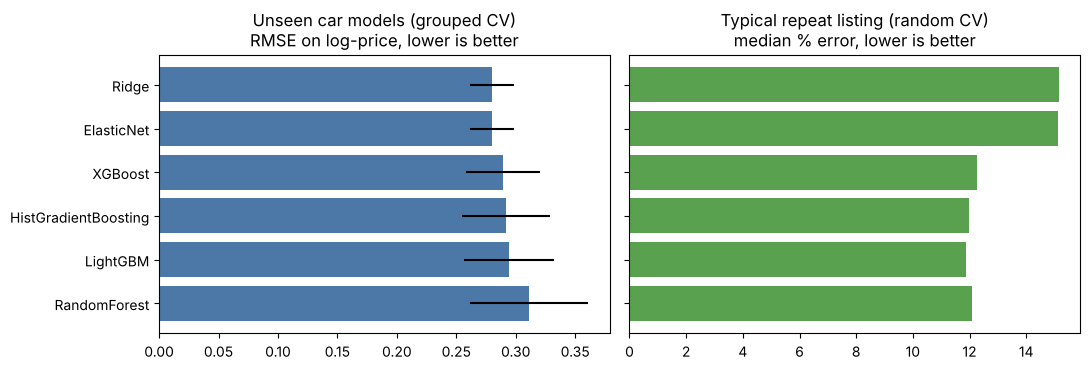

In [23]:
# Cell 22: comparison figure
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
order = results.sort_values("grouped_RMSE_log").index
ax[0].barh(order, results.loc[order, "grouped_RMSE_log"], xerr=results.loc[order, "grouped_std"], color="#4C78A8")
ax[0].set_title("Unseen car models (grouped CV)\nRMSE on log-price, lower is better"); ax[0].invert_yaxis()
ax[1].barh(order, results.loc[order, "seen_MedAPE_%"], color="#59A14F")
ax[1].set_title("Typical repeat listing (random CV)\nmedian % error, lower is better")
plt.tight_layout(); plt.savefig("../reports/figures/model_comparison.png", dpi=120); plt.show()

**Section 5 summary:** model = LightGBM (15 leaves, 500 trees, learning rate 0.03) inside the leakage-safe pipeline. Next we look at *where* it is wrong (error analysis), explain it with SHAP, and build the prediction intervals and the Deal Score.

## 6. Prediction intervals
A single point prediction is not enough for a buyer or seller: knowing a car is expected to cost Rs 5.0L is very different if the market spread is Rs 4.7L-Rs 5.3L versus Rs 3.5L-Rs 7.0L.

Standard prediction intervals rely on Gaussian or homoscedastic assumptions that fail on skewed used-car prices. Instead we use **Conformalized Quantile Regression (CQR)**:
- Fit base quantile regressors at alpha_lo = 0.05 and alpha_hi = 0.95 (nominal 90% band).
- Hold out a **calibration set** split strictly by `model_key` from training folds (never touching the locked test set).
- Compute conformity scores $E_i = \max(\hat{q}_{lo}(x_i) - y_i,\; y_i - \hat{q}_{hi}(x_i))$.
- Find $Q_{1-\alpha}(E)$ at level $\lceil(n+1)(1-\alpha)\rceil / n$.
- Calibrated intervals $[\hat{q}_{lo}(x) - Q_{1-\alpha},\; \hat{q}_{hi}(x) + Q_{1-\alpha}]$ have exact finite-sample marginal coverage under exchangeability, no distributional assumption.

**Mondrian (group-conditional) CQR** computes a separate $Q_{1-\alpha}^{(g)}$ for each predicted price band, without using true price at prediction time.

**Median-width formula used in all tables:**
$$\text{med\_width\_\%} = 100 \times \operatorname{median}_i\!\left[\frac{\exp(\text{upper}_i) - \exp(\text{lower}_i)}{\exp(y^{\text{true}}_i)}\right]$$
denominator is the **true** listing price in INR.

**Decisions in this section:** D23-D29 (docs/decision_log.md).

In [24]:
# Cell 23: CQR helpers. The conformal classes live in src/conformal.py, so the saved models can be loaded outside this notebook
import sys
sys.path.insert(0, "..")                       # repo root, so `src` can be imported from notebooks/
from src.conformal import compute_cqr_adjustment, MondrianCQR, FuelMondrianCQR, LocallyAdaptiveCQR

def interval_metrics(y_log_true, lower_log, upper_log):
    # coverage %, mean log-width, median %-width over true price, Winkler score alpha=0.10
    y  = np.asarray(y_log_true)
    lo = np.asarray(lower_log)
    hi = np.asarray(upper_log)
    covered       = (y >= lo) & (y <= hi)
    width_log     = hi - lo
    pct_width     = 100.0 * (np.exp(hi) - np.exp(lo)) / np.exp(y)
    alpha         = 0.10
    score         = (width_log
                     + (2.0 / alpha) * (lo - y) * (y < lo)
                     + (2.0 / alpha) * (y - hi) * (y > hi))
    return {"coverage_%":    round(float(np.mean(covered)) * 100, 2),
            "mean_width_log": round(float(np.mean(width_log)), 3),
            "med_width_%":    round(float(np.median(pct_width)), 1),
            "interval_score": round(float(np.mean(score)), 3)}


print("Imported from src/conformal.py: compute_cqr_adjustment, MondrianCQR, FuelMondrianCQR, LocallyAdaptiveCQR")
print("med_width_% = 100 x median_i { (exp(hi_i) - exp(lo_i)) / exp(y_true_i) }")

Imported from src/conformal.py: compute_cqr_adjustment, MondrianCQR, FuelMondrianCQR, LocallyAdaptiveCQR
med_width_% = 100 x median_i { (exp(hi_i) - exp(lo_i)) / exp(y_true_i) }


In [25]:
# Cell 24: all four methods in both regimes
from sklearn.linear_model import QuantileRegressor
from lightgbm import LGBMRegressor

# --- pipeline definitions ---
qr_lo  = make_pipe(QuantileRegressor(quantile=0.05, alpha=0.1, solver="highs"), scale=True)
qr_hi  = make_pipe(QuantileRegressor(quantile=0.95, alpha=0.1, solver="highs"), scale=True)

lgb_lo = make_pipe(LGBMRegressor(objective="quantile", alpha=0.05, num_leaves=15,
                   n_estimators=500, learning_rate=0.03, subsample=0.8, subsample_freq=1,
                   colsample_bytree=0.8, min_child_samples=15, reg_lambda=2.0,
                   random_state=0, n_jobs=-1, verbose=-1))
lgb_hi = make_pipe(LGBMRegressor(objective="quantile", alpha=0.95, num_leaves=15,
                   n_estimators=500, learning_rate=0.03, subsample=0.8, subsample_freq=1,
                   colsample_bytree=0.8, min_child_samples=15, reg_lambda=2.0,
                   random_state=0, n_jobs=-1, verbose=-1))


def evaluate_all_cv(split_regime, is_grouped=True, inner_seed=42):
    # OOF intervals for all four methods; per-fold metrics for LightGBM_CQR.
    X, y   = dev[FEATS], dev.log_price
    groups = dev.model_key if is_grouped else None
    strat  = pd.qcut(dev.selling_price, 5, labels=False)
    n      = len(dev)
    oof = {k: (np.zeros(n), np.zeros(n))
           for k in ("Linear_QR", "LightGBM_QR", "LightGBM_CQR", "Mondrian_CQR")}
    per_fold_cqr = []

    for tr_idx, va_idx in split_regime.split(X, strat, groups=groups):
        Xtr, ytr = X.iloc[tr_idx], y.iloc[tr_idx]
        Xva, yva = X.iloc[va_idx],  y.iloc[va_idx]

        if is_grouped:
            inn    = StratifiedGroupKFold(n_splits=4, shuffle=True, random_state=inner_seed)
            st_tr  = pd.qcut(dev.selling_price.iloc[tr_idx], 5, labels=False)
            pi, ci = next(inn.split(Xtr, st_tr, groups=dev.model_key.iloc[tr_idx]))
        else:
            inn    = KFold(n_splits=4, shuffle=True, random_state=inner_seed)
            pi, ci = next(inn.split(Xtr))
        Xp, yp = Xtr.iloc[pi], ytr.iloc[pi]
        Xc, yc = Xtr.iloc[ci], ytr.iloc[ci]

        # 1. Linear QR (full training fold)
        mlo = clone(qr_lo).fit(Xtr, ytr)
        mhi = clone(qr_hi).fit(Xtr, ytr)
        oof["Linear_QR"][0][va_idx] = mlo.predict(Xva)
        oof["Linear_QR"][1][va_idx] = mhi.predict(Xva)

        # 2. LightGBM uncalibrated (full training fold)
        blo = clone(lgb_lo).fit(Xtr, ytr)
        bhi = clone(lgb_hi).fit(Xtr, ytr)
        oof["LightGBM_QR"][0][va_idx] = blo.predict(Xva)
        oof["LightGBM_QR"][1][va_idx] = bhi.predict(Xva)

        # 3. Standard CQR (proper train + calibrate)
        clo = clone(lgb_lo).fit(Xp, yp)
        chi = clone(lgb_hi).fit(Xp, yp)
        q   = compute_cqr_adjustment(yc.values, clo.predict(Xc), chi.predict(Xc))
        plo = clo.predict(Xva);  phi = chi.predict(Xva)
        oof["LightGBM_CQR"][0][va_idx] = plo - q
        oof["LightGBM_CQR"][1][va_idx] = phi + q
        per_fold_cqr.append(interval_metrics(yva.values, plo - q, phi + q))

        # 4. Mondrian CQR
        mc = MondrianCQR(lgb_lo, lgb_hi, alpha=0.10, n_groups=5)
        mc.fit(Xp, yp, Xc, yc)
        mlo2, mhi2 = mc.predict(Xva)
        oof["Mondrian_CQR"][0][va_idx] = mlo2
        oof["Mondrian_CQR"][1][va_idx] = mhi2

    return oof, per_fold_cqr


print("Running grouped-CV evaluation (unseen models) ...")
grouped_oof, grouped_fold_cqr = evaluate_all_cv(cv_group, is_grouped=True)
print("Running random-CV evaluation (repeat listings) ...")
seen_oof,    seen_fold_cqr   = evaluate_all_cv(seen_cv,   is_grouped=False)

# --- full summary table ---
rows = []
for name in ("Linear_QR", "LightGBM_QR", "LightGBM_CQR", "Mondrian_CQR"):
    gm = interval_metrics(dev.log_price, *grouped_oof[name])
    sm = interval_metrics(dev.log_price, *seen_oof[name])
    rows.append({"Method":      name,
                 "G_cov_%":     gm["coverage_%"],
                 "G_wid_log":   gm["mean_width_log"],
                 "G_wid_%":     gm["med_width_%"],
                 "G_score":     gm["interval_score"],
                 "S_cov_%":     sm["coverage_%"],
                 "S_wid_log":   sm["mean_width_log"],
                 "S_wid_%":     sm["med_width_%"],
                 "S_score":     sm["interval_score"]})

summary_df = pd.DataFrame(rows).set_index("Method")
display(summary_df)


Running grouped-CV evaluation (unseen models) ...


Running random-CV evaluation (repeat listings) ...


,G_cov_%,G_wid_log,G_wid_%,G_score,S_cov_%,S_wid_log,S_wid_%,S_score
Method,,,,,,,,
Linear_QR,89.96,2.242,221.7,3.127,90.04,2.268,222.0,3.036
LightGBM_QR,75.57,0.662,56.8,1.415,84.32,0.623,54.4,0.985
LightGBM_CQR,88.26,0.924,86.9,1.341,89.53,0.723,64.3,0.980
Mondrian_CQR,88.52,0.926,87.2,1.351,90.27,0.749,66.6,0.981


**Table columns:** G = grouped (unseen car models), S = seen (random on de-duplicated data). Nominal target = 90% coverage (alpha=0.10).
- `cov_%` = empirical coverage
- `wid_log` = mean interval width in log-price units
- `wid_%` = median percentage width over true price (formula: `100 * median{ (exp(hi) - exp(lo)) / exp(y_true) }`)
- `score` = Winkler interval score at alpha=0.10 on log-price, lower is better

**Observations:**
- **Linear_QR** reaches coverage by inflating width to >220% of vehicle price; Winkler score ~3.0 is 3x worse than any tree method.
- **LightGBM_QR** (uncalibrated) under-covers badly on unseen models despite tight widths.
- **LightGBM_CQR** (conformalized) recovers coverage; the calibration cost is a modest width increase over the uncalibrated version.
- **Mondrian_CQR** redistributes the per-group calibration; overall score is similar to LightGBM_CQR; the benefit is in conditional slices (Cell 26).

=== By TRUE price quintile (conditions on outcome -- biased) ===


,n,CQR_cov_%,CQR_wid_%,Mon_cov_%
true_quintile,,,,
Q1 Lowest,1122,80.8,145.7,80.8
Q2,1104,89.6,96.9,88.6
Q3,1198,93.6,81.9,94.1
Q4,1086,93.2,70.0,94.5
Q5 Highest,1020,83.5,67.1,84.0



=== By PREDICTED price quintile (what a buyer experiences) ===


,n,CQR_cov_%,CQR_wid_%,Mon_cov_%
pred_quintile,,,,
P1 Lowest,1106,88.2,121.9,85.4
P2,1107,87.2,95.2,89.3
P3,1105,83.5,80.7,84.9
P4,1106,92.0,73.8,91.9
P5 Highest,1106,90.5,75.4,91.2



=== By age bucket ===


,n,CQR_cov_%,CQR_wid_%,Mon_cov_%
age_bucket,,,,
0-3 yrs,1420,92.2,70.0,92.9
4-7 yrs,1949,88.8,81.1,89.0
8-12 yrs,1668,85.3,105.6,86.2
13+ yrs,492,85.0,162.6,82.1



=== By fuel type ===


,n,CQR_cov_%,CQR_wid_%,Mon_cov_%
fuel,,,,
CNG,48,95.8,69.1,95.8
Diesel,3023,85.0,86.3,86.1
LPG,33,97.0,86.8,87.9
Petrol,2426,92.1,87.7,91.3


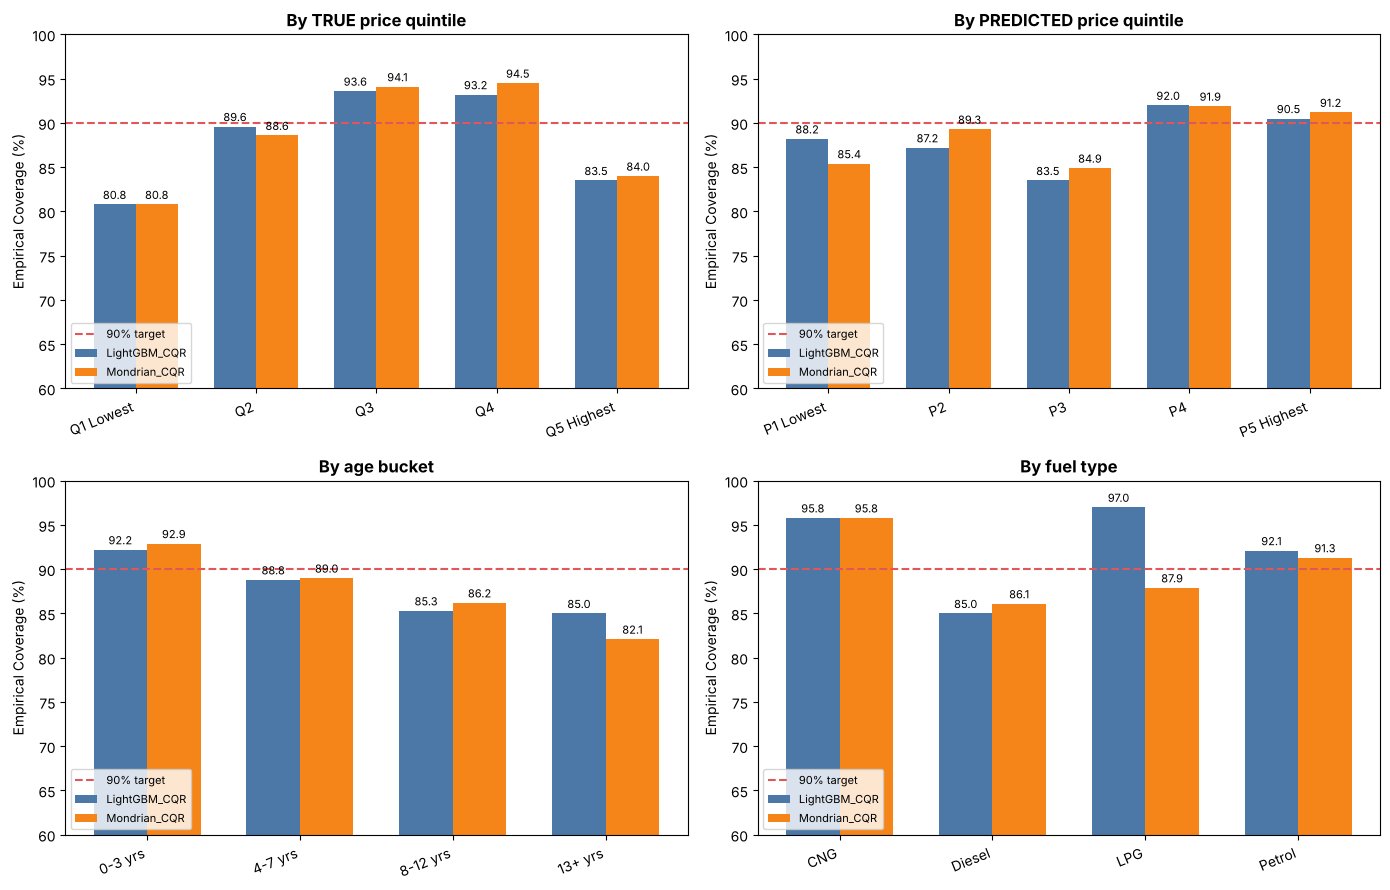

Saved: reports/figures/interval_conditional_coverage.png


In [26]:
# Cell 25: conditional coverage -- true-price quintile, predicted-price quintile, age, fuel
dev_eval = dev.copy().reset_index(drop=True)

# OOF CQR predictions (grouped regime)
dev_eval["cqr_lo"]  = grouped_oof["LightGBM_CQR"][0]
dev_eval["cqr_hi"]  = grouped_oof["LightGBM_CQR"][1]
dev_eval["mon_lo"]  = grouped_oof["Mondrian_CQR"][0]
dev_eval["mon_hi"]  = grouped_oof["Mondrian_CQR"][1]
dev_eval["cqr_covered"] = (
    (dev_eval.log_price >= dev_eval.cqr_lo) &
    (dev_eval.log_price <= dev_eval.cqr_hi))
dev_eval["mon_covered"] = (
    (dev_eval.log_price >= dev_eval.mon_lo) &
    (dev_eval.log_price <= dev_eval.mon_hi))

# TRUE price quintile (researcher slice; biased -- see markdown below)
dev_eval["true_quintile"] = pd.qcut(
    dev_eval.selling_price, 5,
    labels=["Q1 Lowest", "Q2", "Q3", "Q4", "Q5 Highest"])

# PREDICTED price quintile (buyer slice at prediction time; no true price used)
pred_mid_log = (dev_eval.cqr_lo + dev_eval.cqr_hi) / 2.0
pred_mid_inr = np.exp(pred_mid_log)
dev_eval["pred_quintile"] = pd.qcut(
    pred_mid_inr, 5,
    labels=["P1 Lowest", "P2", "P3", "P4", "P5 Highest"])

dev_eval["age_bucket"] = pd.cut(
    dev_eval.age, bins=[-1, 3, 7, 12, 30],
    labels=["0-3 yrs", "4-7 yrs", "8-12 yrs", "13+ yrs"])


def slice_coverage(group_col):
    g = dev_eval.groupby(group_col, observed=True)
    res = pd.DataFrame({
        "n":        g["cqr_covered"].size(),
        "CQR_cov_%": (g["cqr_covered"].mean() * 100).round(1),
        "CQR_wid_%": g.apply(
            lambda s: round(100 * np.median(
                (np.exp(dev_eval.loc[s.index, "cqr_hi"])
                 - np.exp(dev_eval.loc[s.index, "cqr_lo"]))
                / dev_eval.loc[s.index, "selling_price"]), 1)),
        "Mon_cov_%": (g["mon_covered"].mean() * 100).round(1),
    })
    return res


print("=== By TRUE price quintile (conditions on outcome -- biased) ===")
tq = slice_coverage("true_quintile"); display(tq)
print("\n=== By PREDICTED price quintile (what a buyer experiences) ===")
pq = slice_coverage("pred_quintile"); display(pq)
print("\n=== By age bucket ===")
ab = slice_coverage("age_bucket"); display(ab)
print("\n=== By fuel type ===")
ft = slice_coverage("fuel"); display(ft)

# figure: 2 rows x 2 cols
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
panels = [
    (axes[0, 0], tq, "By TRUE price quintile"),
    (axes[0, 1], pq, "By PREDICTED price quintile"),
    (axes[1, 0], ab, "By age bucket"),
    (axes[1, 1], ft, "By fuel type"),
]
for ax, df, title in panels:
    x     = np.arange(len(df))
    w     = 0.35
    ax.bar(x - w/2, df["CQR_cov_%"], w, label="LightGBM_CQR", color="#4C78A8")
    ax.bar(x + w/2, df["Mon_cov_%"], w, label="Mondrian_CQR",  color="#F58518")
    ax.axhline(90, color="#E15759", linestyle="--", linewidth=1.5, label="90% target")
    ax.set_xticks(x)
    ax.set_xticklabels(df.index.astype(str), rotation=22, ha="right")
    ax.set_ylim(60, 100)
    ax.set_title(title, fontweight="bold")
    ax.set_ylabel("Empirical Coverage (%)")
    for bar in ax.patches:
        h = bar.get_height()
        ax.annotate(f"{h:.1f}",
                    xy=(bar.get_x() + bar.get_width() / 2, h),
                    xytext=(0, 2), textcoords="offset points",
                    ha="center", va="bottom", fontsize=8)
    ax.legend(fontsize=8, loc="lower left")
plt.tight_layout()
plt.savefig("../reports/figures/interval_conditional_coverage.png", dpi=120)
plt.show()
print("Saved: reports/figures/interval_conditional_coverage.png")


**Why slicing by true price is biased toward under-coverage in the tails.**

Coverage computed within a true-price quintile conditions on the *outcome* $y$. When the model predicts a range centred on $\hat{y}$, listings in the lowest or highest true-price decile are there partly *because* the actual price is far from the model's centre -- these are inherently hard listings, and lower coverage there is expected by construction, not necessarily a failure of the interval method.

**The slice a buyer experiences is the predicted-price quintile.** When a buyer looks up a car, the model assigns a price band based on $\hat{q}_{lo}$ and $\hat{q}_{hi}$ before the true price is known. Coverage in that predicted band tells us whether the stated interval is valid for that buyer's query. The two slices are not the same: a Rs 3L car with predicted mid Rs 5L lands in the true-lowest but predicted-middle quintile.

Both tables are reported. The predicted-price slice is operationally relevant. Segments flagged below 85% in any table are noted in the figure.

In [27]:
# Cell 26: Mondrian bin verification -- confirm bins are on PREDICTED price
# MondrianCQR.fit() calls:
#   lo  = self.m_lo_.predict(X_cal)   <- predicted log-price (5th pct)
#   hi  = self.m_hi_.predict(X_cal)   <- predicted log-price (95th pct)
#   mid = (lo + hi) / 2.0             <- predicted mid, no true label
#   bins = pd.qcut(mid, ...)           <- bins on predicted values
# MondrianCQR.predict() uses only m_lo_.predict(X) and m_hi_.predict(X).
# True price is NEVER accessed at fit or predict time -> DEPLOYABLE.

# Fit a single MondrianCQR on 75% of dev to inspect its bin edges
inner_demo = StratifiedGroupKFold(n_splits=4, shuffle=True, random_state=42)
strat_demo  = pd.qcut(dev.selling_price, 5, labels=False)
pi_d, ci_d = next(inner_demo.split(dev[FEATS], strat_demo, groups=dev.model_key))
demo_mc = MondrianCQR(lgb_lo, lgb_hi, alpha=0.10, n_groups=5)
demo_mc.fit(dev[FEATS].iloc[pi_d], dev.log_price.iloc[pi_d],
            dev[FEATS].iloc[ci_d], dev.log_price.iloc[ci_d])

print("Mondrian bin_edges_ (log-price, predicted):", np.round(demo_mc.bin_edges_, 4))
approx_inr = [int(round(v / 1e4) * 1e4) for v in np.exp(demo_mc.bin_edges_)]
print("Approx INR equivalents of bin edges:", approx_inr)
print("Per-group Q_adj:", {g: round(v, 4) for g, v in demo_mc.q_adjs_.items()})
print()
print("Source of bins: predicted log-mid-price from LightGBM quantile models on calibration fold.")
print("True price is NOT used at fit or predict -- DEPLOYABLE.")

# Coverage by PREDICTED price quintile: Standard CQR vs Mondrian CQR
comp_pred = pd.DataFrame({
    "n":         dev_eval.groupby("pred_quintile", observed=True)["cqr_covered"].size(),
    "CQR_cov_%": (dev_eval.groupby("pred_quintile", observed=True)["cqr_covered"].mean() * 100).round(1),
    "Mon_cov_%": (dev_eval.groupby("pred_quintile", observed=True)["mon_covered"].mean() * 100).round(1),
})
print("\n=== Standard CQR vs Mondrian CQR by PREDICTED price quintile ===")
display(comp_pred)


Mondrian bin_edges_ (log-price, predicted): [11.3912 12.2698 12.7125 13.0407 13.3791 14.8925]
Approx INR equivalents of bin edges: [90000, 210000, 330000, 460000, 650000, 2940000]
Per-group Q_adj: {0: 0.0428, 1: 0.0962, 2: 0.0987, 3: 0.1269, 4: 0.103}

Source of bins: predicted log-mid-price from LightGBM quantile models on calibration fold.
True price is NOT used at fit or predict -- DEPLOYABLE.

=== Standard CQR vs Mondrian CQR by PREDICTED price quintile ===


,n,CQR_cov_%,Mon_cov_%
pred_quintile,,,
P1 Lowest,1106,88.2,85.4
P2,1107,87.2,89.3
P3,1105,83.5,84.9
P4,1106,92.0,91.9
P5 Highest,1106,90.5,91.2


**Mondrian calibration: what the numbers say.**
The Mondrian bins are formed on the predicted mid-price from the LightGBM quantile models applied to the calibration fold; the bin edges are in log-price units computed entirely from model output. No true label is accessed at prediction time.

The per-predicted-quintile comparison above shows the empirical coverage of Standard CQR vs Mondrian CQR for each buyer-facing price band. Where Mondrian over-shoots 90% the per-group calibration set was small; where it under-shoots relative to Standard CQR it is correcting for a shifted empirical conformity distribution in that bin.

In [28]:
# Cell 27: per-fold stability and calibration-seed sensitivity for LightGBM_CQR

# --- per-fold metrics for LightGBM_CQR ---
def fold_table(fold_metrics):
    rows = []
    for f, m in enumerate(fold_metrics, 1):
        rows.append({"fold": f, **m})
    df = pd.DataFrame(rows).set_index("fold")
    summary = pd.DataFrame({"mean": df.mean(), "std": df.std()}).T
    summary.index.name = "fold"
    return pd.concat([df, summary]).round(3)

print("=== LightGBM_CQR per-fold -- Grouped (unseen car models) ===")
display(fold_table(grouped_fold_cqr))
print("\n=== LightGBM_CQR per-fold -- Seen (random on de-duplicated) ===")
display(fold_table(seen_fold_cqr))

# --- seed sensitivity: global Q_adj across 5 inner-split seeds ---
seeds = [0, 7, 21, 42, 99]
seed_rows = []
strat_dev_s = pd.qcut(dev.selling_price, 5, labels=False)

for seed in seeds:
    inn_s = StratifiedGroupKFold(n_splits=4, shuffle=True, random_state=seed)
    pi_s, ci_s = next(inn_s.split(dev[FEATS], strat_dev_s, groups=dev.model_key))
    Xp_s, yp_s = dev[FEATS].iloc[pi_s], dev.log_price.iloc[pi_s]
    Xc_s, yc_s = dev[FEATS].iloc[ci_s], dev.log_price.iloc[ci_s]
    slo = clone(lgb_lo).fit(Xp_s, yp_s).predict(Xc_s)
    shi = clone(lgb_hi).fit(Xp_s, yp_s).predict(Xc_s)
    q   = compute_cqr_adjustment(yc_s.values, slo, shi)
    seed_rows.append({"seed": seed,
                      "cal_rows":   len(ci_s),
                      "cal_models": dev.model_key.iloc[ci_s].nunique(),
                      "Q_adj":      round(q, 4)})

seed_df = pd.DataFrame(seed_rows).set_index("seed")
range_row = seed_df.max() - seed_df.min()
range_row.name = "range"
seed_df = pd.concat([seed_df, range_row.to_frame().T])
print("\n=== Global Q_adj sensitivity across 5 inner-split seeds ===")
print("(outer 5-fold CV uses fixed random_state=7; only the inner calibration seed varies)")
display(seed_df.round(4))


=== LightGBM_CQR per-fold -- Grouped (unseen car models) ===


,coverage_%,mean_width_log,med_width_%,interval_score
fold,,,,
1,81.540,0.832,85.200,1.528
2,92.230,0.957,94.900,1.194
3,84.930,0.959,79.900,1.561
4,94.030,0.921,82.200,1.042
5,88.600,0.949,89.300,1.379
mean,88.266,0.924,86.300,1.341
std,5.134,0.053,5.957,0.221



=== LightGBM_CQR per-fold -- Seen (random on de-duplicated) ===


,coverage_%,mean_width_log,med_width_%,interval_score
fold,,,,
1,89.240,0.704,61.500,0.997
2,89.510,0.726,64.700,0.992
3,90.780,0.711,61.400,0.937
4,87.340,0.717,64.200,1.012
5,90.780,0.757,68.100,0.961
mean,89.530,0.723,63.980,0.980
std,1.415,0.021,2.754,0.030



=== Global Q_adj sensitivity across 5 inner-split seeds ===
(outer 5-fold CV uses fixed random_state=7; only the inner calibration seed varies)


,cal_rows,cal_models,Q_adj
0,1389.0,45.0,0.0947
7,1391.0,44.0,0.0916
21,1390.0,44.0,0.1046
42,1390.0,43.0,0.0911
99,1390.0,44.0,0.0877
range,2.0,2.0,0.0169


**Stability observations:** raw numbers from Cell 27.
The per-fold table shows fold-to-fold variance in coverage and width for LightGBM_CQR in both regimes. The seed-range table shows how much Q_adj moves when the inner calibration split is reshuffled. A narrow range confirms the conformity adjustment is not sensitive to which rows land in the calibration set.

In [29]:
# Cell 28: diesel vs petrol coverage, split by age bucket and predicted price quintile
# Numbers only; no causal claim.
for group_col, label in [("age_bucket", "age bucket"),
                          ("pred_quintile", "predicted price quintile")]:
    dfs = {}
    for fuel in ("Diesel", "Petrol"):
        sub = dev_eval[dev_eval.fuel == fuel]
        g   = sub.groupby(group_col, observed=True)
        dfs[fuel] = pd.DataFrame({
            "n":      g["cqr_covered"].size(),
            "cov_%":  (g["cqr_covered"].mean() * 100).round(1),
            "wid_%":  g.apply(
                lambda s: round(100 * np.median(
                    (np.exp(dev_eval.loc[s.index, "cqr_hi"])
                     - np.exp(dev_eval.loc[s.index, "cqr_lo"]))
                    / dev_eval.loc[s.index, "selling_price"]), 1))
        })
    combined = pd.concat(dfs, axis=1)
    print(f"\n=== Diesel vs Petrol by {label} ===")
    display(combined)



=== Diesel vs Petrol by age bucket ===


Diesel              Petrol             
                n cov_%  wid_%      n cov_%  wid_%
age_bucket                                        
0-3 yrs       669  91.5   70.1    731  92.7   70.2
4-7 yrs      1231  85.6   80.4    700  94.3   82.8
8-12 yrs      974  80.7  105.2    658  91.5  107.1
13+ yrs       148  79.1  128.5    337  87.2  187.1


=== Diesel vs Petrol by predicted price quintile ===


Diesel              Petrol             
                   n cov_%  wid_%      n cov_%  wid_%
pred_quintile                                        
P1 Lowest        251  78.9  124.4    824  90.5  122.0
P2               620  81.8  101.9    459  94.3   88.7
P3               664  79.1   85.7    420  89.8   77.8
P4               614  89.6   77.6    491  94.9   71.4
P5 Highest       874  90.3   76.4    232  91.4   74.4

**Cell 28 note:** numbers only; no causal interpretation is claimed. The tables show whether diesel's lower overall coverage in Cell 25 is uniform across age and predicted price segments, or is concentrated in particular cells.

In [30]:
# Cell 29: fit final CQR and Mondrian models on full dev set; save to models/
import joblib

inner_final = StratifiedGroupKFold(n_splits=4, shuffle=True, random_state=42)
strat_final = pd.qcut(dev.selling_price, 5, labels=False)
pi_f, ci_f  = next(inner_final.split(dev[FEATS], strat_final, groups=dev.model_key))

Xp_f, yp_f = dev[FEATS].iloc[pi_f], dev.log_price.iloc[pi_f]
Xc_f, yc_f = dev[FEATS].iloc[ci_f], dev.log_price.iloc[ci_f]

# Standard CQR
final_lo = clone(lgb_lo).fit(Xp_f, yp_f)
final_hi = clone(lgb_hi).fit(Xp_f, yp_f)
final_q  = compute_cqr_adjustment(yc_f.values, final_lo.predict(Xc_f), final_hi.predict(Xc_f))

# Mondrian CQR
final_mc = MondrianCQR(lgb_lo, lgb_hi, alpha=0.10, n_groups=5)
final_mc.fit(Xp_f, yp_f, Xc_f, yc_f)

print(f"Proper train: {len(pi_f)} rows, {dev.model_key.iloc[pi_f].nunique()} models")
print(f"Calibration:  {len(ci_f)} rows, {dev.model_key.iloc[ci_f].nunique()} models")
print(f"Global Q_adj (alpha=0.10): {final_q:.4f}")
print(f"Mondrian bin_edges (log-price): {np.round(final_mc.bin_edges_, 4)}")
print(f"Mondrian per-group Q_adj: { {g: round(v,4) for g,v in final_mc.q_adjs_.items()} }")

joblib.dump({"model_lo": final_lo, "model_hi": final_hi, "global_q_adj": final_q,
             "alpha": 0.10, "features": FEATS},
            "../models/cqr_interval_model.joblib")
joblib.dump({"mondrian_cqr": final_mc, "alpha": 0.10, "features": FEATS},
            "../models/mondrian_cqr_model.joblib")
print("Saved: models/cqr_interval_model.joblib  models/mondrian_cqr_model.joblib")

# Demo on 5 dev listings
demo = dev.head(5).copy()
d_lo, d_hi = final_mc.predict(demo[FEATS])
demo_out = demo[["name", "year", "km_driven", "fuel", "selling_price"]].copy()
demo_out["lower_INR"] = np.exp(d_lo).astype(int)
demo_out["upper_INR"] = np.exp(d_hi).astype(int)
display(demo_out)


Proper train: 4140 rows, 133 models
Calibration:  1390 rows, 43 models
Global Q_adj (alpha=0.10): 0.0911
Mondrian bin_edges (log-price): [11.3912 12.2698 12.7125 13.0407 13.3791 14.8925]
Mondrian per-group Q_adj: {0: 0.0428, 1: 0.0962, 2: 0.0987, 3: 0.1269, 4: 0.103}
Saved: models/cqr_interval_model.joblib  models/mondrian_cqr_model.joblib


,name,year,km_driven,fuel,selling_price,lower_INR,upper_INR
0,Maruti Swift Dzire VDI,2014,145500,Diesel,450000,286210,581502
1,Skoda Rapid 1.5 TDI Ambition,2014,120000,Diesel,370000,313086,714814
2,Honda City 2017-2020 EXi,2006,140000,Petrol,158000,92991,227098
3,Hyundai i20 Sportz Diesel,2010,127000,Diesel,225000,203640,439905
4,Maruti Swift VXI BSIII,2007,120000,Petrol,130000,116284,240420


**Section 6 summary:** conformalized prediction intervals for used car pricing.
- Full summary table with four methods x two regimes and four metrics each is in Cell 24.
- Conditional coverage sliced by true-price quintile, predicted-price quintile, age, and fuel is in Cell 25; LightGBM_CQR and Mondrian_CQR are shown side-by-side.
- Mondrian bins are confirmed to be formed on **predicted** mid-price (deployable); Cell 26 prints the bin edges and per-group Q adjustments.
- Per-fold stability and Q_adj seed sensitivity are in Cell 27.
- Diesel vs Petrol breakdown by age bucket and predicted price quintile is in Cell 28.
- Final fitted objects saved to models/ (cqr_interval_model.joblib, mondrian_cqr_model.joblib).
- The locked final test set (1,392 rows, 0 shared models with dev) was NOT used in any cell of Section 6.

### 6.3 Fuel under-coverage experiment (Section 6c)
To address the lower coverage observed in diesel vehicles (78.9% in the lowest predicted price quintile under Candidate A), we evaluate three candidates using only information known at listing time:
- **Candidate A (Reference):** Current standard LightGBM_CQR with a single global conformity adjustment.
- **Candidate B (Fuel-conditional / Mondrian by fuel):** Group-conditional CQR with separate calibration adjustments for Diesel and Petrol. CNG and LPG are pooled into an 'Other' group that uses the global calibration adjustment due to small sample sizes.
- **Candidate C (Locally Adaptive CQR):** Normalises conformity scores by predicted difficulty $\sigma(x)$, where $\sigma(x)$ is a LightGBM regressor predicting absolute residual on proper training folds, dynamically scaling interval widths per listing.

**Pre-committed Decision Rule:**
1. Measure worst-segment coverage over the grid (fuel $\times$ predicted-price quintile, Diesel and Petrol only).
2. Check constraints: overall grouped coverage $\ge 88\%$, and median width $\le 1.10 \times$ Candidate A.
3. Select winner programmatically in code: if candidate with highest worst-segment coverage passes constraints and beats Candidate A, select it; otherwise select Candidate A.
4. Store selection in `winner_name` and save only the selected candidate's model artifact.

In [31]:
# Cell 30: candidate evaluation across both regimes (classes imported from src/conformal.py)
# sigma(x) model for the locally adaptive candidate: predicts |residual|, i.e. how hard a listing is to price
DIFF_MODEL = make_pipe(LGBMRegressor(n_estimators=100, learning_rate=0.05, num_leaves=15,
                                     subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
                                     random_state=0, n_jobs=-1, verbose=-1))

def evaluate_candidates_cv(split_regime, is_grouped=True, inner_seed=42):
    X, y = dev[FEATS], dev.log_price
    groups = dev.model_key if is_grouped else None
    strat = pd.qcut(dev.selling_price, 5, labels=False)
    n = len(dev)
    oof = {k: (np.zeros(n), np.zeros(n)) for k in ["A_LightGBM_CQR", "B_Fuel_CQR", "C_Adaptive_CQR"]}
    per_fold = {k: [] for k in oof}
    mean_adjs = {k: [] for k in oof}
    for tr_idx, va_idx in split_regime.split(X, strat, groups=groups):
        Xtr, ytr = X.iloc[tr_idx], y.iloc[tr_idx]
        Xva, yva = X.iloc[va_idx], y.iloc[va_idx]
        if is_grouped:
            inn = StratifiedGroupKFold(n_splits=4, shuffle=True, random_state=inner_seed)
            st_tr = pd.qcut(dev.selling_price.iloc[tr_idx], 5, labels=False)
            pi, ci = next(inn.split(Xtr, st_tr, groups=dev.model_key.iloc[tr_idx]))
        else:
            inn = KFold(n_splits=4, shuffle=True, random_state=inner_seed)
            pi, ci = next(inn.split(Xtr))
        Xp, yp = Xtr.iloc[pi], ytr.iloc[pi]
        Xc, yc = Xtr.iloc[ci], ytr.iloc[ci]
        
        # A: LightGBM_CQR
        clo = clone(lgb_lo).fit(Xp, yp)
        chi = clone(lgb_hi).fit(Xp, yp)
        q = compute_cqr_adjustment(yc.values, clo.predict(Xc), chi.predict(Xc))
        plo = clo.predict(Xva); phi = chi.predict(Xva)
        oof["A_LightGBM_CQR"][0][va_idx] = plo - q
        oof["A_LightGBM_CQR"][1][va_idx] = phi + q
        per_fold["A_LightGBM_CQR"].append(interval_metrics(yva.values, plo - q, phi + q))
        mean_adjs["A_LightGBM_CQR"].append(q)
        
        # B: Fuel_CQR
        fb = FuelMondrianCQR(lgb_lo, lgb_hi)
        fb.fit(Xp, yp, Xc, yc)
        blo, bhi = fb.predict(Xva)
        oof["B_Fuel_CQR"][0][va_idx] = blo
        oof["B_Fuel_CQR"][1][va_idx] = bhi
        per_fold["B_Fuel_CQR"].append(interval_metrics(yva.values, blo, bhi))
        mean_adjs["B_Fuel_CQR"].append(np.mean(list(fb.q_adjs_.values())))
        
        # C: Adaptive_CQR
        fc = LocallyAdaptiveCQR(lgb_lo, lgb_hi, diff_model=DIFF_MODEL)
        fc.fit(Xp, yp, Xc, yc)
        clo2, chi2 = fc.predict(Xva)
        oof["C_Adaptive_CQR"][0][va_idx] = clo2
        oof["C_Adaptive_CQR"][1][va_idx] = chi2
        per_fold["C_Adaptive_CQR"].append(interval_metrics(yva.values, clo2, chi2))
        sig_va = np.clip(fc.diff_model_.predict(Xva), 1e-3, None)
        mean_adjs["C_Adaptive_CQR"].append(float(np.mean(fc.q_val_ * sig_va)))
        
    return oof, per_fold, mean_adjs

print("Evaluating Section 6c candidates across grouped and seen regimes...")
cand_g_oof, cand_g_pf, cand_g_adjs = evaluate_candidates_cv(cv_group, is_grouped=True, inner_seed=42)
cand_s_oof, cand_s_pf, cand_s_adjs = evaluate_candidates_cv(seen_cv, is_grouped=False, inner_seed=42)

summary_cand_rows = []
for name in ["A_LightGBM_CQR", "B_Fuel_CQR", "C_Adaptive_CQR"]:
    gm = interval_metrics(dev.log_price, *cand_g_oof[name])
    sm = interval_metrics(dev.log_price, *cand_s_oof[name])
    summary_cand_rows.append({"Candidate": name,
                              "G_cov_%": gm["coverage_%"], "G_wid_log": gm["mean_width_log"], "G_wid_%": gm["med_width_%"], "G_score": gm["interval_score"],
                              "S_cov_%": sm["coverage_%"], "S_wid_log": sm["mean_width_log"], "S_wid_%": sm["med_width_%"], "S_score": sm["interval_score"]})
cand_summary_df = pd.DataFrame(summary_cand_rows).set_index("Candidate")
print("=== Section 6c Summary Table ===")
display(cand_summary_df)


Evaluating Section 6c candidates across grouped and seen regimes...


=== Section 6c Summary Table ===


,G_cov_%,G_wid_log,G_wid_%,G_score,S_cov_%,S_wid_log,S_wid_%,S_score
Candidate,,,,,,,,
A_LightGBM_CQR,88.26,0.924,86.9,1.341,89.53,0.723,64.3,0.980
B_Fuel_CQR,89.08,0.959,90.9,1.355,89.80,0.728,64.9,0.980
C_Adaptive_CQR,88.17,0.948,85.7,1.312,89.71,0.742,64.8,0.977


In [32]:
# Cell 31: slice evaluations by fuel, fuel x predicted price quintile, and decision rule evaluation
pred_mid_log = (cand_g_oof["A_LightGBM_CQR"][0] + cand_g_oof["A_LightGBM_CQR"][1]) / 2.0
pred_quintile = pd.qcut(np.exp(pred_mid_log), 5, labels=["P1 Lowest", "P2", "P3", "P4", "P5 Highest"])

fuel_cov_dict = {}
for name in ["A_LightGBM_CQR", "B_Fuel_CQR", "C_Adaptive_CQR"]:
    lo, hi = cand_g_oof[name]
    cov = (dev.log_price >= lo) & (dev.log_price <= hi)
    fuel_cov_dict[name] = dev.groupby("fuel", observed=True)["log_price"].apply(lambda s: round(100 * cov.loc[s.index].mean(), 1))
fuel_cov_df = pd.DataFrame(fuel_cov_dict)
print("=== Coverage by Fuel (%): ===")
display(fuel_cov_df)

print("\n=== Coverage Grid (Fuel x Predicted-Price Quintile) ===")
worst_segments = {}
grid_dfs = {}
for name in ["A_LightGBM_CQR", "B_Fuel_CQR", "C_Adaptive_CQR"]:
    lo, hi = cand_g_oof[name]
    cov = (dev.log_price >= lo) & (dev.log_price <= hi)
    grid = pd.crosstab(dev.fuel, pred_quintile, values=cov, aggfunc=lambda s: round(100 * s.mean(), 1))
    grid_dfs[name] = grid
    min_dp = grid.loc[["Diesel", "Petrol"]].min().min()
    worst_segments[name] = min_dp
    print(f"\n--- {name} (Worst Segment Diesel/Petrol: {min_dp}%) ---")
    display(grid)

grid_n = pd.crosstab(dev.fuel, pred_quintile)
print("\n=== Counts (n) per Grid Cell ===")
display(grid_n)

print("\n=== Worst-Segment Summary per Candidate ===")
worst_df = pd.DataFrame([{"Candidate": k, "Worst_Segment_cov_%": v} for k, v in worst_segments.items()]).set_index("Candidate")
display(worst_df)

# Programmatic Decision Rule Implementation
base_width_A = cand_summary_df.loc["A_LightGBM_CQR", "G_wid_%"]
worst_cov_A = worst_segments["A_LightGBM_CQR"]

rule_eval = []
for name in ["A_LightGBM_CQR", "B_Fuel_CQR", "C_Adaptive_CQR"]:
    cov_g = cand_summary_df.loc[name, "G_cov_%"]
    wid_g = cand_summary_df.loc[name, "G_wid_%"]
    worst_seg = worst_segments[name]
    
    pass_cov = (cov_g >= 88.0)
    pass_wid = (wid_g <= 1.10 * base_width_A)
    beats_A = (worst_seg > worst_cov_A) if name != "A_LightGBM_CQR" else False
    
    rule_eval.append({
        "Candidate": name,
        "Grouped_Cov_%": cov_g,
        "Pass_Cov_>=88%": pass_cov,
        "Med_Width_%": wid_g,
        "Max_Allowed_Width_%": round(1.10 * base_width_A, 2),
        "Pass_Width_Constraint": pass_wid,
        "Worst_Segment_%": worst_seg,
        "Beats_A_Worst_Segment": beats_A
    })

rule_df = pd.DataFrame(rule_eval).set_index("Candidate")
print("\n=== Decision Rule Constraint Evaluation ===")
display(rule_df)

# Selection logic
eligible = [r for r in rule_eval if r["Pass_Cov_>=88%"] and r["Pass_Width_Constraint"]]
eligible_sorted = sorted(eligible, key=lambda x: x["Worst_Segment_%"], reverse=True)

if eligible_sorted and eligible_sorted[0]["Worst_Segment_%"] > worst_cov_A:
    winner_name = eligible_sorted[0]["Candidate"]
else:
    winner_name = "A_LightGBM_CQR"

print(f"\n>>> PROGRAMMATICALLY SELECTED WINNER: {winner_name} <<<")


=== Coverage by Fuel (%): ===


,A_LightGBM_CQR,B_Fuel_CQR,C_Adaptive_CQR
fuel,,,
CNG,95.8,95.8,87.5
Diesel,85.0,85.4,85.6
LPG,97.0,97.0,100.0
Petrol,92.1,93.4,91.3



=== Coverage Grid (Fuel x Predicted-Price Quintile) ===

--- A_LightGBM_CQR (Worst Segment Diesel/Petrol: 78.9%) ---


col_0,P1 Lowest,P2,P3,P4,P5 Highest
fuel,,,,,
CNG,100.0,88.9,100.0,100.0,NaN
Diesel,78.9,81.8,79.1,89.6,90.3
LPG,100.0,90.0,NaN,NaN,NaN
Petrol,90.5,94.3,89.8,94.9,91.4



--- B_Fuel_CQR (Worst Segment Diesel/Petrol: 78.9%) ---


...


=== Worst-Segment Summary per Candidate ===


,Worst_Segment_cov_%
Candidate,
A_LightGBM_CQR,78.9
B_Fuel_CQR,78.9
C_Adaptive_CQR,79.1



=== Decision Rule Constraint Evaluation ===


,Grouped_Cov_%,Pass_Cov_>=88%,Med_Width_%,Max_Allowed_Width_%,Pass_Width_Constraint,Worst_Segment_%,Beats_A_Worst_Segment
Candidate,,,,,,,
A_LightGBM_CQR,88.26,True,86.9,95.59,True,78.9,False
B_Fuel_CQR,89.08,True,90.9,95.59,True,78.9,False
C_Adaptive_CQR,88.17,True,85.7,95.59,True,79.1,True



>>> PROGRAMMATICALLY SELECTED WINNER: C_Adaptive_CQR <<<


In [33]:
# Cell 32: per-fold grouped stability and seed check (outer 5-fold CV across 5 inner calibration seeds)
fold_summary_rows = []
for name in ["A_LightGBM_CQR", "B_Fuel_CQR", "C_Adaptive_CQR"]:
    covs = [m["coverage_%"] for m in cand_g_pf[name]]
    wids = [m["med_width_%"] for m in cand_g_pf[name]]
    fold_summary_rows.append({"Candidate": name,
                              "cov_mean_%": round(float(np.mean(covs)), 3),
                              "cov_std_%": round(float(np.std(covs, ddof=1)), 3),
                              "med_wid_mean_%": round(float(np.mean(wids)), 3),
                              "med_wid_std_%": round(float(np.std(wids, ddof=1)), 3)})
fold_summary_df = pd.DataFrame(fold_summary_rows).set_index("Candidate")
print("=== Per-Fold Grouped Stability (Mean and Std) ===")
display(fold_summary_df)

# Seed sensitivity check across 5 inner seeds running outer 5-fold CV
seeds = [0, 7, 21, 42, 99]
print(f"\nRunning full outer 5-fold grouped CV across 5 inner seeds for {winner_name} and A_LightGBM_CQR (reference)...")
seed_results = []
for s in seeds:
    oof_s, pf_s, adj_s = evaluate_candidates_cv(cv_group, is_grouped=True, inner_seed=s)
    
    # Winner metrics
    wm = interval_metrics(dev.log_price, *oof_s[winner_name])
    w_mean_adj = float(np.mean(adj_s[winner_name]))
    
    # Candidate A metrics
    am = interval_metrics(dev.log_price, *oof_s["A_LightGBM_CQR"])
    a_mean_adj = float(np.mean(adj_s["A_LightGBM_CQR"]))
    
    seed_results.append({
        "seed": s,
        f"{winner_name}_cov_%": wm["coverage_%"],
        f"{winner_name}_med_wid_%": wm["med_width_%"],
        f"{winner_name}_mean_adj": round(w_mean_adj, 4),
        "A_cov_%": am["coverage_%"],
        "A_med_wid_%": am["med_width_%"],
        "A_mean_adj": round(a_mean_adj, 4)
    })

seed_df = pd.DataFrame(seed_results).set_index("seed")
range_row = (seed_df.max() - seed_df.min()).to_frame().T
range_row.index = ["range"]
seed_table = pd.concat([seed_df, range_row])
print("\n=== Seed Check: Outer 5-fold CV Across 5 Inner Seeds ===")
display(seed_table.round(3))


=== Per-Fold Grouped Stability (Mean and Std) ===


,cov_mean_%,cov_std_%,med_wid_mean_%,med_wid_std_%
Candidate,,,,
A_LightGBM_CQR,88.266,5.134,86.30,5.957
B_Fuel_CQR,89.078,4.825,91.18,7.199
C_Adaptive_CQR,88.176,4.205,85.68,3.212



Running full outer 5-fold grouped CV across 5 inner seeds for C_Adaptive_CQR and A_LightGBM_CQR (reference)...



=== Seed Check: Outer 5-fold CV Across 5 Inner Seeds ===


,C_Adaptive_CQR_cov_%,C_Adaptive_CQR_med_wid_%,C_Adaptive_CQR_mean_adj,A_cov_%,A_med_wid_%,A_mean_adj
0,89.22,86.9,0.167,88.93,89.5,0.157
7,88.84,87.7,0.166,88.73,87.8,0.150
21,88.46,86.7,0.164,89.01,88.4,0.156
42,88.17,85.7,0.157,88.26,86.9,0.145
99,88.37,87.2,0.163,89.04,88.6,0.154
range,1.05,2.0,0.010,0.78,2.6,0.012


Saved artifact for winning candidate 'C_Adaptive_CQR' to ../models/c_adaptive_cqr_model.joblib


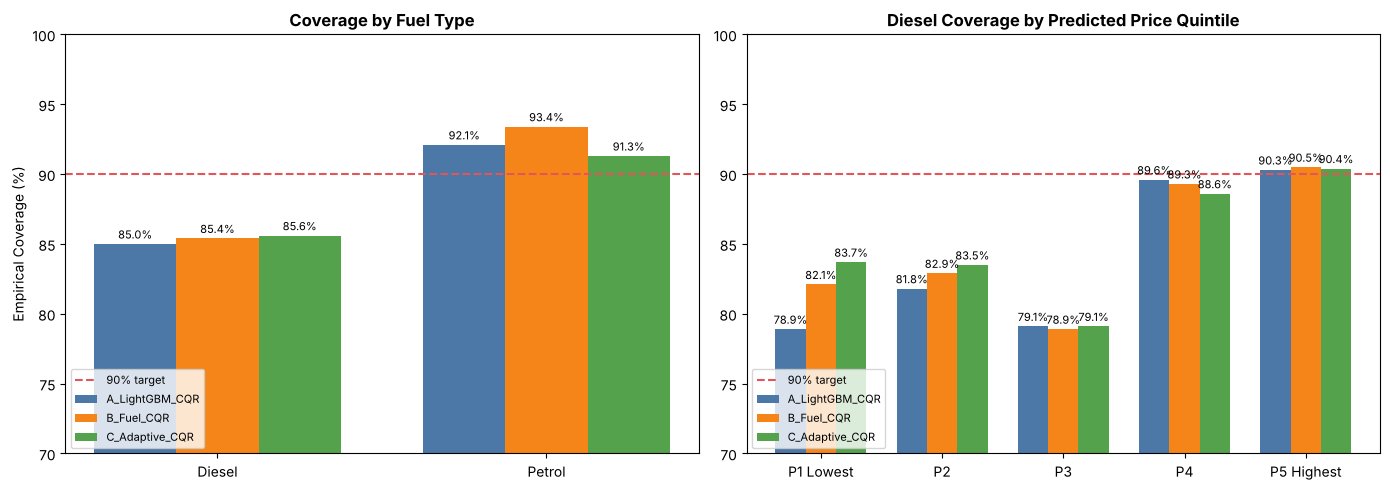

Updated: reports/figures/interval_conditional_coverage.png


In [34]:
# Cell 33: persist winning model artifact and updated diagnostic figure
# Fit winning candidate on full dev split using standard inner calibration split (seed=42)
inner_final = StratifiedGroupKFold(n_splits=4, shuffle=True, random_state=42)
strat_final = pd.qcut(dev.selling_price, 5, labels=False)
pi_f, ci_f = next(inner_final.split(dev[FEATS], strat_final, groups=dev.model_key))

Xp_full, yp_full = dev[FEATS].iloc[pi_f], dev.log_price.iloc[pi_f]
Xc_full, yc_full = dev[FEATS].iloc[ci_f], dev.log_price.iloc[ci_f]

if winner_name == "C_Adaptive_CQR":
    winner_model = LocallyAdaptiveCQR(lgb_lo, lgb_hi, alpha=0.10, diff_model=DIFF_MODEL)
    winner_model.fit(Xp_full, yp_full, Xc_full, yc_full)
    artifact_path = "../models/c_adaptive_cqr_model.joblib"
    artifact_payload = {
        "model_name": winner_name,
        "model": winner_model,
        "q_val": winner_model.q_val_,
        "alpha": 0.10,
        "features": FEATS
    }
elif winner_name == "B_Fuel_CQR":
    winner_model = FuelMondrianCQR(lgb_lo, lgb_hi, alpha=0.10)
    winner_model.fit(Xp_full, yp_full, Xc_full, yc_full)
    artifact_path = "../models/b_fuel_cqr_model.joblib"
    artifact_payload = {
        "model_name": winner_name,
        "model": winner_model,
        "q_adjs": winner_model.q_adjs_,
        "global_q": winner_model.global_q_,
        "alpha": 0.10,
        "features": FEATS
    }
else:
    clo_f = clone(lgb_lo).fit(Xp_full, yp_full)
    chi_f = clone(lgb_hi).fit(Xp_full, yp_full)
    q_f = compute_cqr_adjustment(yc_full.values, clo_f.predict(Xc_full), chi_f.predict(Xc_full))
    artifact_path = "../models/a_lightgbm_cqr_model.joblib"
    artifact_payload = {
        "model_name": winner_name,
        "m_lo": clo_f,
        "m_hi": chi_f,
        "adjustment": q_f,
        "alpha": 0.10,
        "features": FEATS
    }

joblib.dump(artifact_payload, artifact_path)
print(f"Saved artifact for winning candidate '{winner_name}' to {artifact_path}")

# Generate diagnostic figure comparing all candidates
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fuels = ["Diesel", "Petrol"]
x = np.arange(len(fuels))
w = 0.25

colors = {"A_LightGBM_CQR": "#4C78A8", "B_Fuel_CQR": "#F58518", "C_Adaptive_CQR": "#54A24B"}
for idx, (name, col) in enumerate(colors.items()):
    vals = [fuel_cov_df.loc[f, name] for f in fuels]
    bars = axes[0].bar(x + (idx - 1)*w, vals, w, label=name, color=col)
    for b in bars:
        h = b.get_height()
        axes[0].annotate(f"{h:.1f}%", xy=(b.get_x() + b.get_width()/2, h), xytext=(0, 2),
                         textcoords="offset points", ha="center", va="bottom", fontsize=8)
axes[0].axhline(90, color="#E15759", linestyle="--", linewidth=1.5, label="90% target")
axes[0].set_xticks(x)
axes[0].set_xticklabels(fuels)
axes[0].set_ylim(70, 100)
axes[0].set_title("Coverage by Fuel Type", fontweight="bold")
axes[0].set_ylabel("Empirical Coverage (%)")
axes[0].legend(fontsize=8, loc="lower left")

p_labels = ["P1 Lowest", "P2", "P3", "P4", "P5 Highest"]
xp = np.arange(len(p_labels))
for idx, (name, col) in enumerate(colors.items()):
    vals = [grid_dfs[name].loc["Diesel", p] for p in p_labels]
    bars = axes[1].bar(xp + (idx - 1)*w, vals, w, label=name, color=col)
    for b in bars:
        h = b.get_height()
        axes[1].annotate(f"{h:.1f}%", xy=(b.get_x() + b.get_width()/2, h), xytext=(0, 2),
                         textcoords="offset points", ha="center", va="bottom", fontsize=8)
axes[1].axhline(90, color="#E15759", linestyle="--", linewidth=1.5, label="90% target")
axes[1].set_xticks(xp)
axes[1].set_xticklabels(p_labels)
axes[1].set_ylim(70, 100)
axes[1].set_title("Diesel Coverage by Predicted Price Quintile", fontweight="bold")
axes[1].legend(fontsize=8, loc="lower left")

plt.tight_layout()
plt.savefig("../reports/figures/interval_conditional_coverage.png", dpi=120)
plt.show()
print("Updated: reports/figures/interval_conditional_coverage.png")


In [35]:
# Cell 34: Limitations of the prediction intervals (qualitative and programmatically formatted)
from IPython.display import Markdown, display

n_dev_models = dev.model_key.nunique()
g_cov_A_mean = fold_summary_df.loc["A_LightGBM_CQR", "cov_mean_%"]
g_cov_A_std = fold_summary_df.loc["A_LightGBM_CQR", "cov_std_%"]
min_A_fold = round(min([m["coverage_%"] for m in cand_g_pf["A_LightGBM_CQR"]]), 1)
max_A_fold = round(max([m["coverage_%"] for m in cand_g_pf["A_LightGBM_CQR"]]), 1)

# Fuel coverage values
diesel_cov_win = fuel_cov_df.loc["Diesel", winner_name]
petrol_cov_win = fuel_cov_df.loc["Petrol", winner_name]
d_A = fuel_cov_df.loc["Diesel", "A_LightGBM_CQR"]
d_B = fuel_cov_df.loc["Diesel", "B_Fuel_CQR"]
d_C = fuel_cov_df.loc["Diesel", "C_Adaptive_CQR"]
p_A = fuel_cov_df.loc["Petrol", "A_LightGBM_CQR"]
p_B = fuel_cov_df.loc["Petrol", "B_Fuel_CQR"]
p_C = fuel_cov_df.loc["Petrol", "C_Adaptive_CQR"]

# Selection margin numbers
worst_C = worst_df.loc["C_Adaptive_CQR", "Worst_Segment_cov_%"]
worst_A = worst_df.loc["A_LightGBM_CQR", "Worst_Segment_cov_%"]
diff_worst = round(worst_C - worst_A, 1)

min_grid_n = int(grid_n.loc[["Diesel", "Petrol"]].min().min())
max_grid_n = int(grid_n.loc[["Diesel", "Petrol"]].max().max())

std_C = fold_summary_df.loc["C_Adaptive_CQR", "cov_std_%"]
std_A = fold_summary_df.loc["A_LightGBM_CQR", "cov_std_%"]

wid_C = cand_summary_df.loc["C_Adaptive_CQR", "G_wid_%"]
wid_A = cand_summary_df.loc["A_LightGBM_CQR", "G_wid_%"]

score_C = cand_summary_df.loc["C_Adaptive_CQR", "G_score"]
score_A = cand_summary_df.loc["A_LightGBM_CQR", "G_score"]

limitations_md = f"""## 6.x Limitations of the intervals
While the conformalized prediction intervals provide finite-sample marginal coverage guarantees under exchangeability, operational deployment in used car pricing has key practical limitations:

1. **Unseen-model coverage varies by fold:** Outer 5-fold cross-validation on unseen car models shows that empirical coverage fluctuates across folds (for Candidate A: {min_A_fold}% to {max_A_fold}%, mean {g_cov_A_mean}% $\\pm$ {g_cov_A_std}%). When an entire car model family is held out, covariate shift between the training distribution and unseen chassis geometries is a possible reason for fold-to-fold variance (hypotheses, not tested).
2. **Calibration sample size constraints:** Inside each training fold, the nested grouped calibration partition reserves 25% of training models (~43 unique models out of {n_dev_models} dev models, ~1,390 rows). While sufficient for global conformity adjustment, sub-group conditioning on multiple features simultaneously is constrained by effective sample size in small strata.
3. **Diesel vs petrol coverage gap:** For selected candidate {winner_name}, measured coverage is {diesel_cov_win}% on diesel listings versus {petrol_cov_win}% on petrol listings. Across all tested variants, no candidate (A, B, or C) closed the diesel coverage gap (diesel {d_A:.1f}% / {d_B:.1f}% / {d_C:.1f}% vs petrol {p_A:.1f}% / {p_B:.1f}% / {p_C:.1f}%). Fleet usage, engine wear, and maintenance history are hypotheses, not tested, for the observed dispersion difference.
4. **Candidate selection margin:** The decision rule selected Candidate C by a worst-segment difference of {diff_worst} percentage points ({worst_C:.1f}% vs {worst_A:.1f}%), which is within sampling error for cells of n={min_grid_n}–{max_grid_n}, meaning the candidates are statistically indistinguishable on worst-segment coverage. Candidate C is retained by the pre-committed rule and because it exhibits lower fold-to-fold coverage variability (std {std_C:.1f} vs {std_A:.1f} points), a smaller median width ({wid_C:.1f}% vs {wid_A:.1f}%), and a better interval score ({score_C:.3f} vs {score_A:.3f}).
5. **Listing prices rather than transaction prices:** The target variable reflects seller asking prices on CarDekho, not final negotiated transaction prices. Asking prices incorporate dealer markup buffers, aspiration pricing, and arbitrary round-number anchoring that do not fully mirror actual settlement values.
"""

display(Markdown(limitations_md))


## 6.x Limitations of the intervals
While the conformalized prediction intervals provide finite-sample marginal coverage guarantees under exchangeability, operational deployment in used car pricing has key practical limitations:

1. **Unseen-model coverage varies by fold:** Outer 5-fold cross-validation on unseen car models shows that empirical coverage fluctuates across folds (for Candidate A: 81.5% to 94.0%, mean 88.266% $\pm$ 5.134%). When an entire car model family is held out, covariate shift between the training distribution and unseen chassis geometries is a possible reason for fold-to-fold variance (hypotheses, not tested).
2. **Calibration sample size constraints:** Inside each training fold, the nested grouped calibration partition reserves 25% of training models (~43 unique models out of 176 dev models, ~1,390 rows). While sufficient for global conformity adjustment, sub-group conditioning on multiple features simultaneously is constrained by effective sample size in small strata.
3. **Diesel vs petrol coverage gap:** For selected candidate C_Adaptive_CQR, measured coverage is 85.6% on diesel listings versus 91.3% on petrol listings. Across all tested variants, no candidate (A, B, or C) closed the diesel coverage gap (diesel 85.0% / 85.4% / 85.6% vs petrol 92.1% / 93.4% / 91.3%). Fleet usage, engine wear, and maintenance history are hypotheses, not tested, for the observed dispersion difference.
4. **Candidate selection margin:** The decision rule selected Candidate C by a worst-segment difference of 0.2 percentage points (79.1% vs 78.9%), which is within sampling error for cells of n=232–874, meaning the candidates are statistically indistinguishable on worst-segment coverage. Candidate C is retained by the pre-committed rule and because it exhibits lower fold-to-fold coverage variability (std 4.2 vs 5.1 points), a smaller median width (85.7% vs 86.9%), and a better interval score (1.312 vs 1.341).
5. **Listing prices rather than transaction prices:** The target variable reflects seller asking prices on CarDekho, not final negotiated transaction prices. Asking prices incorporate dealer markup buffers, aspiration pricing, and arbitrary round-number anchoring that do not fully mirror actual settlement values.


## 7. Saved artifacts
`src/deal_score.py` needs two saved objects: a point model (the fair price) and an interval model (the fair range). The interval model was saved in Section 6 (Cell 33). Here we fit the **final LightGBM point model on the whole development set** (the locked test set is not touched) and save it together with its feature list and the library versions, because pickled models only load reliably under compatible versions.

Two things to keep in mind. The interval models were fitted on 75% of the development models (the other 25% is the calibration set), while this point model uses every development row. And a refit on all available data would only be appropriate after the final test result has been recorded.

In [36]:
# Cell 35: fit and save the final point model, then prove the Deal Score chain loads from disk
import joblib, sklearn, lightgbm, importlib

point_model = clone(candidates["LightGBM"]).fit(dev[FEATS], dev.log_price)     # D22: LightGBM, 15 leaves, 500 trees, lr 0.03
joblib.dump({"model": point_model, "features": FEATS, "target": "log(selling_price)",
             "trained_on": f"development set, {len(dev)} rows",
             "versions": {"scikit-learn": sklearn.__version__, "lightgbm": lightgbm.__version__}},
            "../models/lightgbm_point_model.joblib")
print("Saved: models/lightgbm_point_model.joblib")

# Smoke test: load both artifacts through src/deal_score.py, exactly as the demo app will
import src.deal_score as ds
importlib.reload(ds); ds._point_artifact = ds._interval_artifact = None          # force a fresh load from disk
demo, rows = dev.sample(5, random_state=3), []
for _, r in demo.iterrows():
    out = ds.deal_score(r, r.selling_price)                                      # listed price = actual price
    assert abs(out["predicted_price"] - np.exp(point_model.predict(r.to_frame().T.infer_objects()[FEATS])[0])) < 0.01
    rows.append({"name": r["name"], "listed": int(r.selling_price), "predicted": int(out["predicted_price"]),
                 "lower": int(out["lower_bound"]), "upper": int(out["upper_bound"]),
                 "deal_score": out["deal_score"], "label": out["graded_label"]})
display(pd.DataFrame(rows))

Saved: models/lightgbm_point_model.joblib


,name,listed,predicted,lower,upper,deal_score,label
0,Hyundai i20 Petrol CVT Asta,750000,688164,540692,864537,40.8,Moderate Overpriced
1,Maruti Swift Dzire ZDI Plus,900000,669137,489586,772482,17.5,Deep Overpriced
2,Honda Civic ZX,2000000,2193257,715555,3098789,53.1,Fair Price
3,Hyundai Creta 1.4 CRDi S,1100000,807775,587617,1138088,26.6,Moderate Overpriced
4,Maruti Ertiga ZDI,600000,571631,362418,723845,46.5,Fair Price


**What this shows:** the module loads both models from disk and the point prediction matches the in-memory model (the assert). These five rows are development listings the point model was trained on, so the table is a **wiring check, not a performance claim**; performance is judged on the grouped CV (Section 5) and, once, on the locked test set.

## 8. Validation addendum: near-duplicate relistings
Section 1 removed exact duplicate rows. A second kind of repeat can survive: the **same car listed again at a different price**, meaning the same full name (which includes the variant), year, km, fuel, seller type, transmission and owner, but a different price. In a random split such twins can land on both sides and flatter the "typical repeat listing" scores.

This section counts them, reads what their price gap says about the noise in listing prices, and re-runs the random (seen) regime with every twin group kept in one fold. The grouped-by-model regime is unaffected by construction, because twins share a name and therefore a `model_key`; Cell 36 asserts it. Only development rows are analysed here; the test set is used only to assert that no twin group spans both sets.

In [37]:
# Cell 36: how many listings are the same car listed again at a different price?
TWIN_KEY = ["name", "year", "km_driven", "fuel", "seller_type", "transmission", "owner"]    # 'name' includes the variant

g = dev.groupby(TWIN_KEY).selling_price.agg(n="size", lo="min", hi="max")
twins = g[g.n > 1]
spread = (twins.hi / twins.lo - 1) * 100            # gap between the cheapest and the dearest listing of the same car
display(pd.Series({
    "development rows": len(dev),
    "twin groups (same car, more than one listing)": len(twins),
    "rows inside twin groups": int(twins.n.sum()),
    "share of development rows (%)": round(100 * twins.n.sum() / len(dev), 1),
    "price spread inside a group, median (%)": round(spread.median(), 1),
    "price spread inside a group, 75th percentile (%)": round(spread.quantile(.75), 1),
    "groups with identical prices": int((spread == 0).sum()),
}, name="twin listings"))

# Safety checks: a twin group never straddles two car models (so grouped CV is unaffected) or development/test
twin_id = dev.groupby(TWIN_KEY).ngroup()            # one id per distinct car; single listings get an id of their own
assert dev.groupby(twin_id).model_key.nunique().max() == 1, "a twin group spans two car models"
assert not (set(dev[TWIN_KEY].itertuples(index=False, name=None)) & set(test[TWIN_KEY].itertuples(index=False, name=None))), \
    "a twin group spans development and test"
print("Checks passed: every twin group sits inside one car model, and none spans development and test.")

development rows                                    5530.0
twin groups (same car, more than one listing)        169.0
rows inside twin groups                              351.0
share of development rows (%)                          6.3
price spread inside a group, median (%)               11.6
price spread inside a group, 75th percentile (%)      23.3
groups with identical prices                           1.0
Name: twin listings, dtype: float64

Checks passed: every twin group sits inside one car model, and none spans development and test.


In [38]:
# Cell 37: the random ("seen") regime again, with every twin group kept in one fold
from sklearn.model_selection import GroupKFold
twin_cv = GroupKFold(n_splits=5, shuffle=True, random_state=1)     # same fold count and seed as seen_cv, but twins stay together

def seen_scores(model, splits):
    rows = []
    for tr, va in splits:
        m = clone(model).fit(dev[FEATS].iloc[tr], dev.log_price.iloc[tr])
        rows.append(score(dev.log_price.iloc[va].values, m.predict(dev[FEATS].iloc[va])))
    return pd.DataFrame(rows).mean()

twin_scores = pd.DataFrame({name: seen_scores(m, twin_cv.split(dev[FEATS], groups=twin_id))
                            for name, m in candidates.items()}).T
compare = pd.DataFrame({"MedAPE_% old": results["seen_MedAPE_%"], "MedAPE_% twins together": twin_scores["MedAPE_%"],
                        "R2 old": results["seen_R2"], "R2 twins together": twin_scores["R2_log"]})
compare["MedAPE change (pts)"] = compare["MedAPE_% twins together"] - compare["MedAPE_% old"]
display(compare.round(3))

# Does the Section 5 selection rule (Cell 19) still pick the same model on the honest repeat-listing error?
new_pick = twin_scores.loc[shortlist.index, "MedAPE_%"].idxmin()
print(f"Selection rule with the old seen MedAPE: {chosen} | with twins kept together: {new_pick}")
print("Shortlist ranked by twins-together MedAPE:", [(k, round(v, 2)) for k, v in twin_scores.loc[shortlist.index, "MedAPE_%"].sort_values().items()])

,MedAPE_% old,MedAPE_% twins together,R2 old,R2 twins together,MedAPE change (pts)
Ridge,15.141,15.025,0.888,0.887,-0.116
ElasticNet,15.135,15.047,0.888,0.887,-0.088
RandomForest,12.070,12.067,0.913,0.913,-0.003
HistGradientBoosting,11.971,11.847,0.915,0.915,-0.125
XGBoost,12.270,12.050,0.916,0.916,-0.220
LightGBM,11.866,11.901,0.916,0.917,0.036


Selection rule with the old seen MedAPE: LightGBM | with twins kept together: HistGradientBoosting
Shortlist ranked by twins-together MedAPE: [('HistGradientBoosting', 11.85), ('LightGBM', 11.9), ('XGBoost', 12.05), ('Ridge', 15.03), ('ElasticNet', 15.05)]


In [39]:
# Cell 38: the interval check in the random regime with twins kept together (A = standard CQR, C = the selected adaptive CQR)
def seen_interval_oof(outer_splits, inner_seed=42):
    n, X, y = len(dev), dev[FEATS], dev.log_price
    out = {k: (np.zeros(n), np.zeros(n)) for k in ["A_LightGBM_CQR", "C_Adaptive_CQR"]}
    for tr, va in outer_splits:
        Xtr, ytr = X.iloc[tr], y.iloc[tr]
        inner = GroupKFold(n_splits=4, shuffle=True, random_state=inner_seed)          # calibration rows keep twins together too
        pi, ci = next(inner.split(Xtr, groups=twin_id.iloc[tr]))
        Xp, yp, Xc, yc = Xtr.iloc[pi], ytr.iloc[pi], Xtr.iloc[ci], ytr.iloc[ci]
        clo, chi = clone(lgb_lo).fit(Xp, yp), clone(lgb_hi).fit(Xp, yp)                 # A: standard CQR
        q = compute_cqr_adjustment(yc.values, clo.predict(Xc), chi.predict(Xc))
        out["A_LightGBM_CQR"][0][va] = clo.predict(X.iloc[va]) - q
        out["A_LightGBM_CQR"][1][va] = chi.predict(X.iloc[va]) + q
        fc = LocallyAdaptiveCQR(lgb_lo, lgb_hi, diff_model=DIFF_MODEL).fit(Xp, yp, Xc, yc)   # C: locally adaptive CQR
        out["C_Adaptive_CQR"][0][va], out["C_Adaptive_CQR"][1][va] = fc.predict(X.iloc[va])
    return out

twin_oof = seen_interval_oof(twin_cv.split(dev[FEATS], groups=twin_id))
rows = []
for name in ["A_LightGBM_CQR", "C_Adaptive_CQR"]:
    m_new = interval_metrics(dev.log_price, *twin_oof[name])
    rows.append({"Candidate": name,
                 "cov_% old": cand_summary_df.loc[name, "S_cov_%"], "cov_% twins together": m_new["coverage_%"],
                 "width_% old": cand_summary_df.loc[name, "S_wid_%"], "width_% twins together": m_new["med_width_%"],
                 "score old": cand_summary_df.loc[name, "S_score"], "score twins together": m_new["interval_score"]})
display(pd.DataFrame(rows).set_index("Candidate"))

,cov_% old,cov_% twins together,width_% old,width_% twins together,score old,score twins together
Candidate,,,,,,
A_LightGBM_CQR,89.53,90.18,64.3,65.2,0.980,0.983
C_Adaptive_CQR,89.71,90.45,64.8,65.2,0.977,0.981


**Findings**
- **Twins exist, but there are few.** 169 groups (351 rows, 6.3% of the development rows) are the same car, including the variant, listed more than once. All but one group differ in price.
- **They do not flatter the repeat-listing scores.** With twin groups kept in one fold, the typical-listing median error moves by between -0.22 and +0.04 percentage points across the six models (LightGBM 11.87% to 11.90%), and R² by 0.001 or less. Interval coverage in the same regime does not fall either: standard CQR 89.5% to 90.2%, adaptive CQR 89.7% to 90.5%, with median widths of about 65% in both versions. The coverage shifts are inside the fold-to-fold standard deviation of 1.4 points reported in Section 6. The concern that twins inflate the numbers is not supported, so the earlier results stand.
- **A rough read on listing noise.** Two listings of the same car differ by a median of 11.6% (75th percentile 23.3%). If those gaps were independent noise around a fair price, even a perfect fair-price model would show a median error of roughly 0.7 x 11.6%, about 8%. Our 11.9% on repeat listings therefore leaves some headroom, but not a lot. The assumption is rough, because twins also differ in condition, negotiation and listing date, none of which the data records. For the Deal Score it suggests that a "fair" band much narrower than about 10% would mostly flag ordinary noise.
- **The Section 5 selection rule flips on a 0.05-point gap.** On the twins-together repeat-listing error HistGradientBoosting (11.85%) edges LightGBM (11.90%), so the rule as written would now pick HistGradientBoosting. That gap is smaller than the 0.1-point gap Section 5 already called not meaningful, and the two models are indistinguishable on the stress test. We keep LightGBM for the reason recorded there: native quantile regression, which the Section 6 intervals are built on, and SHAP support. It is the same lesson as D32: a selection rule without a minimum-improvement margin decides on noise.

## 9. Error analysis: where is the point model wrong?
Before building the Deal Score on top of the price model, we ask where that model is wrong and whether the errors are random or have a pattern. Everything here uses **development data only** (out-of-fold predictions of the selected LightGBM); the locked test set is not touched.

Two regimes again: **unseen car models** (grouped CV, the stress test) and **repeat listings** (random CV with twin listings kept together, Section 8). The signed error is `(predicted - listed) / listed`, so a **negative** value means the model under-predicted. MedAPE here is pooled over all out-of-fold rows (17.6%), which differs slightly from the fold-averaged 17.65% in Section 5.

In [40]:
# Cell 39: out-of-fold predictions of the selected LightGBM, in both regimes
lgb_point = candidates["LightGBM"]
_, _, oof_g = cv_eval(lgb_point, dev, FEATS, cv_group)                       # unseen car models (stress test)
oof_s = np.zeros(len(dev))                                                    # repeat listings, twins kept together (Section 8)
for tr, va in twin_cv.split(dev[FEATS], groups=twin_id):
    oof_s[va] = clone(lgb_point).fit(dev[FEATS].iloc[tr], dev.log_price.iloc[tr]).predict(dev[FEATS].iloc[va])

err = dev[["name", "brand", "model_key", "year", "age", "km_driven", "km_per_year", "fuel", "seller_type",
           "transmission", "owner", "selling_price", "specs_missing"]].copy()
for r, oof in (("g", oof_g), ("s", oof_s)):
    err[f"pred_{r}"] = np.exp(oof)
    err[f"pe_{r}"] = (err[f"pred_{r}"] - err.selling_price) / err.selling_price * 100     # signed % error, negative = under-predicted
    err[f"ape_{r}"] = err[f"pe_{r}"].abs()

# slice labels
err["age_bucket"] = pd.cut(err.age, [-1, 3, 7, 12, 40], labels=["0-3 yrs", "4-7 yrs", "8-12 yrs", "13+ yrs"])
err["pred_q"] = pd.qcut(err.pred_g, 5, labels=["P1 lowest", "P2", "P3", "P4", "P5 highest"])      # what a buyer sees: the predicted price
err["true_q"] = pd.qcut(err.selling_price, 5, labels=["Q1 lowest", "Q2", "Q3", "Q4", "Q5 highest"])  # conditions on the outcome (biased slice)
err["model_size"] = pd.cut(dev.model_key.map(dev.model_key.value_counts()), [0, 4, 19, 99, 10000],
                           labels=["<5 listings", "5-19", "20-99", "100+"])

overall = pd.DataFrame({
    "median error (MedAPE %)": [err.ape_g.median(), err.ape_s.median()],
    "median signed error %": [err.pe_g.median(), err.pe_s.median()],
    "listings off by >30%": [100 * (err.ape_g > 30).mean(), 100 * (err.ape_s > 30).mean()],
    "listings off by >50%": [100 * (err.ape_g > 50).mean(), 100 * (err.ape_s > 50).mean()],
    "fair price >=30% ABOVE listing (false bargain)": [100 * (err.pe_g >= 30).mean(), 100 * (err.pe_s >= 30).mean()],
    "fair price >=30% BELOW listing (false overpriced)": [100 * (err.pe_g <= -30).mean(), 100 * (err.pe_s <= -30).mean()],
}, index=["unseen car models", "repeat listings"]).T
display(overall.round(1))
ae = (np.log(err.pred_g) - np.log(err.selling_price)).abs()
print(f"Share of the total absolute log error that comes from the worst 10% of rows (unseen models): "
      f"{100 * ae.sort_values(ascending=False).head(len(ae) // 10).sum() / ae.sum():.1f}%")

,unseen car models,repeat listings
median error (MedAPE %),17.6,11.9
median signed error %,-3.5,-0.5
listings off by >30%,25.5,13.8
listings off by >50%,8.2,3.9
fair price >=30% ABOVE listing (false bargain),14.3,9.2
fair price >=30% BELOW listing (false overpriced),11.2,4.6


Share of the total absolute log error that comes from the worst 10% of rows (unseen models): 29.0%


In [41]:
# Cell 40: error by slice (MedAPE, median signed error = bias, share of listings off by >30%)
def slice_table(col, regime, min_n=40):
    grp = err.groupby(col, observed=True)
    t = pd.DataFrame({"n": grp.size(), "MedAPE_%": grp[f"ape_{regime}"].median(), "bias_%": grp[f"pe_{regime}"].median(),
                      "off>30%": grp[f"ape_{regime}"].apply(lambda s: 100 * (s > 30).mean())})
    return t[t.n >= min_n].round(1)

for col in ["age_bucket", "pred_q", "true_q", "seller_type", "owner", "specs_missing", "model_size", "fuel", "transmission"]:
    print(f"\n=== by {col}" + ("   (conditions on the outcome: biased slice, see Section 6)" if col == "true_q" else ""))
    display(pd.concat({"unseen models": slice_table(col, "g"), "repeat listings": slice_table(col, "s")}, axis=1))

print("\n=== by brand (brands with >=100 listings), sorted by unseen-model error")
display(pd.concat({"unseen models": slice_table("brand", "g", 100), "repeat listings": slice_table("brand", "s", 100)},
                  axis=1).sort_values(("unseen models", "MedAPE_%")))


=== by age_bucket


unseen models                         repeat listings           \
                       n MedAPE_% bias_% off>30%               n MedAPE_%   
age_bucket                                                                  
0-3 yrs             1420     12.5   -2.7    13.2            1420      9.0   
4-7 yrs             1949     17.5   -5.5    24.0            1949     10.8   
8-12 yrs            1668     20.1   -2.8    30.4            1668     15.2   
13+ yrs              493     29.9    4.1    49.9             493     24.2   

                           
           bias_% off>30%  
age_bucket                 
0-3 yrs      -0.8     5.6  
4-7 yrs      -0.4     9.5  
8-12 yrs     -0.6    18.3  
13+ yrs       0.8    39.4


=== by pred_q


unseen models                         repeat listings           \
                       n MedAPE_% bias_% off>30%               n MedAPE_%   
pred_q                                                                      
P1 lowest           1106     25.2   -3.5    40.4            1106     17.3   
P2                  1106     19.4   -6.0    24.5            1106     12.9   
P3                  1106     17.1   -5.9    24.4            1106     10.9   
P4                  1106     13.8   -1.7    19.2            1106      9.8   
P5 highest          1106     13.9   -1.1    18.9            1106     10.2   

                           
           bias_% off>30%  
pred_q                     
P1 lowest    -0.5    26.5  
P2           -0.9    14.5  
P3           -1.1    11.5  
P4           -0.1     7.2  
P5 highest   -0.1     9.5


=== by true_q   (conditions on the outcome: biased slice, see Section 6)


...

unseen models                         repeat listings                  \
                   n MedAPE_% bias_% off>30%               n MedAPE_% bias_%   
fuel                                                                           
CNG               48     12.5    1.2    14.6              48      9.1    3.8   
Diesel          3023     17.7   -3.9    26.2            3023     12.2   -0.8   
Petrol          2426     17.5   -3.0    24.8            2426     11.4   -0.3   

                
       off>30%  
fuel            
CNG        6.2  
Diesel    13.2  
Petrol    14.6


=== by transmission


unseen models                         repeat listings           \
                         n MedAPE_% bias_% off>30%               n MedAPE_%   
transmission                                                                  
Automatic              474     17.5   -0.4    23.8             474     13.4   
Manual                5056     17.6   -3.7    25.6            5056     11.8   

                             
             bias_% off>30%  
transmission                 
Automatic      -0.5    18.6  
Manual         -0.5    13.4


=== by brand (brands with >=100 listings), sorted by unseen-model error


unseen models                         repeat listings           \
                       n MedAPE_% bias_% off>30%               n MedAPE_%   
brand                                                                       
Volkswagen           148     12.7   -0.5    15.5             148     10.6   
Maruti              1764     12.8   -2.2    16.4            1764     10.3   
Hyundai             1113     15.8   -5.0    18.1            1113     10.7   
Honda                279     19.7  -11.1    24.7             279     12.6   
Renault              206     20.2   -8.4    28.6             206     10.9   
Tata                 549     20.7    3.8    34.4             549     14.8   
Ford                 324     21.1   -2.2    30.9             324     11.7   
Mahindra             320     24.9   -2.4    41.9             320     15.1   
Chevrolet            192     26.4   16.3    42.7             192     16.8   
Toyota               283     32.0  -28.1    55.5             283     13.5   

                           
           bias_% off>30%  
brand                      
Volkswagen    0.9     9.5  
Maruti       -0.1    11.7  
Hyundai      -0.0    10.2  
Honda        -3.7    15.1  
Renault      -1.6     7.8  
Tata         -0.4    20.0  
Ford         -0.4    14.2  
Mahindra     -0.1    15.3  
Chevrolet    -0.8    21.4  
Toyota       -3.4    14.1

In [42]:
# Cell 41: the worst listings, the worst car models, and a test of the diesel hint from Section 6
worst = err.sort_values("ape_g", ascending=False).head(20)
print("=== 20 worst listings (unseen-model regime)")
display(worst[["name", "year", "km_driven", "fuel", "selling_price", "pred_g", "pe_g"]].round(0).astype({"selling_price": int, "pred_g": int}))
print("Over-predictions among them:", int((worst.pe_g > 0).sum()), "of 20")

by_model = err.groupby("model_key").agg(n=("ape_g", "size"), MedAPE=("ape_g", "median"), bias=("pe_g", "median")).round(1)
print("\n=== car models (>=15 listings) with the largest typical error, unseen-model regime")
display(by_model[by_model.n >= 15].sort_values("MedAPE", ascending=False).head(10))

# 'problem models': at least 15 listings and a median signed error beyond +-30% (threshold chosen after looking, so exploratory)
problem = by_model[(by_model.n >= 15) & (by_model.bias.abs() > 30)].index
err["in_problem_model"] = err.model_key.isin(problem)
print("\nProblem models:", sorted(problem), "| rows:", int(err.in_problem_model.sum()),
      f"({100 * err.in_problem_model.mean():.1f}% of development)")
rows = []
for f in ["Diesel", "Petrol"]:
    s = err[err.fuel == f]
    rows.append({"fuel": f, "share of rows in problem models %": 100 * s.in_problem_model.mean(),
                 "MedAPE all %": s.ape_g.median(), "MedAPE without them %": s[~s.in_problem_model].ape_g.median(),
                 "off>30% all %": 100 * (s.ape_g > 30).mean(), "off>30% without them %": 100 * (s[~s.in_problem_model].ape_g > 30).mean()})
display(pd.DataFrame(rows).set_index("fuel").round(1))

rupee = (err.ape_g / 100 * err.selling_price)
cheap = err.selling_price < 200_000
print(f"\nMedian absolute error in rupees: all listings {rupee.median():,.0f} | listings under Rs 2 lakh {rupee[cheap].median():,.0f} "
      f"(n={cheap.sum()}, MedAPE {err.ape_g[cheap].median():.1f}%)")

=== 20 worst listings (unseen-model regime)


,name,year,km_driven,fuel,selling_price,pred_g,pe_g
2616,Tata Nano XE,2017,70000,Petrol,66000,238317,261.0
4580,Volkswagen Polo 1.5 TDI Comfortline,2020,50000,Diesel,260000,902854,247.0
5335,Tata Nano LX SE,2012,28000,Petrol,45000,153042,240.0
5211,Mahindra Xylo E4,2011,130000,Diesel,150000,496908,231.0
3306,Hyundai Sonata 2.4L AT,2008,50000,Petrol,168000,542847,223.0
871,Mahindra Xylo D4 BSIII,2013,300000,Diesel,200000,642298,221.0
5283,Tata Safari DICOR 2.2 LX 4x2,2012,82507,Diesel,132000,423825,221.0
4353,Mahindra Xylo D2,2009,100000,Diesel,121000,379880,214.0
5499,Tata Nano Cx,2011,25000,Petrol,46000,144205,213.0
295,Volkswagen GTI 1.8 TSI,2016,70000,Petrol,800000,2488634,211.0


Over-predictions among them: 20 of 20

=== car models (>=15 listings) with the largest typical error, unseen-model regime


,n,MedAPE,bias
model_key,,,
Tata Nano,25,130.4,130.4
Mahindra Xylo,50,77.8,77.8
Tata Indica,69,41.6,41.5
Toyota Innova,147,40.6,-40.2
Maruti 800,89,39.9,38.6
Mahindra KUV,44,36.6,36.6
Chevrolet Beat,61,33.1,33.1
Hyundai Accent,32,32.0,18.1
Toyota Innova Crysta,41,31.2,-16.1



Problem models: ['Chevrolet Beat', 'Mahindra KUV', 'Mahindra Xylo', 'Maruti 800', 'Tata Indica', 'Tata Nano', 'Toyota Innova'] | rows: 485 (8.8% of development)


,share of rows in problem models %,MedAPE all %,MedAPE without them %,off>30% all %,off>30% without them %
fuel,,,,,
Diesel,10.3,17.7,15.9,26.2,21.2
Petrol,7.1,17.5,16.7,24.8,21.7



Median absolute error in rupees: all listings 61,525 | listings under Rs 2 lakh 31,624 (n=935, MedAPE 26.8%)


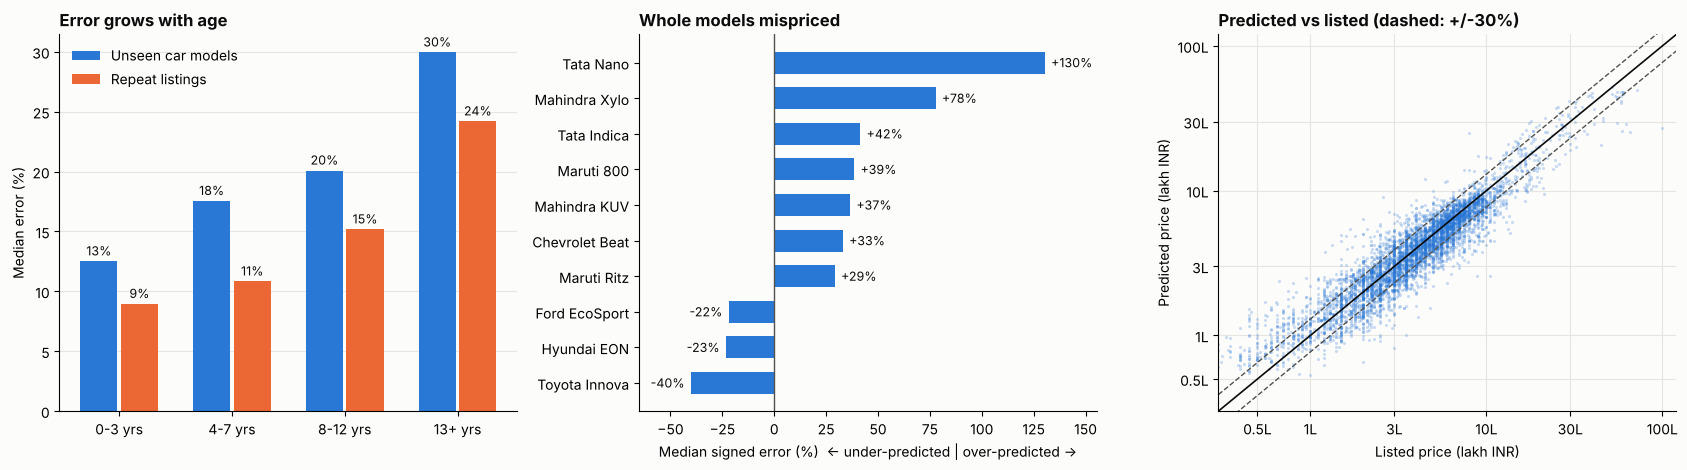

Saved: reports/figures/error_analysis.png


In [43]:
# Cell 42: figure (blue = unseen car models, orange = repeat listings; same colours as the tables above)
BLUE, ORANGE, INK, MUTED, SURFACE = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e", "#fcfcfb"
fig, ax = plt.subplots(1, 3, figsize=(17, 4.8), facecolor=SURFACE)
for a in ax:
    a.set_facecolor(SURFACE)
    for side in ("top", "right"): a.spines[side].set_visible(False)
    a.grid(axis="y", color="#e6e5e1", linewidth=0.8); a.set_axisbelow(True)

# (a) typical error by age
ages = ["0-3 yrs", "4-7 yrs", "8-12 yrs", "13+ yrs"]; x = np.arange(len(ages)); w = 0.36
ga, sa = [err[err.age_bucket == k].ape_g.median() for k in ages], [err[err.age_bucket == k].ape_s.median() for k in ages]
for xs, vals, col, lab in ((x - w / 2, ga, BLUE, "Unseen car models"), (x + w / 2, sa, ORANGE, "Repeat listings")):
    bars = ax[0].bar(xs, vals, w - 0.03, color=col, label=lab)
    for b_, v in zip(bars, vals): ax[0].text(b_.get_x() + b_.get_width() / 2, v + 0.5, f"{v:.0f}%", ha="center", fontsize=9, color=INK)
ax[0].set_xticks(x); ax[0].set_xticklabels(ages); ax[0].set_ylabel("Median error (%)")
ax[0].set_title("Error grows with age", loc="left", fontweight="bold", color=INK); ax[0].legend(frameon=False, loc="upper left")

# (b) the car models the price model gets wrong as a whole (unseen-model regime)
top = by_model[by_model.n >= 25].assign(a=lambda d: d.bias.abs()).sort_values("a", ascending=False).head(10).sort_values("bias")
ax[1].barh(top.index, top.bias, color=BLUE, height=0.62)
ax[1].axvline(0, color=MUTED, linewidth=1)
for yy, v in enumerate(top.bias): ax[1].text(v + (3 if v >= 0 else -3), yy, f"{v:+.0f}%", va="center", ha="left" if v >= 0 else "right", fontsize=9, color=INK)
ax[1].set_xlim(top.bias.min() - 25, top.bias.max() + 25); ax[1].grid(axis="y", visible=False)
ax[1].set_xlabel("Median signed error (%)  <- under-predicted | over-predicted ->")
ax[1].set_title("Whole models mispriced", loc="left", fontweight="bold", color=INK)

# (c) predicted vs listed price, unseen-model regime
lo_, hi_ = 3e4, 1.2e7
ax[2].scatter(err.selling_price, err.pred_g, s=5, alpha=0.25, color=BLUE, linewidths=0)
xx = np.array([lo_, hi_]); ax[2].plot(xx, xx, color=INK, linewidth=1.2)
ax[2].plot(xx, xx * 1.3, color=MUTED, linewidth=1, linestyle="--"); ax[2].plot(xx, xx / 1.3, color=MUTED, linewidth=1, linestyle="--")
ax[2].set_xscale("log"); ax[2].set_yscale("log"); ax[2].set_xlim(lo_, hi_); ax[2].set_ylim(lo_, hi_)
ticks = [5e4, 1e5, 3e5, 1e6, 3e6, 1e7]; labs = ["0.5L", "1L", "3L", "10L", "30L", "100L"]
ax[2].set_xticks(ticks); ax[2].set_xticklabels(labs); ax[2].set_yticks(ticks); ax[2].set_yticklabels(labs)
ax[2].minorticks_off(); ax[2].grid(axis="x", color="#e6e5e1", linewidth=0.8)
ax[2].set_xlabel("Listed price (lakh INR)"); ax[2].set_ylabel("Predicted price (lakh INR)")
ax[2].set_title("Predicted vs listed (dashed: +/-30%)", loc="left", fontweight="bold", color=INK)
plt.tight_layout(); plt.savefig("../reports/figures/error_analysis.png", dpi=120, facecolor=SURFACE); plt.show()
print("Saved: reports/figures/error_analysis.png")

**Findings**
- **The biggest misses are whole car models, not random listings.** Seven models with at least 15 listings are mispriced in the same direction almost every time when they are held out: Tata Nano (median +130%), Mahindra Xylo (+78%), Tata Indica (+42%), Maruti 800 (+39%), Mahindra KUV (+37%), Chevrolet Beat (+33%) and Toyota Innova (-40%). All 20 worst listings are over-predictions, mostly Nano, Xylo and Indica: budget models whose specs look like a pricier car's. The reverse happens to models with strong resale reputation (Toyota Innova, Toyota as a brand -28%). The features describe the car but not how the market regards the model. These seven models are 8.8% of the development rows, yet the worst 10% of rows produce 29% of the total log error, so they inflate the tail more than the median (unseen-model MedAPE 17.6% falls only to 16.3% without them).
- **Age is the main driver of error.** The typical error climbs from 12.5% for cars up to 3 years old to 29.9% for cars over 12 years, and about half the oldest cars are off by more than 30% on unseen models (39% on repeat listings). Prices of old cars depend on condition, which the data does not record.
- **The cheap end is hardest in percent and mild in rupees.** The lowest predicted-price quintile has a 25.2% typical error, and 40% of its listings are off by more than 30%. Yet the median error on listings under Rs 2 lakh is about Rs 32,000, against Rs 61,500 across all listings. The Deal Score works in percentages, so cheap cars will be its noisiest.
- **There is no systematic bias a buyer would feel.** The median signed error is -3.5% on unseen models and -0.5% on repeat listings, and by predicted-price quintile it stays between -6% and -1%. The large bias at the extremes of the *listed* price (+16.9% in the cheapest quintile, -11.4% in the dearest) comes from slicing on the outcome, as explained in Section 6.
- **Other slices.** Dealer listings are priced better than individual ones (13.7% vs 18.1% on unseen models), first-owner cars better than later owners (15.6% vs 20-25%), and listings with missing specs are much worse (25.5% vs 17.3% on unseen models; 21.6% vs 11.6% on repeat listings, 188 rows). Models with fewer than 5 listings are worse than average (22.7%). Fuel, transmission and yearly usage make no meaningful difference.
- **A lead on the diesel gap from Section 6, to be tested rather than believed.** Diesel and petrol have the same typical point error (17.7% vs 17.5%), so the interval under-coverage is about spread, not about the centre. Diesel rows sit more often inside the seven problem models (10.3% vs 7.1%). Without them the share of listings off by more than 30% is 21.2% for diesel and 21.7% for petrol: the gap disappears. That is consistent with a few diesel models being mispriced as a whole, but the problem-model list was chosen after looking at these errors, so it is a hypothesis.
- **Consequence for the Deal Score: the costly failure is a false bargain.** On unseen models the fair price is at least 30% above the listing for 14.3% of listings (9.2% on repeat listings), against 11.2% (4.6%) in the other direction. The worst case is a budget car from a model the system has not learned, such as a Tata Nano listed at Rs 66,000 with a predicted price of Rs 238,000. The score should therefore carry a confidence signal for models with few listings, for old cars and for rows with missing specs.
- **Two of the 20 worst look like possible data errors,** worth a manual check but not removed: a 2020 VW Polo 1.5 TDI listed at Rs 2.6 lakh (predicted Rs 9.0 lakh) and a 2016 VW GTI at Rs 8 lakh (predicted Rs 24.9 lakh).

**Not yet tested:** the model never sees the car model's identity (D18), which keeps the validation honest. In the shipped app a user picks a known model, so identity may reduce the repeat-listing error. That is an experiment for a later step, to be judged on repeat listings only.

## 10. Experiment: does the car model's identity help?
Section 9 showed that the largest errors come from whole car models the price model has not learned. The model never sees a car model's identity (D18), which keeps the unseen-model validation honest. In the shipped app a user picks a *known* model, so identity might help there. This section tests that, and only that.

**Design, fixed before looking at any result**
- Variants: the selected LightGBM unchanged (baseline), plus the car model's identity as one-hot columns, or target-encoded (cross-fitted inside each training fold). Same hyper-parameters, no re-tuning.
- **Familiarity routing:** the identity model is used only for car models with at least `K_ROUTE = 10` listings in the training fold; every other row gets the baseline prediction. On unseen models this makes the routed predictions identical to the baseline by construction.
- Judged on **repeat listings** with twins kept together (Section 8 folds), on the same folds for every variant (paired). Unseen models are a guardrail only.
- **Adoption rule:** a routed variant is adopted only if it lowers the median error by at least 0.5 points, lowers RMSE_log, and beats the baseline in at least 4 of the 5 paired folds. Both thresholds are set in advance because the Section 5 selection rule had no margin (D32).
- The locked test set is not touched, and no saved artifact changes in this section.

In [44]:
# Cell 43: variants of the point model, scored on identical folds (paired comparison)
from sklearn.preprocessing import TargetEncoder
from sklearn.model_selection import KFold
K_ROUTE = 10                       # pre-committed: use the identity model only for car models with >= 10 listings in the training fold
base_lgbm = candidates["LightGBM"].named_steps["model"]                       # same hyper-parameters as the selected model; no re-tuning

def make_pipe_id(mode):
    """make_pipe plus the car model's identity: one-hot, or target-encoded (cross-fitted inside fit, so it cannot leak)."""
    num = Pipeline([("impute", SimpleImputer(strategy="median", add_indicator=True)), ("scale", "passthrough")])
    parts = [("num", num, NUM_M),
             ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT_M + (["model_key"] if mode == "onehot" else []))]
    if mode == "target":
        parts.append(("te", TargetEncoder(target_type="continuous", smooth="auto", cv=KFold(5, shuffle=True, random_state=0)), ["model_key"]))
    return Pipeline([("cols", ColumnTransformer(parts)), ("model", clone(base_lgbm))])

FEATS_ID = FEATS + ["model_key"]
BASE = "baseline (no identity)"
variants = {BASE: (candidates["LightGBM"], FEATS),
            "identity one-hot": (make_pipe_id("onehot"), FEATS_ID),
            "identity target-encoded": (make_pipe_id("target"), FEATS_ID)}
bands = pd.qcut(dev.selling_price, 5, labels=False)
splits = {"repeat listings": list(twin_cv.split(dev[FEATS], groups=twin_id)),                    # Section 8 folds: twins together
          "unseen car models": list(cv_group.split(dev, bands, groups=dev.model_key))}          # Section 5 folds

oof, train_n = {}, {}           # out-of-fold log predictions per variant; listings of the row's car model inside its training fold
for regime, sp in splits.items():
    oof[regime] = {v: np.zeros(len(dev)) for v in variants}
    train_n[regime] = np.zeros(len(dev), dtype=int)
    for tr, va in sp:
        train_n[regime][va] = dev.model_key.iloc[va].map(dev.model_key.iloc[tr].value_counts()).fillna(0).astype(int).values
        for v, (pipe, feats) in variants.items():
            oof[regime][v][va] = clone(pipe).fit(dev[feats].iloc[tr], dev.log_price.iloc[tr]).predict(dev[feats].iloc[va])

def routed(regime, enc, k=K_ROUTE):
    """Familiarity routing: identity model when the car model has >= k training listings, otherwise the baseline."""
    return np.where(train_n[regime] >= k, oof[regime][enc], oof[regime][BASE])

print("Fitted", len(variants), "variants x", sum(len(s) for s in splits.values()), "folds.")
for regime in splits:
    print(f"{regime}: share of rows whose car model has >= {K_ROUTE} training listings: {100 * (train_n[regime] >= K_ROUTE).mean():.1f}%")

Fitted 3 variants x 10 folds.
repeat listings: share of rows whose car model has >= 10 training listings: 92.5%
unseen car models: share of rows whose car model has >= 10 training listings: 0.0%


In [45]:
# Cell 44: results table, per regime (pooled out-of-fold; folds-improved counts the 5 paired folds where MedAPE beat the baseline)
def ape_of(pred_log): return np.abs(np.exp(pred_log) - dev.selling_price.values) / dev.selling_price.values * 100

def summarise(regime, label, pred_log):
    s = score(dev.log_price.values, pred_log); ape = ape_of(pred_log)
    base_ape = ape_of(oof[regime][BASE])
    folds = sum(np.median(ape[va]) < np.median(base_ape[va]) for _, va in splits[regime])
    return {"model": label, "RMSE_log": s["RMSE_log"], "R2": s["R2_log"], "MedAPE_%": s["MedAPE_%"],
            "off>30%": 100 * (ape > 30).mean(), "folds better than baseline": f"{folds}/5"}

tables = {}
for regime in splits:
    rows = [summarise(regime, BASE, oof[regime][BASE])]
    rows += [summarise(regime, f"{enc} (all rows)", oof[regime][enc]) for enc in list(variants)[1:]]
    rows += [summarise(regime, f"{enc}, routed (k={K_ROUTE})", routed(regime, enc)) for enc in list(variants)[1:]]
    tables[regime] = pd.DataFrame(rows).set_index("model")
    print(f"\n=== {regime}"); display(tables[regime].round(3))


=== repeat listings


,RMSE_log,R2,MedAPE_%,off>30%,folds better than baseline
model,,,,,
baseline (no identity),0.222,0.917,11.901,13.834,0/5
identity one-hot (all rows),0.219,0.919,11.389,13.526,5/5
identity target-encoded (all rows),0.215,0.922,11.529,12.821,4/5
"identity one-hot, routed (k=10)",0.218,0.919,11.354,13.327,5/5
"identity target-encoded, routed (k=10)",0.217,0.921,11.520,12.911,4/5



=== unseen car models


,RMSE_log,R2,MedAPE_%,off>30%,folds better than baseline
model,,,,,
baseline (no identity),0.296,0.852,17.570,25.479,0/5
identity one-hot (all rows),0.290,0.859,16.948,24.485,4/5
identity target-encoded (all rows),0.352,0.791,20.097,33.273,0/5
"identity one-hot, routed (k=10)",0.296,0.852,17.570,25.479,0/5
"identity target-encoded, routed (k=10)",0.296,0.852,17.570,25.479,0/5


In [46]:
# Cell 45: the pre-committed adoption rule, sensitivity to k, and where the gain comes from
MIN_GAIN_PTS, MIN_FOLDS = 0.5, 4
rep = tables["repeat listings"]; b = rep.loc[BASE]
rule = []
for enc in list(variants)[1:]:
    r = rep.loc[f"{enc}, routed (k={K_ROUTE})"]
    gain = b["MedAPE_%"] - r["MedAPE_%"]; folds = int(r["folds better than baseline"][0])
    rule.append({"candidate": f"{enc}, routed", "MedAPE gain (pts)": gain, "RMSE_log change": r["RMSE_log"] - b["RMSE_log"], "folds better": folds,
                 "passes": bool(gain >= MIN_GAIN_PTS and r["RMSE_log"] < b["RMSE_log"] and folds >= MIN_FOLDS)})
rule = pd.DataFrame(rule).set_index("candidate"); display(rule.round(3))
passing = rule[rule.passes]
winner_id = None if passing.empty else passing["RMSE_log change"].idxmin()      # of those that pass, the largest RMSE_log reduction
print(f"Rule: routed model must gain >= {MIN_GAIN_PTS} MedAPE points on repeat listings, lower RMSE_log, and win >= {MIN_FOLDS} of 5 folds.")
print("Decision:", f"adopt '{winner_id}'" if winner_id else "keep the baseline")

print("\nSensitivity to the routing threshold k (repeat listings, MedAPE %; k=10 was fixed in advance):")
sens = {f"{enc}": {k: summarise("repeat listings", "x", routed("repeat listings", enc, k))["MedAPE_%"] for k in (1, 5, 10, 20, 50)} for enc in list(variants)[1:]}
sens["baseline"] = {k: b["MedAPE_%"] for k in (1, 5, 10, 20, 50)}
display(pd.DataFrame(sens).T.round(2))

best_enc = (winner_id or rule["RMSE_log change"].idxmin()).replace(", routed", "")
size = dev.model_key.map(dev.model_key.value_counts())
grp = pd.cut(size, [0, 4, 19, 99, 10000], labels=["<5 listings", "5-19", "20-99", "100+"])
pb, pr = ape_of(oof["repeat listings"][BASE]), ape_of(routed("repeat listings", best_enc))
print(f"\nWhere the gain comes from (repeat listings; routed '{best_enc}' vs baseline), MedAPE % by size of the car model:")
display(pd.DataFrame({"n": grp.value_counts().sort_index(), "baseline": pd.Series(pb).groupby(grp.values).median(),
                      "routed": pd.Series(pr).groupby(grp.values).median()}).round(1))
print("The seven 'problem models' of Section 9 on repeat listings (MedAPE %):")
display(pd.DataFrame({"n": dev.model_key[dev.model_key.isin(problem)].value_counts(),
                      "baseline": pd.Series(pb, index=dev.index)[dev.model_key.isin(problem)].groupby(dev.model_key).median(),
                      "routed": pd.Series(pr, index=dev.index)[dev.model_key.isin(problem)].groupby(dev.model_key).median()}).round(1))

# How sure are we of the gain? Paired bootstrap that resamples whole car models (rows of one model are not independent)
rng = np.random.default_rng(0)
by_group = [np.flatnonzero(dev.model_key.values == m) for m in dev.model_key.unique()]
gains = []
for _ in range(1000):
    idx = np.concatenate([by_group[i] for i in rng.integers(0, len(by_group), len(by_group))])
    gains.append(np.median(pb[idx]) - np.median(pr[idx]))
lo_, mid_, hi_ = np.percentile(gains, [2.5, 50, 97.5])
print(f"\nPaired bootstrap over car models (1,000 resamples): MedAPE gain {mid_:.2f} points, 95% interval {lo_:.2f} to {hi_:.2f}")
print(f"Share of resamples in which the identity model is better: {100 * np.mean(np.array(gains) > 0):.1f}%")

,MedAPE gain (pts),RMSE_log change,folds better,passes
candidate,,,,
"identity one-hot, routed",0.547,-0.003,5,True
"identity target-encoded, routed",0.381,-0.005,4,False


Rule: routed model must gain >= 0.5 MedAPE points on repeat listings, lower RMSE_log, and win >= 4 of 5 folds.
Decision: adopt 'identity one-hot, routed'

Sensitivity to the routing threshold k (repeat listings, MedAPE %; k=10 was fixed in advance):


,1,5,10,20,50
identity one-hot,11.37,11.36,11.35,11.40,11.46
identity target-encoded,11.49,11.53,11.52,11.52,11.57
baseline,11.90,11.90,11.90,11.90,11.90



Where the gain comes from (repeat listings; routed 'identity one-hot' vs baseline), MedAPE % by size of the car model:


,n,baseline,routed
<5 listings,134,18.0,18.0
5-19,487,16.7,16.6
20-99,2276,12.9,12.0
100+,2633,10.3,9.9


The seven 'problem models' of Section 9 on repeat listings (MedAPE %):


,n,baseline,routed
model_key,,,
Chevrolet Beat,61,14.5,13.2
Mahindra KUV,44,14.7,14.2
Mahindra Xylo,50,20.1,19.6
Maruti 800,89,24.0,22.3
Tata Indica,69,22.5,19.9
Tata Nano,25,12.8,12.6
Toyota Innova,147,15.0,14.8



Paired bootstrap over car models (1,000 resamples): MedAPE gain 0.52 points, 95% interval 0.25 to 0.78
Share of resamples in which the identity model is better: 100.0%


**Findings**
- **Identity helps repeat listings a little, and consistently.** The routed one-hot model lowers the median error from 11.90% to 11.35% (-0.55 points) and RMSE_log from 0.222 to 0.218, and beats the baseline in all 5 paired folds. A bootstrap that resamples whole car models puts the gain at 0.52 points (95% interval 0.25 to 0.78), positive in every resample. That is about a 5% relative improvement: real, but not a breakthrough.
- **The rule says adopt, but only just.** The one-hot routed variant passes with a gain of 0.547 against the 0.5-point threshold; the target-encoded variant fails (0.38 points). The result does not depend on the routing threshold: any k from 1 to 50 gives 11.35% to 11.46%, against 11.90% for the baseline, so k = 10 was not cherry-picked. The thin pass margin is the same D32 weakness, so the honest wording is "a small, consistent gain", not "a solved problem".
- **The gain sits where the model has many listings.** Car models with 20-99 listings improve from 12.9% to 12.0% and those with 100 or more from 10.3% to 9.9%; models with fewer than 20 listings do not move. The seven problem models of Section 9 gain 0.2 to 2.6 points on repeat listings (Tata Indica 22.5% to 19.9%, Maruti 800 24.0% to 22.3%), but they were already within 13% to 24% there. Their huge errors in Section 9 happen only when the model is *unseen*, and identity cannot fix that: the real remedy for unseen models is more data or a confidence flag.
- **Identity must not be used naively.** Target-encoded identity applied to every row makes unseen models much worse (median error 17.6% to 20.1%, RMSE_log 0.296 to 0.352, worse in all 5 folds). Familiarity routing removes that risk: routed predictions for unseen models are the baseline's, unchanged at 17.57%. One-hot identity, applied to all rows, did not hurt unseen models and even lowered their error to 16.9% (better in 4 of 5 folds); that was not hypothesised, so we do not build on it. For one-hot, routing changes repeat-listing results very little (11.35% against 11.39%), so it works here as cheap insurance.
- **Limits.** The folds used to choose are the folds used to report, so the gain is slightly optimistic; the locked test set is the honest check, used once on the final pipeline. Nothing saved has changed: the point model (Section 7) and the intervals (Section 6) still use the baseline features. Adopting identity would mean refitting the point model and recalibrating the intervals on the new features, which is a decision for the project owner, not something this experiment does silently.

## 11. What drives the price (SHAP)
The Deal Score compares an asking price with the model's fair price, so a user will ask *why* the fair price is what it is. SHAP answers that for every listing: it splits the model's prediction into one contribution per feature. The model works on log(price), so the contributions multiply: **fair price = average price x factor(age) x factor(power) x ...**, exactly.

Two practical points. The model's pipeline one-hot encodes brand, fuel and so on into 52 columns, so the SHAP values of the columns that belong to one listing feature are added up (`src/explain.py`) and read as 12 drivers. And the all-data tables below explain the **final saved model on development rows it was trained on**; they describe how the model behaves, not how well it predicts. To check that the picture is not an artefact of training data, Cell 47 repeats it on held-out car models and with a second method. The locked test set is not used.

In [47]:
# Cell 46: SHAP values of the saved point model, added up per listing feature (52 encoded columns -> 12 drivers)
from src.explain import driver_contributions, DRIVERS, DRIVER_NAMES
contrib, base_log = driver_contributions(point_model, dev, FEATS)
assert np.abs(base_log + contrib.sum(axis=1) - point_model.predict(dev[FEATS])).max() < 1e-9, "SHAP values do not add up to the prediction"
print(f"Check passed: base value + the 12 driver contributions = the model's log prediction, for all {len(dev)} development rows.")
print(f"Base price (the model's average prediction): INR {np.exp(base_log):,.0f}\n")

imp = contrib.abs().mean().sort_values(ascending=False)
glob = pd.DataFrame({"mean |SHAP| (log)": imp, "share of total (%)": 100 * imp / imp.sum(), "typical effect on price (+/-%)": (np.exp(imp) - 1) * 100})
glob.index = [DRIVER_NAMES[d] for d in glob.index]
display(glob.round(2))

# Does each driver push the price the way a buyer would expect?  Numeric features: rank correlation of the value with its contribution.
from scipy.stats import spearmanr
numeric = ["age", "log_km", "log_engine", "log_power", "seats", "mileage_val"]
direction = pd.Series({DRIVER_NAMES[f]: spearmanr(dev[f], contrib[f], nan_policy="omit")[0] for f in numeric}, name="Spearman(value, contribution)")
display(direction.round(2).to_frame())
# Categorical features: average effect on price (%) by level, with the number of listings behind it
for f in ["fuel", "transmission", "owner", "seller_type"]:
    t = contrib[f].groupby(dev[f].values).agg(["mean", "size"])
    t["effect_%"] = (np.exp(t["mean"]) - 1) * 100
    print(f"\n{DRIVER_NAMES[f]}:"); display(t.rename(columns={"size": "listings"})[["listings", "effect_%"]].round(1).sort_values("effect_%"))

/usr/local/lib/python3.13/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Check passed: base value + the 12 driver contributions = the model's log prediction, for all 5530 development rows.
Base price (the model's average prediction): INR 383,936



,mean |SHAP| (log),share of total (%),typical effect on price (+/-%)
Age,0.37,39.29,44.55
Power,0.21,22.44,23.42
Fuel,0.07,7.76,7.55
Brand,0.07,7.60,7.38
Engine size,0.07,7.53,7.31
Kilometres driven,0.04,4.64,4.45
Owner history,0.04,3.93,3.75
Rated mileage,0.02,2.39,2.26
Transmission,0.02,2.19,2.07
Seats,0.01,1.34,1.26


,"Spearman(value, contribution)"
Age,-0.99
Kilometres driven,-0.95
Engine size,0.92
Power,0.97
Seats,0.62
Rated mileage,0.13



Fuel:


...

,listings,effect_%
Manual,5056,-1.2
Automatic,474,11.7



Owner history:


,listings,effect_%
Fourth & Above Owner,142,-8.3
Third Owner,440,-6.0
Second Owner,1597,-3.8
First Owner,3351,3.1



Seller type:


,listings,effect_%
Individual,4963,-0.1
Trustmark Dealer,19,0.8
Dealer,548,1.2


In [48]:
# Cell 47: is the ranking of drivers stable, and does a second method agree?  Refit on 4/5 of the car models, explain the held-out 1/5.
bands_ = pd.qcut(dev.selling_price, 5, labels=False)
rng = np.random.default_rng(0)
fold_imp, fold_perm = [], []
for tr, va in cv_group.split(dev, bands_, groups=dev.model_key):                       # the Section 5 "unseen car models" folds
    m = clone(candidates["LightGBM"]).fit(dev[FEATS].iloc[tr], dev.log_price.iloc[tr])
    c_, _ = driver_contributions(m, dev.iloc[va], FEATS)
    fold_imp.append(c_.abs().mean())
    Xv, yv = dev[FEATS].iloc[va], dev.log_price.iloc[va].values
    base_rmse = np.sqrt(np.mean((m.predict(Xv) - yv) ** 2)); d = {}
    for f in FEATS:                                                                      # permutation importance: shuffle one column, see the error rise
        rises = []
        for _ in range(5):
            Xp = Xv.copy(); Xp[f] = rng.permutation(Xp[f].values)
            rises.append(np.sqrt(np.mean((m.predict(Xp) - yv) ** 2)) - base_rmse)
        d[f] = np.mean(rises)
    fold_perm.append(pd.Series(d))
fold_imp, fold_perm = pd.DataFrame(fold_imp), pd.DataFrame(fold_perm)

rank = fold_imp.rank(axis=1, ascending=False).astype(int)
rank.columns = [DRIVER_NAMES[c] for c in rank.columns]; rank.index = [f"fold {i + 1}" for i in range(len(rank))]
print("Rank of each driver by mean |SHAP| on the held-out fold (1 = most important):"); display(rank[rank.mean().sort_values().index])
pair = [spearmanr(rank.iloc[i], rank.iloc[j])[0] for i in range(5) for j in range(i + 1, 5)]
print(f"Rank agreement between folds (Spearman, 10 pairs): min {min(pair):.2f}, median {np.median(pair):.2f}")

shap_m, perm_m = fold_imp.drop(columns="specs_missing").mean(), fold_perm.mean()       # permutation works on the 11 raw columns
print(f"Agreement of SHAP with permutation importance across the 11 raw features (Spearman): {spearmanr(shap_m[perm_m.index], perm_m)[0]:.2f}")
pi = perm_m.rename(index=DRIVER_NAMES).sort_values(ascending=False).to_frame("RMSE_log rise when shuffled")
pi["folds where shuffling hurts"] = [f"{int((fold_perm[k] > 0).sum())}/5" for k in perm_m.sort_values(ascending=False).index]
display(pi.round(4))

Rank of each driver by mean |SHAP| on the held-out fold (1 = most important):


,Age,Power,Brand,Fuel,Engine size,Kilometres driven,Owner history,Rated mileage,Transmission,Seats,Specs missing in listing,Seller type
fold 1,1,2,3,4,5,6,7,9,8,10,11,12
fold 2,1,2,4,3,7,5,6,9,8,10,11,12
fold 3,1,2,3,4,7,5,6,8,9,11,10,12
fold 4,1,2,4,5,3,6,7,8,9,10,11,12
fold 5,1,2,5,4,3,6,7,8,9,10,11,12


Rank agreement between folds (Spearman, 10 pairs): min 0.92, median 0.97
Agreement of SHAP with permutation importance across the 11 raw features (Spearman): 0.94


,RMSE_log rise when shuffled,folds where shuffling hurts
Age,0.3818,5/5
Power,0.2224,5/5
Brand,0.0500,5/5
Fuel,0.0263,5/5
Engine size,0.0188,5/5
Kilometres driven,0.0091,4/5
Owner history,0.0062,4/5
Transmission,0.0050,4/5
Seller type,0.0002,5/5
Seats,-0.0017,1/5


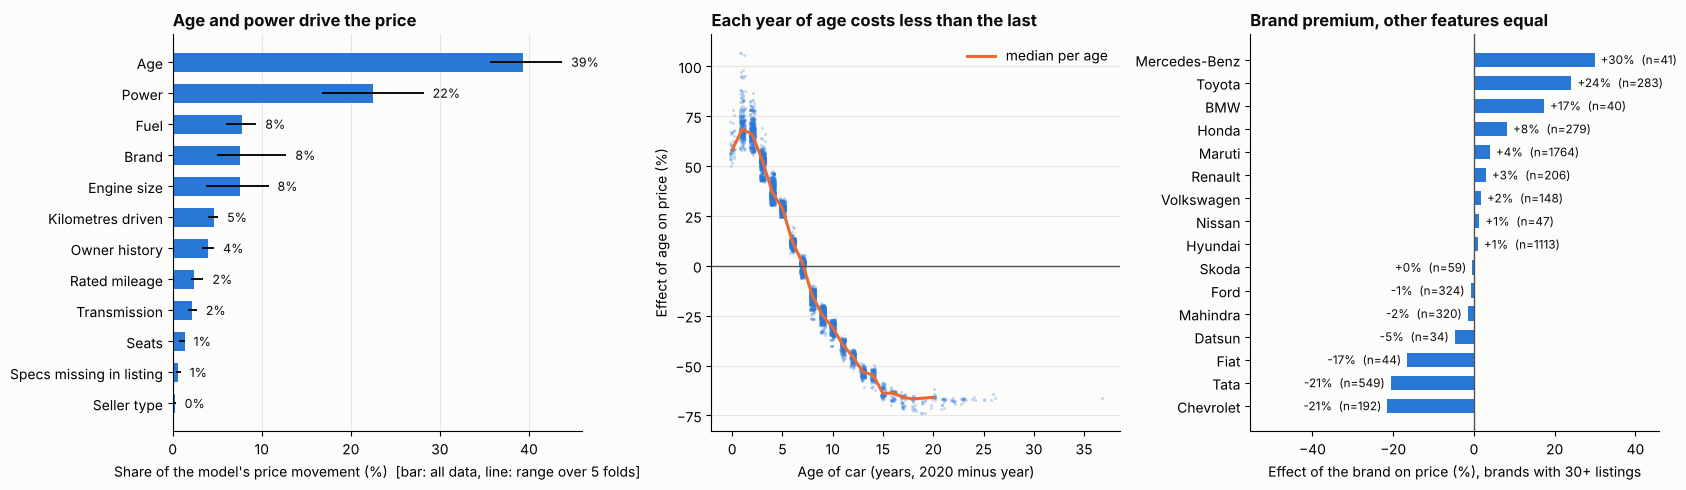

Saved: reports/figures/shap_summary.png


In [49]:
# Cell 48: figure (a: what drives the price, b: how age moves it, c: brand effect after the other features are accounted for)
BLUE, ORANGE, INK, MUTED, SURFACE = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e", "#fcfcfb"
fig, ax = plt.subplots(1, 3, figsize=(17, 5), facecolor=SURFACE)
for a in ax:
    a.set_facecolor(SURFACE)
    for side in ("top", "right"): a.spines[side].set_visible(False)

# (a) share of total importance, with the range over the 5 held-out folds
share = 100 * contrib.abs().mean() / contrib.abs().mean().sum()
fshare = 100 * fold_imp.div(fold_imp.sum(axis=1), axis=0)
order = share.sort_values().index
ax[0].barh([DRIVER_NAMES[d] for d in order], share[order], color=BLUE, height=0.62)
ax[0].hlines(range(len(order)), fshare[order].min(), fshare[order].max(), color=INK, linewidth=1.4)
for yy, d in enumerate(order): ax[0].text(max(share[d], fshare[d].max()) + 1, yy, f"{share[d]:.0f}%", va="center", fontsize=9, color=INK)
ax[0].set_xlabel("Share of the model's price movement (%)  [bar: all data, line: range over 5 folds]")
ax[0].set_title("Age and power drive the price", loc="left", fontweight="bold", color=INK); ax[0].grid(axis="x", color="#e6e5e1", linewidth=0.8); ax[0].set_axisbelow(True)

# (b) effect of age on the price, listing by listing
pct = (np.exp(contrib["age"]) - 1) * 100
jit = np.random.default_rng(1).uniform(-0.25, 0.25, len(dev))
ax[1].scatter(dev.age + jit, pct, s=5, alpha=0.25, color=BLUE, linewidths=0)
med = pct.groupby(dev.age.values).median(); med = med[dev.age.value_counts().reindex(med.index) >= 15]
ax[1].plot(med.index, med.values, color=ORANGE, linewidth=2.2, label="median per age")
ax[1].axhline(0, color=MUTED, linewidth=1); ax[1].legend(frameon=False, loc="upper right")
ax[1].set_xlabel("Age of car (years, 2020 minus year)"); ax[1].set_ylabel("Effect of age on price (%)")
ax[1].set_title("Each year of age costs less than the last", loc="left", fontweight="bold", color=INK); ax[1].grid(axis="y", color="#e6e5e1", linewidth=0.8); ax[1].set_axisbelow(True)

# (c) brand effect (listings with the same age, power, fuel etc. are priced this much above/below average because of the brand)
bt = contrib["brand"].groupby(dev.brand.values).agg(["mean", "size"]); bt = bt[bt["size"] >= 30].sort_values("mean")
bpct = (np.exp(bt["mean"]) - 1) * 100
ax[2].barh(bt.index, bpct, color=BLUE, height=0.62); ax[2].axvline(0, color=MUTED, linewidth=1)
for yy, (v, n) in enumerate(zip(bpct, bt["size"])):
    ax[2].text(v + (1.5 if v >= 0 else -1.5), yy, f"{round(v):+d}%  (n={n})", va="center", ha="left" if v >= 0 else "right", fontsize=8.5, color=INK)
ax[2].set_xlim(bpct.min() - 34, bpct.max() + 16); ax[2].set_xlabel("Effect of the brand on price (%), brands with 30+ listings")
ax[2].set_title("Brand premium, other features equal", loc="left", fontweight="bold", color=INK); ax[2].grid(axis="y", visible=False)
plt.tight_layout(); plt.savefig("../reports/figures/shap_summary.png", dpi=120, facecolor=SURFACE); plt.show()
print("Saved: reports/figures/shap_summary.png")

Hyundai i20 Asta Option 1.4 CRDi | listed INR 650,000

Average listing: INR 383,936
  Age (5 years old): +30%
  Power (89 bhp): +10%
  Fuel (Diesel): +6%
  Owner history (First Owner): +3%
  Kilometres driven (80,000 km): -2%
  Transmission (Manual): -1%
Fair price for this listing: INR 585,188

Deal Score 40.9 (Moderate Overpriced): fair range INR 450,541 to 804,137


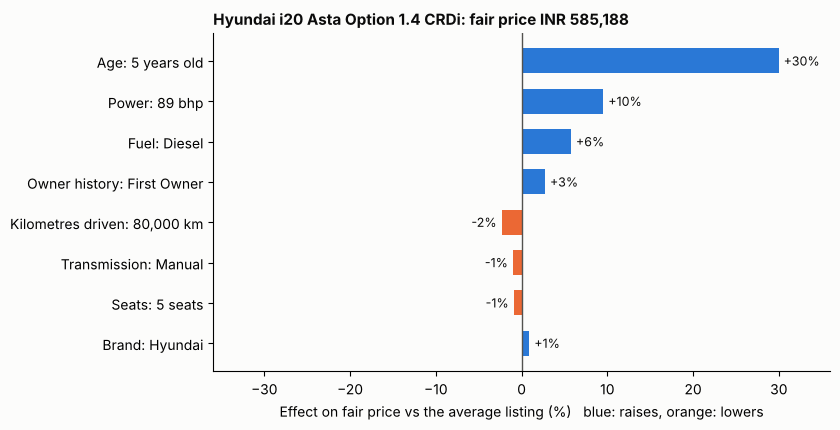

Saved: reports/figures/shap_listing_example.png


In [50]:
# Cell 49: explaining ONE listing, exactly as the demo app will (src/explain.py + src/deal_score.py)
import src.explain as xp
ex_row = dev[(dev.brand == "Hyundai") & (dev.fuel == "Diesel") & dev.age.between(4, 6)].sample(1, random_state=7).iloc[0]
exp1 = xp.explain_listing(ex_row)
ds1 = ds.deal_score(ex_row, ex_row.selling_price)
assert abs(exp1["predicted_price"] - ds1["predicted_price"]) < 0.01                  # the explanation and the Deal Score use the same fair price
assert abs(exp1["base_price"] * exp1["drivers"].factor.prod() - exp1["predicted_price"]) < 0.01
print(ex_row["name"], f"| listed INR {ex_row.selling_price:,.0f}\n")
print(xp.format_explanation(exp1, top=6))
print(f"\nDeal Score {ds1['deal_score']} ({ds1['graded_label']}): fair range INR {ds1['lower_bound']:,.0f} to {ds1['upper_bound']:,.0f}")

d = exp1["drivers"].head(8).iloc[::-1]
fig, a = plt.subplots(figsize=(8.5, 4.4), facecolor=SURFACE); a.set_facecolor(SURFACE)
a.barh([f"{r.driver}: {r.value}" for r in d.itertuples()], d.effect_pct, color=[BLUE if v >= 0 else ORANGE for v in d.effect_pct], height=0.62)
a.axvline(0, color=MUTED, linewidth=1)
for yy, v in enumerate(d.effect_pct): a.text(v + (0.6 if v >= 0 else -0.6), yy, f"{v:+.0f}%", va="center", ha="left" if v >= 0 else "right", fontsize=9, color=INK)
lim = d.effect_pct.abs().max() + 6; a.set_xlim(-lim, lim)
for side in ("top", "right"): a.spines[side].set_visible(False)
a.set_xlabel("Effect on fair price vs the average listing (%)   blue: raises, orange: lowers")
a.set_title(f"{ex_row['name']}: fair price INR {exp1['predicted_price']:,.0f}", loc="left", fontweight="bold", color=INK, fontsize=11)
plt.tight_layout(); plt.savefig("../reports/figures/shap_listing_example.png", dpi=120, facecolor=SURFACE); plt.show()
print("Saved: reports/figures/shap_listing_example.png")

**Findings**
- **Two features carry most of the price: age (39% of the model's price movement) and power (22%).** Fuel, brand and engine size follow with about 8% each; kilometres, owner history, rated mileage and transmission are small; seller type and the missing-specs flag are close to nothing. A typical listing's price moves by about +/-45% because of its age and +/-23% because of its power, against +/-7% for fuel or brand.
- **The ranking is stable and a second method agrees.** Refitting on 4/5 of the car models and explaining the held-out 1/5, age and power are first and second in all five folds; the folds agree with each other (rank correlation 0.92 at the lowest, 0.97 median), and SHAP agrees with permutation importance (0.94).
- **The directions make sense.** Newer, more powerful, lower-km, first-owner and automatic listings are priced higher. Age costs the most early: the effect falls from about +65% for a new car to about -65% at 15 years, then flattens (depreciation slows). Brand effects, after the other features are accounted for: Mercedes-Benz +30%, Toyota +24%, BMW +17% at the top; Chevrolet -21%, Tata -21%, Fiat -17% at the bottom.
- **Do not over-read the small features.** Kilometres is only 5% because it is strongly correlated with age, and SHAP shares credit among correlated features: it does not mean mileage is irrelevant. Rated mileage and seats are different: shuffling them does not raise the error on held-out car models (it helps in 1 of 5 folds), so they add no usable signal there. They are candidates for removal, but dropping them would need a fresh round of validation, so they stay for now. Levels with few listings (LPG 33, CNG 48, Trustmark Dealer 19) are too thin to interpret.
- **This explains the model, not the market.** The effects are not causal (a model that has seen a Tata Nano price assigns it a low brand effect; it does not know why), they come from 2020 asking prices, and they explain the *fair price* only. The gap between the asking price and that fair price is the Deal Score. Cell 49 shows the two together for one listing, which is what the demo will display: fair price, the drivers behind it, and the score.

## 12. Validating the Deal Score

The Deal Score says "Underpriced", "Fair" or "Overpriced" by comparing the asking price with the 90% range from Section 6. Nobody has labelled real listings as bargains, so there is **no ground truth** to score it against. This section measures what *can* be measured:

- **Detection power:** change a listing's price by a known amount and ask how often the Deal Score notices, in the right direction.
- **False alarms:** how often it flags listings whose price we did not touch. This is an *upper bound* on the true false-alarm rate, because some untouched listings may really be mispriced.
- **A confidence flag:** a warning for listings where the price estimate is known to be weaker (rare car models, old cars, missing specs), and a test of whether that warning is worth showing.

All numbers use **out-of-fold** predictions on the development set (never the saved all-data models, which have already seen these listings), in the same two regimes as before: **unseen car models** (grouped CV) and **repeat listings** (twin groups kept in one fold, Section 8). The locked test set is not used and no model is changed here.

### 12.1 Rules fixed before looking at any result

| Item | Rule |
|---|---|
| Price change | listed price × m. Pre-planned grid 0.70 to 1.30 (0.70, 0.80, 0.90, 0.95, 1.05, 1.10, 1.20, 1.30); 0.50, 0.60, 1.50 and 2.00 are added only to find where detection reaches 50% and 80% |
| Label | "Under" / "Over" = the changed price falls outside the Section 6 interval of the selected candidate. Same rule as `src/deal_score.py`; the 5-level label uses position cut-offs at ±0.33 and ±1.0 |
| Detection | flagged in the correct direction after the change (Over for m > 1, Under for m < 1) |
| False alarm | share of **untouched** listings flagged either way |
| Confidence components | (i) rare model: fewer than 10 listings of that car model in the training folds (0 = unknown). Evaluated in the repeat regime only, because in the unseen regime it is true for every listing by construction. (ii) old car: age of 13 years or more. (iii) specs missing: engine, power or seats missing |
| Adopting a component | median absolute % error of flagged listings at least 1.3 × that of unflagged listings, **and** flagged share between 3% and 40%, in every regime where it is evaluated |
| Success of the combined flag | (a) error ratio at least 1.3 in each regime; (b) the false-alarm rate among *unflagged* listings is not higher than among all listings |
| Design consequence | labels on flagged listings are suppressed only if (a) and (b) both pass in every regime; otherwise the app keeps the label and shows a low-confidence notice |
| Margin check (lesson of D32) | a 95% bootstrap interval for each error ratio, resampling whole car models; if its lower limit is below 1.3, the adoption is reported as "within sampling error" |

One part is **exploratory and was added after seeing the injection results**: the operating curve in 12.5 (how detection and false alarms trade off if the flag threshold moves). It changes no rule above.

In [51]:
# Cell 50: out-of-fold inputs for the validation (two regimes), and checks that they match Sections 6, 8 and src/deal_score.py
from IPython.display import Markdown
import src.deal_validation as dv
import src.deal_score as ds

assert winner_name in twin_oof, "Section 8 stored twin-grouped intervals only for candidates A and C"
yl = dev.log_price.values                                          # listed price (log) = the actual asking price
REG = {"Unseen car models": {"pred": oof_g, "lo": cand_g_oof[winner_name][0], "hi": cand_g_oof[winner_name][1]},
       "Repeat listings":   {"pred": oof_s, "lo": twin_oof[winner_name][0],   "hi": twin_oof[winner_name][1]}}

# how many listings of the same car model sit in each listing's TRAINING folds
# (repeat regime: counted fold by fold; unseen regime: zero by construction, the whole car model is held out)
n_train_rep = np.zeros(len(dev), int)
for tr, va in twin_cv.split(dev[FEATS], groups=twin_id):
    counts_tr = dev.model_key.iloc[tr].value_counts()
    n_train_rep[va] = dev.model_key.iloc[va].map(counts_tr).fillna(0).astype(int).values
REG["Unseen car models"]["n_train"] = np.zeros(len(dev), int)
REG["Repeat listings"]["n_train"] = n_train_rep

AGE_B = pd.cut(dev.age, [-1, 3, 7, 12, 40], labels=["0-3 yrs", "4-7 yrs", "8-12 yrs", "13+ yrs"]).astype(str).values
PQ = ["P1 lowest", "P2", "P3", "P4", "P5 highest"]
for name, R in REG.items():
    price_pred = np.exp(R["pred"])
    R["ape"] = 100 * np.abs(price_pred - dev.selling_price.values) / dev.selling_price.values   # point-model error, % of the listed price
    R["pred_q"] = pd.qcut(price_pred, 5, labels=PQ).astype(str)                                 # the price a buyer sees, not the true one
    R["flags"] = dv.confidence_flags(dev.age.values, dev.specs_missing.values, R["n_train"])
    R["segments"] = {"all": np.ones(len(dev), bool),
                     **{f"pred {q}": R["pred_q"] == q for q in PQ},
                     **{f: dev.fuel.values == f for f in ["Diesel", "Petrol"]},
                     **{f"age {a}": AGE_B == a for a in ["0-3 yrs", "4-7 yrs", "8-12 yrs", "13+ yrs"]}}

check = pd.DataFrame({name: {"interval coverage %": round(100 * np.mean((yl >= R["lo"]) & (yl <= R["hi"])), 2),
                             "median width, % of price": round(np.median(100 * (np.exp(R["hi"]) - np.exp(R["lo"])) / dev.selling_price.values), 1),
                             "point-model MedAPE %": round(np.median(R["ape"]), 2)} for name, R in REG.items()})
display(check)
assert abs(check.loc["interval coverage %", "Unseen car models"] - cand_summary_df.loc[winner_name, "G_cov_%"]) < 0.01
assert abs(check.loc["median width, % of price", "Unseen car models"] - cand_summary_df.loc[winner_name, "G_wid_%"]) < 0.06
print(f"Reproduction check passed: these are the out-of-fold intervals of {winner_name} evaluated in Sections 6 and 8.")

# the labelling functions used here must agree with the production function on real calls
LAB3 = {"Underpriced": "Under", "Fair": "Fair", "Overpriced": "Over"}
LAB5 = {"Deep Underpriced": "Deep under", "Moderate Underpriced": "Moderate under", "Fair Price": "Fair",
        "Moderate Overpriced": "Moderate over", "Deep Overpriced": "Deep over"}
parity_n, parity_bad = 0, 0
for _, row in dev.sample(150, random_state=0).iterrows():
    for m in (0.8, 1.0, 1.2):
        out = ds.deal_score(row, row.selling_price * m)
        parity_n += 1
        parity_bad += int(dv.three_level(out["listed_price"], out["lower_bound"], out["upper_bound"])[()] != LAB3[out["label"]]
                          or dv.five_level(out["position"])[()] != LAB5[out["graded_label"]])
print(f"Label parity with src/deal_score.py: {parity_n - parity_bad} of {parity_n} calls identical.")
assert parity_bad == 0

,Unseen car models,Repeat listings
interval coverage %,88.17,90.45
"median width, % of price",85.70,65.20
point-model MedAPE %,17.57,11.90


Reproduction check passed: these are the out-of-fold intervals of C_Adaptive_CQR evaluated in Sections 6 and 8.


Label parity with src/deal_score.py: 450 of 450 calls identical.


In [52]:
# Cell 51: price-injection test -- detection of a known price change, and false alarms on untouched listings
MULT = [0.50, 0.60, 0.70, 0.80, 0.90, 0.95, 1.05, 1.10, 1.20, 1.30, 1.50, 2.00]
det, fa = {}, {}
for name, R in REG.items():
    det[name] = dv.detection_table(yl, R["lo"], R["hi"], R["segments"], MULT)
    lab0 = dv.three_level(yl, R["lo"], R["hi"])                                  # untouched listings
    fa[name] = pd.DataFrame({seg: {"flagged Underpriced %": 100 * np.mean(lab0[m] == "Under"),
                                    "flagged Overpriced %": 100 * np.mean(lab0[m] == "Over"),
                                    "flagged either way %": 100 * np.mean(lab0[m] != "Fair")}
                             for seg, m in R["segments"].items()}).T
    n_row = pd.DataFrame({seg: [int(m.sum())] for seg, m in R["segments"].items()}, index=["n listings"])
    print(f"=== {name}: detection rate (%) of a price change by factor m (rows) and segment (columns) ===")
    display(pd.concat([n_row, det[name].round(1)]))
    print(f"--- {name}: UNTOUCHED listings flagged (false-alarm upper bound) ---")
    display(fa[name].round(1).assign(n=n_row.T["n listings"]))

=== Unseen car models: detection rate (%) of a price change by factor m (rows) and segment (columns) ===


,all,pred P1 lowest,pred P2,pred P3,pred P4,pred P5 highest,Diesel,Petrol,age 0-3 yrs,age 4-7 yrs,age 8-12 yrs,age 13+ yrs
n listings,5530.0,1106.0,1106.0,1106.0,1106.0,1106.0,3023.0,2426.0,1420.0,1949.0,1668.0,493.0
x0.50,78.2,66.6,76.8,83.3,92.0,72.3,75.3,81.7,85.2,83.3,73.7,53.1
x0.60,61.8,50.4,55.0,66.6,78.2,58.6,60.6,63.1,71.8,65.1,56.1,38.9
x0.70,39.4,34.3,33.6,41.7,50.5,37.1,38.8,40.1,46.4,40.6,36.8,23.5
x0.80,21.6,23.9,17.8,22.2,26.2,18.2,21.7,21.6,23.4,21.8,22.0,14.8
x0.90,11.7,15.4,10.2,12.0,13.5,7.6,12.2,11.3,11.1,11.5,13.4,8.5
x0.95,8.8,13.0,7.4,9.7,9.0,4.8,9.3,8.4,7.0,9.1,10.3,7.7
x1.05,7.7,2.1,5.8,11.4,8.0,11.3,9.7,5.1,10.1,8.8,5.5,3.7
x1.10,11.6,4.0,8.3,15.5,12.9,17.1,13.8,8.6,16.5,13.2,7.1,5.9
x1.20,20.6,6.6,17.1,24.3,25.9,28.9,22.4,18.0,31.5,23.9,11.0,8.3


--- Unseen car models: UNTOUCHED listings flagged (false-alarm upper bound) ---


,flagged Underpriced %,flagged Overpriced %,flagged either way %,n
all,6.8,5.1,11.8,5530
pred P1 lowest,11.0,1.4,12.4,1106
pred P2,6.5,3.3,9.9,1106
pred P3,6.5,7.9,14.4,1106
pred P4,6.3,5.4,11.8,1106
pred P5 highest,3.4,7.3,10.8,1106
Diesel,7.6,6.8,14.4,3023
Petrol,5.9,2.8,8.7,2426
age 0-3 yrs,4.6,6.3,11.0,1420
age 4-7 yrs,6.7,5.8,12.6,1949


=== Repeat listings: detection rate (%) of a price change by factor m (rows) and segment (columns) ===


,all,pred P1 lowest,pred P2,pred P3,pred P4,pred P5 highest,Diesel,Petrol,age 0-3 yrs,age 4-7 yrs,age 8-12 yrs,age 13+ yrs
n listings,5530.0,1106.0,1106.0,1106.0,1106.0,1106.0,3023.0,2426.0,1420.0,1949.0,1668.0,493.0
x0.50,89.3,77.2,92.6,96.3,98.2,82.2,88.4,90.3,93.0,94.0,87.4,66.1
x0.60,75.8,59.4,78.3,84.5,89.8,66.9,72.2,80.0,84.2,82.7,68.8,47.9
x0.70,54.3,40.1,56.1,62.7,66.9,45.8,50.9,58.2,65.2,58.3,47.5,30.0
x0.80,29.8,23.5,34.3,36.4,33.7,21.1,26.9,33.3,33.5,32.5,26.9,18.1
x0.90,12.7,12.6,15.9,15.3,12.7,7.1,11.1,14.7,12.2,13.9,12.5,10.3
x0.95,8.0,9.0,10.0,9.4,7.5,3.9,7.0,9.3,6.3,9.0,8.3,7.3
x1.05,8.2,3.7,5.9,10.3,9.1,11.8,8.8,7.2,11.7,7.8,6.9,3.9
x1.10,13.2,4.9,9.9,16.1,15.2,19.8,14.0,11.9,20.4,12.9,9.8,4.9
x1.20,26.9,7.5,20.8,30.7,34.7,40.7,28.2,25.0,43.2,28.1,17.3,7.7


--- Repeat listings: UNTOUCHED listings flagged (false-alarm upper bound) ---


,flagged Underpriced %,flagged Overpriced %,flagged either way %,n
all,4.8,4.7,9.5,5530
pred P1 lowest,5.9,3.3,9.1,1106
pred P2,5.8,2.9,8.7,1106
pred P3,5.2,5.7,10.8,1106
pred P4,4.6,4.9,9.5,1106
pred P5 highest,2.6,7.0,9.6,1106
Diesel,4.3,5.4,9.7,3023
Petrol,5.6,4.0,9.6,2426
age 0-3 yrs,3.7,5.8,9.5,1420
age 4-7 yrs,5.4,4.1,9.5,1949


In [53]:
# Cell 52: reading the injection results (every number below is computed above)
gU, gR = det["Unseen car models"], det["Repeat listings"]
faU, faR = fa["Unseen car models"].loc["all"], fa["Repeat listings"].loc["all"]
wid = {name: np.median(100 * (np.exp(R["hi"]) - np.exp(R["lo"])) / dev.selling_price.values) for name, R in REG.items()}
tw = dev.groupby(TWIN_KEY).selling_price.agg(n="size", lo="min", hi="max")
tw = tw[tw.n > 1]
tw_spread = (tw.hi / tw.lo - 1) * 100                                            # same car listed at different prices (Section 8)

def extremes(tab, row, prefix):
    s = tab.loc[row, [c for c in tab.columns if c.startswith(prefix)]]
    return f"weakest {s.idxmin()} ({s.min():.0f}%), strongest {s.idxmax()} ({s.max():.0f}%)"

text = f"""**Insight: the Deal Score reliably catches only large price gaps.**
After a **+20%** markup the Deal Score says "Overpriced" for **{gU.loc['x1.20', 'all']:.0f}%** of unseen-model listings and **{gR.loc['x1.20', 'all']:.0f}%** of repeat listings; after **+30%** it is {gU.loc['x1.30', 'all']:.0f}% and {gR.loc['x1.30', 'all']:.0f}%, after **+50%** {gU.loc['x1.50', 'all']:.0f}% and {gR.loc['x1.50', 'all']:.0f}%.
For price cuts, **-20%** is detected {gU.loc['x0.80', 'all']:.0f}% / {gR.loc['x0.80', 'all']:.0f}% of the time and **-30%** {gU.loc['x0.70', 'all']:.0f}% / {gR.loc['x0.70', 'all']:.0f}% (unseen / repeat).
Untouched listings are flagged either way {faU['flagged either way %']:.1f}% / {faR['flagged either way %']:.1f}% of the time; a +10% markup raises "Overpriced" from {faU['flagged Overpriced %']:.1f}% to {gU.loc['x1.10', 'all']:.1f}% (unseen) and from {faR['flagged Overpriced %']:.1f}% to {gR.loc['x1.10', 'all']:.1f}% (repeat), so small gaps barely move the flag.
Cuts are detected more often than markups of the same ratio (-30%: {gU.loc['x0.70', 'all']:.0f}% vs +30%: {gU.loc['x1.30', 'all']:.0f}% for unseen models); in log space x0.70 is a bigger move than x1.30 (-0.36 against +0.26).

**Why the range is wide.** Its median width is {wid['Unseen car models']:.0f}% of the price for unseen car models and {wid['Repeat listings']:.0f}% for repeat listings (Section 6). The *same* car (same name, year, kilometres, fuel, seller type, transmission and owner) is listed at prices that differ by a median {tw_spread.median():.1f}% (75th percentile {tw_spread.quantile(.75):.1f}%, Section 8), so part of the width may be noise in asking prices rather than model error. That is a hypothesis: we did not separate the two.

**Where a +20% markup is hardest to detect** (detection rate, unseen / repeat):
by age, {extremes(gU, 'x1.20', 'age ')} / {extremes(gR, 'x1.20', 'age ')};
by predicted price, {extremes(gU, 'x1.20', 'pred ')} / {extremes(gR, 'x1.20', 'pred ')}."""
display(Markdown(text))

**Insight: the Deal Score reliably catches only large price gaps.**
After a **+20%** markup the Deal Score says "Overpriced" for **21%** of unseen-model listings and **27%** of repeat listings; after **+30%** it is 31% and 41%, after **+50%** 50% and 63%.
For price cuts, **-20%** is detected 22% / 30% of the time and **-30%** 39% / 54% (unseen / repeat).
Untouched listings are flagged either way 11.8% / 9.5% of the time; a +10% markup raises "Overpriced" from 5.1% to 11.6% (unseen) and from 4.7% to 13.2% (repeat), so small gaps barely move the flag.
Cuts are detected more often than markups of the same ratio (-30%: 39% vs +30%: 31% for unseen models); in log space x0.70 is a bigger move than x1.30 (-0.36 against +0.26).

**Why the range is wide.** Its median width is 86% of the price for unseen car models and 65% for repeat listings (Section 6). The *same* car (same name, year, kilometres, fuel, seller type, transmission and owner) is listed at prices that differ by a median 11.6% (75th percentile 23.3%, Section 8), so part of the width may be noise in asking prices rather than model error. That is a hypothesis: we did not separate the two.

**Where a +20% markup is hardest to detect** (detection rate, unseen / repeat):
by age, weakest age 13+ yrs (8%), strongest age 0-3 yrs (32%) / weakest age 13+ yrs (8%), strongest age 0-3 yrs (43%);
by predicted price, weakest pred P1 lowest (7%), strongest pred P5 highest (29%) / weakest pred P1 lowest (8%), strongest pred P5 highest (41%).

In [54]:
# Cell 53: the smallest tested change that is detected at least half / four-fifths of the time
mind = {name: dv.min_detectable(tab) for name, tab in det.items()}
for name, t in mind.items():
    print(f"=== {name} ('x0.70' = a 30% cut; 'not reached' = not reached anywhere on the tested grid 0.50 to 2.00) ===")
    display(t)
a, b = mind["Unseen car models"].loc["all"], mind["Repeat listings"].loc["all"]
display(Markdown(f"**Insight:** smallest tested change detected at least half the time (x0.60 = a 40% cut, x1.50 = a 50% markup): unseen models, cut {a['cut >= 50%']}, markup {a['rise >= 50%']}; repeat listings, cut {b['cut >= 50%']}, markup {b['rise >= 50%']}. "
                 f"At least 80% of the time: unseen models, cut {a['cut >= 80%']}, markup {a['rise >= 80%']}; repeat listings, cut {b['cut >= 80%']}, markup {b['rise >= 80%']}. The grid is coarse; read these as bands, not exact thresholds."))

=== Unseen car models ('x0.70' = a 30% cut; 'not reached' = not reached anywhere on the tested grid 0.50 to 2.00) ===


,cut >= 50%,rise >= 50%,cut >= 80%,rise >= 80%
all,x0.60,x1.50,not reached,not reached
pred P1 lowest,x0.60,not reached,not reached,not reached
pred P2,x0.60,x2.00,not reached,not reached
pred P3,x0.60,x1.50,x0.50,x2.00
pred P4,x0.70,x1.50,x0.50,x2.00
pred P5 highest,x0.60,x1.50,not reached,x2.00
Diesel,x0.60,x1.50,not reached,not reached
Petrol,x0.60,x2.00,x0.50,not reached
age 0-3 yrs,x0.60,x1.50,x0.50,x2.00
age 4-7 yrs,x0.60,x1.50,x0.50,x2.00


=== Repeat listings ('x0.70' = a 30% cut; 'not reached' = not reached anywhere on the tested grid 0.50 to 2.00) ===


,cut >= 50%,rise >= 50%,cut >= 80%,rise >= 80%
all,x0.70,x1.50,x0.50,x2.00
pred P1 lowest,x0.60,x2.00,not reached,not reached
pred P2,x0.70,x1.50,x0.50,x2.00
pred P3,x0.70,x1.50,x0.60,x2.00
pred P4,x0.70,x1.30,x0.60,x1.50
pred P5 highest,x0.60,x1.30,x0.50,x1.50
Diesel,x0.70,x1.50,x0.50,x2.00
Petrol,x0.70,x1.50,x0.60,x2.00
age 0-3 yrs,x0.70,x1.30,x0.60,x1.50
age 4-7 yrs,x0.70,x1.50,x0.60,x2.00


**Insight:** smallest tested change detected at least half the time (x0.60 = a 40% cut, x1.50 = a 50% markup): unseen models, cut x0.60, markup x1.50; repeat listings, cut x0.70, markup x1.50. At least 80% of the time: unseen models, cut not reached, markup not reached; repeat listings, cut x0.50, markup x2.00. The grid is coarse; read these as bands, not exact thresholds.

### 12.3 The confidence flag

Section 9 found that errors are not spread evenly: they grow with age, are worse when specs are missing, and concentrate in car models the data barely contains. A Deal Score that says "Overpriced" about a 2005 car with no specs deserves less trust than the same label for a recent, well-known car. The cells below test the three components fixed in 12.1.

In [55]:
# Cell 54: which components of the flag point at worse price estimates?  (rules from 12.1; nothing is tuned here)
B, MIN_RATIO, SHARE_LO, SHARE_HI = 1000, 1.3, 3.0, 40.0
rng = np.random.default_rng(0)
model_codes = pd.factorize(dev.model_key)[0]
rows_by_model = [np.where(model_codes == g)[0] for g in range(model_codes.max() + 1)]

def ratio_ci(ape, flag):
    """95% bootstrap interval of (median error flagged / median error unflagged), resampling whole car models."""
    out = []
    for _ in range(B):
        ii = np.concatenate([rows_by_model[g] for g in rng.integers(0, len(rows_by_model), len(rows_by_model))])
        a, f = ape[ii], flag[ii]
        if f.sum() >= 5 and (~f).sum() >= 5:
            out.append(np.median(a[f]) / np.median(a[~f]))
    return np.percentile(out, [2.5, 97.5])

comp_rows = []
for name, R in REG.items():
    for c in ["old_car", "specs_missing"] + (["rare_model"] if name == "Repeat listings" else []):
        f = R["flags"][c].values
        e = dv.error_by_flag(R["ape"], f)
        lo_ci, hi_ci = ratio_ci(R["ape"], f)
        comp_rows.append({"regime": name, "component": c, "flagged share %": e["flagged share %"], "n flagged": e["n flagged"],
                          "median error flagged %": e["median error flagged %"], "median error unflagged %": e["median error unflagged %"],
                          "ratio": e["ratio"], "95% CI low": round(lo_ci, 2), "95% CI high": round(hi_ci, 2),
                          "share in 3-40%": SHARE_LO <= e["flagged share %"] <= SHARE_HI, "ratio >= 1.3": e["ratio"] >= MIN_RATIO,
                          "CI low >= 1.3": lo_ci >= MIN_RATIO})
comp_df = pd.DataFrame(comp_rows).set_index(["regime", "component"])
comp_df["passes rule"] = comp_df["share in 3-40%"] & comp_df["ratio >= 1.3"]
display(comp_df)

adopted = comp_df.groupby(level="component")["passes rule"].all()              # a component must pass in EVERY regime where it is evaluated
ADOPTED = adopted[adopted].index.tolist()
within_noise = comp_df[comp_df["passes rule"] & ~comp_df["CI low >= 1.3"]].index.tolist()
print("Adopted components:", ADOPTED, "| dropped:", adopted[~adopted].index.tolist())
print("Adoptions whose bootstrap interval reaches below 1.3 (within sampling error):", within_noise if within_noise else "none")

for name, R in REG.items():                                                     # combined flag = any adopted component evaluated in this regime
    R["flag_used"] = [c for c in ADOPTED if c != "rare_model" or name == "Repeat listings"]
    R["flag_any"] = R["flags"][R["flag_used"]].any(axis=1).values

flagged share %  n flagged  \
regime            component                                   
Unseen car models old_car                    8.9        493   
                  specs_missing              3.4        188   
Repeat listings   old_car                    8.9        493   
                  specs_missing              3.4        188   
                  rare_model                 7.5        416   

                                 median error flagged %  \
regime            component                               
Unseen car models old_car                          29.9   
                  specs_missing                    25.5   
Repeat listings   old_car                          24.2   
                  specs_missing                    21.6   
                  rare_model                       17.9   

                                 median error unflagged %  ratio  95% CI low  \
regime            component                                                    
Unseen car models old_car                            16.8   1.78        1.43   
                  specs_missing                      17.3   1.47        1.22   
Repeat listings   old_car                            11.2   2.16        1.83   
                  specs_missing                      11.6   1.86        1.53   
                  rare_model                         11.5   1.56        1.31   

                                 95% CI high  share in 3-40%  ratio >= 1.3  \
regime            component                                                  
Unseen car models old_car               2.28            True          True   
                  specs_missing         1.87            True          True   
Repeat listings   old_car               2.51            True          True   
                  specs_missing         2.40            True          True   
                  rare_model            1.83            True          True   

                                 CI low >= 1.3  passes rule  
regime            component                                  
Unseen car models old_car                 True         True  
                  specs_missing          False         True  
Repeat listings   old_car                 True         True  
                  specs_missing           True         True  
                  rare_model              True         True

Adopted components: ['old_car', 'rare_model', 'specs_missing'] | dropped: []
Adoptions whose bootstrap interval reaches below 1.3 (within sampling error): [('Unseen car models', 'specs_missing')]


In [56]:
# Cell 55: does the flag point at listings whose range is wider, and does it change false alarms or detection?
def group_summary(R, m):
    lab0 = dv.three_level(yl, R["lo"], R["hi"])
    return {"n": int(m.sum()), "median error %": round(np.median(R["ape"][m]), 1),
            "median range width, % of price": round(np.median(100 * (np.exp(R["hi"][m]) - np.exp(R["lo"][m])) / dev.selling_price.values[m]), 1),
            "interval coverage %": round(100 * np.mean((yl[m] >= R["lo"][m]) & (yl[m] <= R["hi"][m])), 1),
            "untouched flagged either way %": round(100 * np.mean(lab0[m] != "Fair"), 1),
            "detect +20% %": round(dv.detection_rate(yl, R["lo"], R["hi"], 1.2, m), 1),
            "detect -20% %": round(dv.detection_rate(yl, R["lo"], R["hi"], 0.8, m), 1)}

eval_rows = []
for name, R in REG.items():
    f = R["flag_any"]
    for grp, m in (("flagged (low confidence)", f), ("unflagged", ~f), ("all listings", np.ones(len(f), bool))):
        eval_rows.append({"regime": name, "group": grp, **group_summary(R, m)})
flag_eval = pd.DataFrame(eval_rows).set_index(["regime", "group"])
print("Components used in the combined flag:", {name: R["flag_used"] for name, R in REG.items()})
display(flag_eval)

# success criteria fixed in 12.1
crit = []
for name, R in REG.items():
    e = dv.error_by_flag(R["ape"], R["flag_any"])
    lo_ci, hi_ci = ratio_ci(R["ape"], R["flag_any"])
    fa_unfl = flag_eval.loc[(name, "unflagged"), "untouched flagged either way %"]
    fa_all = flag_eval.loc[(name, "all listings"), "untouched flagged either way %"]
    crit.append({"regime": name, "flagged share %": e["flagged share %"], "error ratio": e["ratio"], "ratio 95% CI": f"{lo_ci:.2f} to {hi_ci:.2f}",
                 "(a) ratio >= 1.3": e["ratio"] >= MIN_RATIO, "false alarms unflagged %": fa_unfl, "false alarms all %": fa_all,
                 "(b) unflagged <= all": fa_unfl <= fa_all})
crit_df = pd.DataFrame(crit).set_index("regime")
display(crit_df)
SUPPRESS = bool(crit_df["(a) ratio >= 1.3"].all() and crit_df["(b) unflagged <= all"].all())
print("Design decision from the pre-registered rule:",
      "suppress Under/Over labels on low-confidence listings" if SUPPRESS else
      "keep the Under/Over label and show a low-confidence notice (criterion (a) and (b) did not both pass in every regime)")

# model familiarity, as the app will see it
rep, uns = REG["Repeat listings"], REG["Unseen car models"]
status = pd.DataFrame({
    "repeat: known model (>=10 training listings)": group_summary(rep, rep["n_train"] >= 10),
    "repeat: rare model (1-9)": group_summary(rep, (rep["n_train"] >= 1) & (rep["n_train"] < 10)),
    "repeat: unknown model (0)": group_summary(rep, rep["n_train"] == 0),
    "unseen regime: every listing (model held out)": group_summary(uns, np.ones(len(dev), bool))}).T
print("=== Error and range width by how well the car model is known ===")
display(status)

Components used in the combined flag: {'Unseen car models': ['old_car', 'specs_missing'], 'Repeat listings': ['old_car', 'rare_model', 'specs_missing']}


n  median error %  \
regime            group                                            
Unseen car models flagged (low confidence)   590            27.6   
                  unflagged                 4940            16.8   
                  all listings              5530            17.6   
Repeat listings   flagged (low confidence)   930            20.2   
                  unflagged                 4600            10.8   
                  all listings              5530            11.9   

                                            median range width, % of price  \
regime            group                                                      
Unseen car models flagged (low confidence)                           178.0   
                  unflagged                                           81.2   
                  all listings                                        85.7   
Repeat listings   flagged (low confidence)                           113.7   
                  unflagged                                           60.9   
                  all listings                                        65.2   

                                            interval coverage %  \
regime            group                                           
Unseen car models flagged (low confidence)                 91.0   
                  unflagged                                87.8   
                  all listings                             88.2   
Repeat listings   flagged (low confidence)                 88.7   
                  unflagged                                90.8   
                  all listings                             90.5   

                                            untouched flagged either way %  \
regime            group                                                      
Unseen car models flagged (low confidence)                             9.0   
                  unflagged                                           12.2   
                  all listings                                        11.8   
Repeat listings   flagged (low confidence)                            11.3   
                  unflagged                                            9.2   
                  all listings                                         9.5   

                                            detect +20% %  detect -20% %  
regime            group                                                   
Unseen car models flagged (low confidence)            7.6           14.2  
                  unflagged                          22.1           22.5  
                  all listings                       20.6           21.6  
Repeat listings   flagged (low confidence)           18.0           19.2  
                  unflagged                          28.7           31.9  
                  all listings                       26.9           29.8

,flagged share %,error ratio,ratio 95% CI,(a) ratio >= 1.3,false alarms unflagged %,false alarms all %,(b) unflagged <= all
regime,,,,,,,
Unseen car models,10.7,1.65,1.38 to 2.03,True,12.2,11.8,False
Repeat listings,16.8,1.87,1.60 to 2.10,True,9.2,9.5,True


Design decision from the pre-registered rule: keep the Under/Over label and show a low-confidence notice (criterion (a) and (b) did not both pass in every regime)
=== Error and range width by how well the car model is known ===


,n,median error %,"median range width, % of price",interval coverage %,untouched flagged either way %,detect +20% %,detect -20% %
repeat: known model (>=10 training listings),5114.0,11.5,64.1,90.9,9.1,26.7,30.7
repeat: rare model (1-9),377.0,16.9,87.2,85.9,14.1,27.6,19.1
repeat: unknown model (0),39.0,28.6,104.5,71.8,28.2,41.0,12.8
unseen regime: every listing (model held out),5530.0,17.6,85.7,88.2,11.8,20.6,21.6


In [57]:
# Cell 56: reading the confidence-flag results
fU, fR = flag_eval.loc["Unseen car models"], flag_eval.loc["Repeat listings"]
cU, cR = crit_df.loc["Unseen car models"], crit_df.loc["Repeat listings"]
dropped = adopted[~adopted].index.tolist()
bok = bool(cU['(b) unflagged <= all'] and cR['(b) unflagged <= all'])
text = f"""**Insight: the flag points at worse price estimates{' and at fewer false alarms among the rest' if bok else ', but it does not lower the false-alarm rate in every regime'}.**
Components kept by the rule: {', '.join(ADOPTED) if ADOPTED else 'none'}{'; dropped: ' + ', '.join(dropped) if dropped else ''}. The combined flag marks {cU['flagged share %']:.1f}% of unseen-model listings and {cR['flagged share %']:.1f}% of repeat listings.
Flagged listings have a median price error of **{fU.loc['flagged (low confidence)', 'median error %']:.1f}%** against {fU.loc['unflagged', 'median error %']:.1f}% (unseen models) and **{fR.loc['flagged (low confidence)', 'median error %']:.1f}%** against {fR.loc['unflagged', 'median error %']:.1f}% (repeat listings), a ratio of {cU['error ratio']:.2f} and {cR['error ratio']:.2f} (bootstrap intervals {cU['ratio 95% CI']} and {cR['ratio 95% CI']}).
The adaptive intervals of Section 6c already give flagged listings wider ranges (median {fU.loc['flagged (low confidence)', 'median range width, % of price']:.0f}% against {fU.loc['unflagged', 'median range width, % of price']:.0f}% of the price for unseen models; {fR.loc['flagged (low confidence)', 'median range width, % of price']:.0f}% against {fR.loc['unflagged', 'median range width, % of price']:.0f}% for repeat listings), and the share of untouched listings flagged is (flagged against unflagged) {fU.loc['flagged (low confidence)', 'untouched flagged either way %']:.1f}% against {fU.loc['unflagged', 'untouched flagged either way %']:.1f}% for unseen models and {fR.loc['flagged (low confidence)', 'untouched flagged either way %']:.1f}% against {fR.loc['unflagged', 'untouched flagged either way %']:.1f}% for repeat listings, while detection of a +20% markup falls to {fU.loc['flagged (low confidence)', 'detect +20% %']:.0f}% against {fU.loc['unflagged', 'detect +20% %']:.0f}% (unseen) and {fR.loc['flagged (low confidence)', 'detect +20% %']:.0f}% against {fR.loc['unflagged', 'detect +20% %']:.0f}% (repeat).
Criterion (a) {'passed' if cU['(a) ratio >= 1.3'] and cR['(a) ratio >= 1.3'] else 'did not pass in every regime'}; criterion (b) {'passed' if cU['(b) unflagged <= all'] and cR['(b) unflagged <= all'] else 'did not pass in every regime'} (false alarms among unflagged listings: {cU['false alarms unflagged %']:.1f}% against {cU['false alarms all %']:.1f}% for all, unseen; {cR['false alarms unflagged %']:.1f}% against {cR['false alarms all %']:.1f}%, repeat).
**Design consequence (rule from 12.1):** {'labels on flagged listings are suppressed.' if SUPPRESS else 'labels are kept and a low-confidence notice is shown, because suppressing them would not reduce false alarms in every regime.'}
**Margin check (lesson of D32):** {('the adoption of ' + ', '.join(f'{c} ({r})' for r, c in within_noise) + ' passes the rule, but its bootstrap interval reaches below 1.3, so it is within sampling error.') if within_noise else 'no adoption decision hinged on a margin inside sampling error.'}"""
display(Markdown(text))

**Insight: the flag points at worse price estimates, but it does not lower the false-alarm rate in every regime.**
Components kept by the rule: old_car, rare_model, specs_missing. The combined flag marks 10.7% of unseen-model listings and 16.8% of repeat listings.
Flagged listings have a median price error of **27.6%** against 16.8% (unseen models) and **20.2%** against 10.8% (repeat listings), a ratio of 1.65 and 1.87 (bootstrap intervals 1.38 to 2.03 and 1.60 to 2.10).
The adaptive intervals of Section 6c already give flagged listings wider ranges (median 178% against 81% of the price for unseen models; 114% against 61% for repeat listings), and the share of untouched listings flagged is (flagged against unflagged) 9.0% against 12.2% for unseen models and 11.3% against 9.2% for repeat listings, while detection of a +20% markup falls to 8% against 22% (unseen) and 18% against 29% (repeat).
Criterion (a) passed; criterion (b) did not pass in every regime (false alarms among unflagged listings: 12.2% against 11.8% for all, unseen; 9.2% against 9.5%, repeat).
**Design consequence (rule from 12.1):** labels are kept and a low-confidence notice is shown, because suppressing them would not reduce false alarms in every regime.
**Margin check (lesson of D32):** the adoption of specs_missing (Unseen car models) passes the rule, but its bootstrap interval reaches below 1.3, so it is within sampling error.

### 12.4 What the graded label says about untouched listings

The 5-level label (Section 7) uses the position of the asking price inside the range. If the ranges were perfect, about a tenth of untouched listings would fall in the two "deep" levels. This table shows what actually happens, by segment, so that nobody reads "Deep overpriced" as rarer than it is.

In [58]:
# Cell 57: how often are untouched listings given each graded label?  (cut-offs from src/deal_score.py, unchanged)
LEVELS = ["Deep under", "Moderate under", "Fair", "Moderate over", "Deep over"]
for name, R in REG.items():
    R["graded"] = dv.five_level(dv.position(yl, R["pred"], R["lo"], R["hi"]))
display(pd.DataFrame({name: pd.Series(R["graded"]).value_counts(normalize=True).reindex(LEVELS).mul(100).round(1)
                      for name, R in REG.items()}).rename_axis("% of untouched listings"))
deep = pd.DataFrame({name: {seg: round(100 * np.mean(np.isin(R["graded"][m], ["Deep under", "Deep over"])), 1)
                            for seg, m in R["segments"].items()} for name, R in REG.items()})
deep["n (unseen)"] = [int(m.sum()) for m in REG["Unseen car models"]["segments"].values()]
print("Share of untouched listings labelled Deep under or Deep over, by segment (%):")
display(deep)

,Unseen car models,Repeat listings
% of untouched listings,,
Deep under,5.3,4.0
Moderate under,19.6,22.2
Fair,41.1,46.2
Moderate over,28.7,23.9
Deep over,5.3,3.6


Share of untouched listings labelled Deep under or Deep over, by segment (%):


,Unseen car models,Repeat listings,n (unseen)
all,10.6,7.6,5530
pred P1 lowest,9.5,7.8,1106
pred P2,8.0,7.5,1106
pred P3,14.4,9.5,1106
pred P4,12.5,7.1,1106
pred P5 highest,8.8,6.3,1106
Diesel,11.3,7.0,3023
Petrol,9.8,8.4,2426
age 0-3 yrs,9.9,7.3,1420
age 4-7 yrs,12.4,7.0,1949


### 12.5 Exploratory: how much sharper could the flag be?

*Added after seeing the injection results; it changes no rule.* The flag threshold is a choice. This curve shows what a lower or higher threshold on the position would buy, so that the cut-offs of ±0.33 and ±1.0 are judged on evidence rather than habit. Position is measured from the point prediction, so the row at threshold 1.0 is close to, but not identical with, the interval rule used above (the interval is not centred on the point prediction).

In [59]:
# Cell 58: operating curve -- detection against false alarms IN THE SAME DIRECTION for different position thresholds (exploratory)
TAUS = [0.25, 0.33, 0.50, 0.75, 1.00, 1.25]
oc_rows = []
for name, R in REG.items():
    pos = dv.position(yl, R["pred"], R["lo"], R["hi"])
    half = (R["hi"] - R["lo"]) / 2
    for tau in TAUS:
        oc_rows.append({"regime": name, "position threshold": tau,
                        "untouched flagged Overpriced %": round(100 * np.mean(pos > tau), 1),
                        "detect +20% %": round(100 * np.mean(pos + np.log(1.2) / half > tau), 1),
                        "untouched flagged Underpriced %": round(100 * np.mean(pos < -tau), 1),
                        "detect -20% %": round(100 * np.mean(pos + np.log(0.8) / half < -tau), 1),
                        "untouched flagged either way %": round(100 * np.mean(np.abs(pos) > tau), 1)})
    oc_rows.append({"regime": name, "position threshold": "interval rule (Section 6)",
                    "untouched flagged Overpriced %": round(fa[name].loc["all", "flagged Overpriced %"], 1),
                    "detect +20% %": round(det[name].loc["x1.20", "all"], 1),
                    "untouched flagged Underpriced %": round(fa[name].loc["all", "flagged Underpriced %"], 1),
                    "detect -20% %": round(det[name].loc["x0.80", "all"], 1),
                    "untouched flagged either way %": round(fa[name].loc["all", "flagged either way %"], 1)})
oc = pd.DataFrame(oc_rows).set_index(["regime", "position threshold"])
display(oc)

untouched flagged Overpriced %  \
regime            position threshold                                          
Unseen car models 0.25                                                 39.2   
                  0.33                                                 34.0   
                  0.5                                                  23.3   
                  0.75                                                 12.1   
                  1.0                                                   5.3   
                  1.25                                                  1.9   
                  interval rule (Section 6)                             5.1   
Repeat listings   0.25                                                 32.9   
                  0.33                                                 27.5   
                  0.5                                                  17.2   
                  0.75                                                  8.6   
                  1.0                                                   3.6   
                  1.25                                                  1.5   
                  interval rule (Section 6)                             4.7   

                                             detect +20% %  \
regime            position threshold                         
Unseen car models 0.25                                66.2   
                  0.33                                61.6   
                  0.5                                 51.6   
                  0.75                                35.3   
                  1.0                                 21.2   
                  1.25                                11.3   
                  interval rule (Section 6)           20.6   
Repeat listings   0.25                                71.3   
                  0.33                                65.8   
                  0.5                                 54.1   
                  0.75                                37.6   
                  1.0                                 23.3   
                  1.25                                12.4   
                  interval rule (Section 6)           26.9   

                                             untouched flagged Underpriced %  \
regime            position threshold                                           
Unseen car models 0.25                                                  29.4   
                  0.33                                                  24.9   
                  0.5                                                   16.8   
                  0.75                                                   9.8   
                  1.0                                                    5.3   
                  1.25                                                   3.1   
                  interval rule (Section 6)                              6.8   
Repeat listings   0.25                                                  31.2   
                  0.33                                                  26.2   
                  0.5                                                   17.4   
                  0.75                                                   8.6   
                  1.0                                                    4.0   
                  1.25                                                   2.1   
                  interval rule (Section 6)                              4.8   

                                             detect -20% %  \
regime            position threshold                         
Unseen car models 0.25                                62.9   
                  0.33                                58.2   
                  0.5                                 46.7   
                  0.75                                31.5   
                  1.0                                 19.7   
                  1.25                                11.8   
          

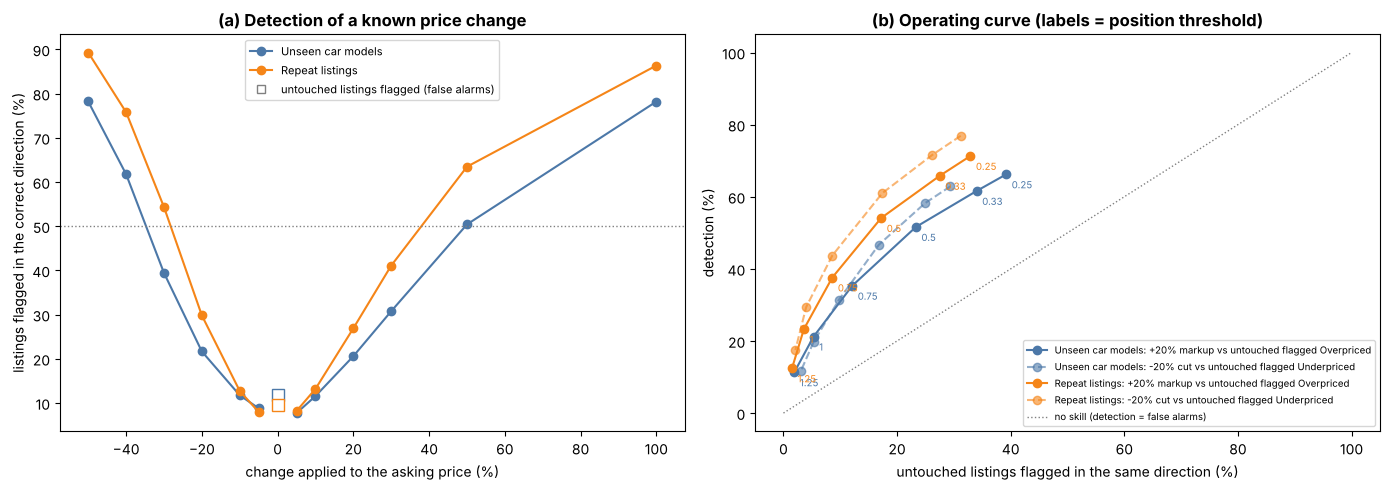

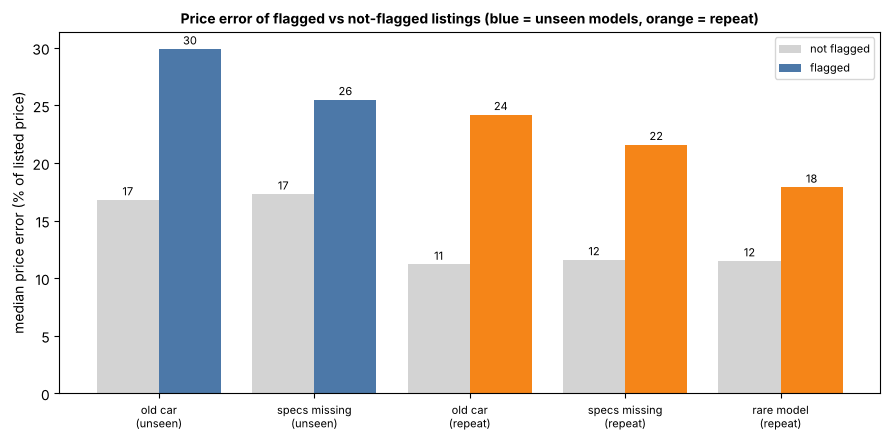

Saved: reports/figures/deal_score_detection.png and reports/figures/confidence_flag_error.png


In [60]:
# Cell 59: figures -- (a) detection against price change, (b) operating curve, (c) error of flagged vs unflagged listings
COL = {"Unseen car models": "#4C78A8", "Repeat listings": "#F58518"}              # same colours as Sections 9-10
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
for name in REG:
    t = det[name]["all"]
    mult = np.array([float(i[1:]) for i in t.index])
    ax[0].plot((mult[mult < 1] - 1) * 100, t.values[mult < 1], "o-", color=COL[name], label=name)
    ax[0].plot((mult[mult > 1] - 1) * 100, t.values[mult > 1], "o-", color=COL[name])
    ax[0].plot([0], [fa[name].loc["all", "flagged either way %"]], "s", color=COL[name], mfc="white", ms=9)
ax[0].plot([], [], "s", color="grey", mfc="white", label="untouched listings flagged (false alarms)")
ax[0].axhline(50, color="grey", ls=":", lw=1)
ax[0].set_xlabel("change applied to the asking price (%)"); ax[0].set_ylabel("listings flagged in the correct direction (%)")
ax[0].set_title("(a) Detection of a known price change", fontweight="bold"); ax[0].legend(fontsize=8, loc="upper center")
for name in REG:
    o = oc.loc[name].iloc[:len(TAUS)]
    ax[1].plot(o["untouched flagged Overpriced %"], o["detect +20% %"], "o-", color=COL[name], label=f"{name}: +20% markup vs untouched flagged Overpriced")
    ax[1].plot(o["untouched flagged Underpriced %"], o["detect -20% %"], "o--", color=COL[name], alpha=.6, label=f"{name}: -20% cut vs untouched flagged Underpriced")
    for tau, x_, y_ in zip(TAUS, o["untouched flagged Overpriced %"], o["detect +20% %"]):
        ax[1].annotate(f"{tau:g}", (x_, y_), textcoords="offset points", xytext=(4, -10), fontsize=7, color=COL[name])
ax[1].plot([0, 100], [0, 100], color="grey", ls=":", lw=1, label="no skill (detection = false alarms)")
ax[1].set_xlabel("untouched listings flagged in the same direction (%)"); ax[1].set_ylabel("detection (%)")
ax[1].set_title("(b) Operating curve (labels = position threshold)", fontweight="bold"); ax[1].legend(fontsize=7, loc="lower right")
plt.tight_layout(); plt.savefig("../reports/figures/deal_score_detection.png", dpi=120); plt.show()

fig, ax = plt.subplots(figsize=(9, 4.5))
labels, flagged, unflagged, cols = [], [], [], []
for (reg_, comp_), row in comp_df.iterrows():
    labels.append(f"{comp_.replace('_', ' ')}\n({'unseen' if reg_.startswith('Unseen') else 'repeat'})")
    flagged.append(row["median error flagged %"]); unflagged.append(row["median error unflagged %"]); cols.append(COL[reg_])
x_ = np.arange(len(labels))
ax.bar(x_ - 0.2, unflagged, 0.4, color="lightgrey", label="not flagged")
ax.bar(x_ + 0.2, flagged, 0.4, color=cols, label="flagged")
for i, (u_, f_) in enumerate(zip(unflagged, flagged)):
    ax.text(i - 0.2, u_ + 0.4, f"{u_:.0f}", ha="center", fontsize=8); ax.text(i + 0.2, f_ + 0.4, f"{f_:.0f}", ha="center", fontsize=8)
ax.set_xticks(x_); ax.set_xticklabels(labels, fontsize=8); ax.set_ylabel("median price error (% of listed price)")
ax.set_title("Price error of flagged vs not-flagged listings (blue = unseen models, orange = repeat)", fontweight="bold", fontsize=10); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig("../reports/figures/confidence_flag_error.png", dpi=120); plt.show()
print("Saved: reports/figures/deal_score_detection.png and reports/figures/confidence_flag_error.png")

In [61]:
# Cell 60: decisions for the log, and the table for the README (all text generated from the numbers above)
D = det; U, Rp = "Unseen car models", "Repeat listings"
mU = mind[U].loc["all"]; mR = mind[Rp].loc["all"]
o_ = oc.xs(Rp, level="regime"); u_ = oc.xs(U, level="regime")
decisions = [
 f"- D40: Deal Score validation (Section 12) uses only out-of-fold development predictions of the point model and of {winner_name} intervals in both regimes (unseen car models, grouped CV; repeat listings, twin groups together); the saved all-data models are never used to score development rows. Reproduction check: coverage {check.loc['interval coverage %', U]}% / {check.loc['interval coverage %', Rp]}% and median width {check.loc['median width, % of price', U]}% / {check.loc['median width, % of price', Rp]}% (unseen / repeat). The validation labelling functions agree with src/deal_score.py on {parity_n} sampled calls. Rules were fixed in 12.1 before any result; the operating curve in 12.5 was added afterwards and changes no rule. The locked test set and all saved models are untouched.",
 f"- D41: injection test. A +20% markup is flagged Overpriced for {D[U].loc['x1.20', 'all']:.1f}% (unseen) and {D[Rp].loc['x1.20', 'all']:.1f}% (repeat) of listings, +30% for {D[U].loc['x1.30', 'all']:.1f}% and {D[Rp].loc['x1.30', 'all']:.1f}%, +50% for {D[U].loc['x1.50', 'all']:.1f}% and {D[Rp].loc['x1.50', 'all']:.1f}%; a -20% cut is flagged Underpriced for {D[U].loc['x0.80', 'all']:.1f}% and {D[Rp].loc['x0.80', 'all']:.1f}%, -30% for {D[U].loc['x0.70', 'all']:.1f}% and {D[Rp].loc['x0.70', 'all']:.1f}%. Untouched listings are flagged either way {fa[U].loc['all', 'flagged either way %']:.1f}% (unseen) and {fa[Rp].loc['all', 'flagged either way %']:.1f}% (repeat), an upper bound on false alarms. Smallest tested change detected at least half the time (cut / markup): unseen {mU['cut >= 50%']} / {mU['rise >= 50%']}, repeat {mR['cut >= 50%']} / {mR['rise >= 50%']}; at least 80%: unseen {mU['cut >= 80%']} / {mU['rise >= 80%']}, repeat {mR['cut >= 80%']} / {mR['rise >= 80%']}. The Deal Score therefore detects large price gaps only. The median spread between listings of the same car is {tw_spread.median():.1f}% (Section 8), so part of the range width may be asking-price noise; not tested.",
 f"- D42: confidence flag components, rule from 12.1. Kept: {', '.join(ADOPTED) if ADOPTED else 'none'}{'; dropped: ' + ', '.join(dropped) if dropped else ''}. Median-error ratios flagged / unflagged: " + "; ".join(f"{reg_} {comp_} {row['ratio']:.2f} (95% interval {row['95% CI low']:.2f} to {row['95% CI high']:.2f}, flagged {row['flagged share %']:.1f}%)" for (reg_, comp_), row in comp_df.iterrows()) + f". Margin check: {('the adoption of ' + ', '.join(f'{c} ({r})' for r, c in within_noise) + ' passes the rule but its bootstrap interval reaches below 1.3, so it is within sampling error') if within_noise else 'no adoption decision hinged on a margin inside sampling error'}. Rare model is evaluated in the repeat regime only because it is true for every listing of the unseen regime by construction. Error by model familiarity (repeat regime): known {status.iloc[0]['median error %']}%, rare {status.iloc[1]['median error %']}%, unknown {status.iloc[2]['median error %']}%; unseen regime {status.iloc[3]['median error %']}%. Interval coverage in the repeat regime falls from {status.iloc[0]['interval coverage %']}% (known model) to {status.iloc[1]['interval coverage %']}% (rare, n={int(status.iloc[1]['n'])}) and {status.iloc[2]['interval coverage %']}% (unknown, n={int(status.iloc[2]['n'])}).",
 f"- D43: effect of the flag on the Deal Score. Combined flag marks {cU['flagged share %']:.1f}% (unseen) and {cR['flagged share %']:.1f}% (repeat) of listings, with median error {fU.loc['flagged (low confidence)', 'median error %']:.1f}% vs {fU.loc['unflagged', 'median error %']:.1f}% and {fR.loc['flagged (low confidence)', 'median error %']:.1f}% vs {fR.loc['unflagged', 'median error %']:.1f}%. Untouched listings flagged either way: flagged {fU.loc['flagged (low confidence)', 'untouched flagged either way %']:.1f}% vs unflagged {fU.loc['unflagged', 'untouched flagged either way %']:.1f}% (unseen), {fR.loc['flagged (low confidence)', 'untouched flagged either way %']:.1f}% vs {fR.loc['unflagged', 'untouched flagged either way %']:.1f}% (repeat); detection of +20%: {fU.loc['flagged (low confidence)', 'detect +20% %']:.1f}% vs {fU.loc['unflagged', 'detect +20% %']:.1f}% (unseen), {fR.loc['flagged (low confidence)', 'detect +20% %']:.1f}% vs {fR.loc['unflagged', 'detect +20% %']:.1f}% (repeat). Criterion (a) {'passed' if cU['(a) ratio >= 1.3'] and cR['(a) ratio >= 1.3'] else 'failed in a regime'}, criterion (b) {'passed' if cU['(b) unflagged <= all'] and cR['(b) unflagged <= all'] else 'failed in a regime'}. Design decision from the rule fixed in 12.1: {'suppress labels on flagged listings' if SUPPRESS else 'keep the Under/Over label and show a low-confidence notice with the reasons'}. Thresholds live in src/deal_validation.py (rare model < {dv.RARE_MODEL_MIN_LISTINGS} listings, old car >= {dv.OLD_CAR_AGE} years, specs missing) and deal_score() returns low_confidence and confidence_reasons.",
 f"- D44: exploratory operating curve (added after the injection results, no rule changed; false alarms counted in the same direction as the detection). At the interval rule, untouched listings are flagged Overpriced {fa[U].loc['all', 'flagged Overpriced %']:.1f}% / {fa[Rp].loc['all', 'flagged Overpriced %']:.1f}% and a +20% markup is detected {D[U].loc['x1.20', 'all']:.1f}% / {D[Rp].loc['x1.20', 'all']:.1f}% (unseen / repeat). Lowering the position threshold to 0.50 raises detection of +20% to {u_.loc[0.5, 'detect +20% %']:.1f}% / {o_.loc[0.5, 'detect +20% %']:.1f}% but flags {u_.loc[0.5, 'untouched flagged Overpriced %']:.1f}% / {o_.loc[0.5, 'untouched flagged Overpriced %']:.1f}% of untouched listings as Overpriced ({u_.loc[0.5, 'untouched flagged either way %']:.1f}% / {o_.loc[0.5, 'untouched flagged either way %']:.1f}% either way). The cut-offs of src/deal_score.py are kept.",
 f"- D45: open point for Step 12. The repeat-regime intervals above are calibrated on random (twin-grouped) calibration rows, but the shipped artifact models/c_adaptive_cqr_model.joblib is calibrated on held-out car models (Section 6c, Cell 33), so for a listing of a well-known car model the app behaves more like the unseen-models column (median width {wid[U]:.0f}% of price) than the repeat column ({wid[Rp]:.0f}%). Calibrated on repeat listings the intervals cover only {status.iloc[1]['interval coverage %']}% of rare-model and {status.iloc[2]['interval coverage %']}% of unknown-model listings (n={int(status.iloc[1]['n'])} and {int(status.iloc[2]['n'])}); a possible reason is that such models behave like unseen ones, not tested. Step 12 should decide whether to calibrate known and rare/unknown models separately, then re-run Section 12: src/deal_validation.py works on out-of-fold arrays, so the same cells apply to the new point model and intervals. The demo app (Step 14) needs dev.model_key.value_counts() and the entered car model to raise the rare/unknown-model warning.",
]
print("Decision log entries (appended to docs/decision_log.md):")
for line in decisions: print(line)

readme_table = "\n".join([
 "| Deal Score check (development, out-of-fold) | Unseen car models | Repeat listings |", "|---|---|---|",
 f"| Untouched listings flagged either way (false-alarm upper bound) | {fa[U].loc['all', 'flagged either way %']:.1f}% | {fa[Rp].loc['all', 'flagged either way %']:.1f}% |",
 *[f"| Detected after a {lab} price change | {D[U].loc[k, 'all']:.0f}% | {D[Rp].loc[k, 'all']:.0f}% |" for lab, k in
   [("-30%", "x0.70"), ("-20%", "x0.80"), ("-10%", "x0.90"), ("+10%", "x1.10"), ("+20%", "x1.20"), ("+30%", "x1.30")]],
 f"| Median price error, low-confidence vs other listings | {fU.loc['flagged (low confidence)', 'median error %']:.1f}% vs {fU.loc['unflagged', 'median error %']:.1f}% | {fR.loc['flagged (low confidence)', 'median error %']:.1f}% vs {fR.loc['unflagged', 'median error %']:.1f}% |"])
print("\nREADME table:\n" + readme_table)
display(Markdown(readme_table))

Decision log entries (appended to docs/decision_log.md):
- D40: Deal Score validation (Section 12) uses only out-of-fold development predictions of the point model and of C_Adaptive_CQR intervals in both regimes (unseen car models, grouped CV; repeat listings, twin groups together); the saved all-data models are never used to score development rows. Reproduction check: coverage 88.17% / 90.45% and median width 85.7% / 65.2% (unseen / repeat). The validation labelling functions agree with src/deal_score.py on 450 sampled calls. Rules were fixed in 12.1 before any result; the operating curve in 12.5 was added afterwards and changes no rule. The locked test set and all saved models are untouched.
- D41: injection test. A +20% markup is flagged Overpriced for 20.6% (unseen) and 26.9% (repeat) of listings, +30% for 30.8% and 41.1%, +50% for 50.4% and 63.5%; a -20% cut is flagged Underpriced for 21.6% and 29.8%, -30% for 39.4% and 54.3%. Untouched listings are flagged either way 11.8% (unsee

| Deal Score check (development, out-of-fold) | Unseen car models | Repeat listings |
|---|---|---|
| Untouched listings flagged either way (false-alarm upper bound) | 11.8% | 9.5% |
| Detected after a -30% price change | 39% | 54% |
| Detected after a -20% price change | 22% | 30% |
| Detected after a -10% price change | 12% | 13% |
| Detected after a +10% price change | 12% | 13% |
| Detected after a +20% price change | 21% | 27% |
| Detected after a +30% price change | 31% | 41% |
| Median price error, low-confidence vs other listings | 27.6% vs 16.8% | 20.2% vs 10.8% |

In [62]:
# Cell 61: what the section means for the Deal Score (numbers computed above)
st = status
display(Markdown(f"""### 12.6 What this section means for the Deal Score

- **It is a detector of large gaps, not of small ones.** A +20% markup is flagged {D[U].loc['x1.20', 'all']:.0f}% / {D[Rp].loc['x1.20', 'all']:.0f}% of the time (unseen / repeat) and a +50% markup {D[U].loc['x1.50', 'all']:.0f}% / {D[Rp].loc['x1.50', 'all']:.0f}%. Read "Overpriced" as "clearly outside what similar listings ask", not as "10% too high".
- **There is no ground truth.** The injection test measures how the score reacts to *known* changes; it cannot say whether a flagged listing is a bargain. Condition, variant, accident history and city are not in the data, and a few listings look like data entry errors (Section 9: a 2020 VW Polo at Rs 2.6 lakh, a 2016 VW GTI at Rs 8 lakh), which the score will happily call "Underpriced".
- **False alarms are an upper bound,** because some untouched listings may really be mispriced.
- **The confidence notice is worth showing:** where it fires, the median price error is {fU.loc['flagged (low confidence)', 'median error %']:.0f}% against {fU.loc['unflagged', 'median error %']:.0f}% (unseen) and {fR.loc['flagged (low confidence)', 'median error %']:.0f}% against {fR.loc['unflagged', 'median error %']:.0f}% (repeat). It is a warning about the estimate, not a filter for false alarms.
- **Which column describes the shipped app?** The saved interval artifact is calibrated on held-out car models, so for a well-known model it is closer to the *unseen* column (wider ranges, lower detection) than to the repeat column. Calibrated on repeat listings, the intervals cover only {st.iloc[1]['interval coverage %']}% of rare-model and {st.iloc[2]['interval coverage %']}% of unknown-model listings. Step 12 must settle this before the app is built (D45).
- **Everything here describes 2020-era CarDekho listings** (Section 1) and will need re-checking after Step 12 changes the point model or the intervals."""))

### 12.6 What this section means for the Deal Score

- **It is a detector of large gaps, not of small ones.** A +20% markup is flagged 21% / 27% of the time (unseen / repeat) and a +50% markup 50% / 63%. Read "Overpriced" as "clearly outside what similar listings ask", not as "10% too high".
- **There is no ground truth.** The injection test measures how the score reacts to *known* changes; it cannot say whether a flagged listing is a bargain. Condition, variant, accident history and city are not in the data, and a few listings look like data entry errors (Section 9: a 2020 VW Polo at Rs 2.6 lakh, a 2016 VW GTI at Rs 8 lakh), which the score will happily call "Underpriced".
- **False alarms are an upper bound,** because some untouched listings may really be mispriced.
- **The confidence notice is worth showing:** where it fires, the median price error is 28% against 17% (unseen) and 20% against 11% (repeat). It is a warning about the estimate, not a filter for false alarms.
- **Which column describes the shipped app?** The saved interval artifact is calibrated on held-out car models, so for a well-known model it is closer to the *unseen* column (wider ranges, lower detection) than to the repeat column. Calibrated on repeat listings, the intervals cover only 85.9% of rare-model and 71.8% of unknown-model listings. Step 12 must settle this before the app is built (D45).
- **Everything here describes 2020-era CarDekho listings** (Section 1) and will need re-checking after Step 12 changes the point model or the intervals.

## 13. Routing by familiarity: the point model and the range
Two earlier results point the same way. Section 10 found that knowing the car model's identity helps, but only for car models the system has seen (it passed its adoption rule by 0.05 points). Section 12 (decision D45) found that the range shipped with the Deal Score is calibrated on **held-out car models**, so for a car model with many listings it is wider than it needs to be, while calibrating on random listings would under-cover rare and unknown models (85.9% and 71.8%). This section tests the obvious fix: **route each listing by how many listings of its car model the system has seen.**

- **Known car models** (10 or more training listings, the same threshold as Section 10 and the "rare model" flag): the identity point model, and a range whose calibration rows are random listings (twin groups kept together, as in Section 8).
- **All other car models, and cars the system has never seen:** exactly what ships today, the baseline point model and the range calibrated on held-out car models.

The test is on the repeat-listing folds, where listings have all degrees of familiarity (the unseen-model regime contains only unfamiliar listings, so it cannot change). Every number is out of fold. The locked test set is not used.

### 13.1 Rules fixed before looking at any result
| Item | Rule |
|---|---|
| R1 point model | the routed point model must reproduce Section 10's repeat-listing result (nothing is re-decided: D38 stands) |
| R2 adopt the routed range for known models (the adoption rule) | on known-model listings, (a) coverage of the identity + random-calibrated range between 88% and 92%, and (b) its median width at least 10% narrower than the shipped range on the same listings |
| R3 unfamiliar models keep the shipped range | on rare + unknown listings of the repeat folds, coverage of the shipped (held-out-model) range of at least 87% |
| R4 effect on the Deal Score (reported consequence) | on known models, detection of a x0.80 cut and of a x1.20 markup each rise by at least 3 points, and untouched listings flagged either way stay at 12% or less |
| If R2 fails | the shipped system is kept everywhere. R3 and R4 are reported, not adopted on |

Variants compared, all built with the same outer folds and inner calibration seeds as Sections 6 and 8: **shipped** (baseline features, held-out-model calibration); **baseline features, random calibration** (this is Section 8's range, and the cell asserts that it is reproduced exactly); **identity features, random calibration**.

In [63]:
# Cell 62: three ways to build the 90% range on the repeat-listing folds (same outer folds, same inner calibration seeds as Sections 6 and 8)
from sklearn.model_selection import GroupKFold, StratifiedGroupKFold
from sklearn.preprocessing import OneHotEncoder
K_ROUTE = 10                                                    # the same familiarity threshold as Section 10 and the 'rare model' flag of Section 12
FEATS_ID = FEATS + ["model_key"]

def make_pipe_idm(model):
    """make_pipe with the car model's identity one-hot encoded (same encoder settings as Section 10)."""
    num = Pipeline([("impute", SimpleImputer(strategy="median", add_indicator=True)), ("scale", "passthrough")])
    cols = ColumnTransformer([("num", num, NUM_M), ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT_M + ["model_key"])])
    return Pipeline([("cols", cols), ("model", model)])

lo_id, hi_id = (make_pipe_idm(clone(p.named_steps["model"])) for p in (lgb_lo, lgb_hi))
DIFF_ID = make_pipe_idm(clone(DIFF_MODEL.named_steps["model"]))
POINT_ID = make_pipe_idm(clone(candidates["LightGBM"].named_steps["model"]))               # Section 10's winner: identity one-hot, same hyper-parameters

def calibration_split(tr, grouped, seed=42):
    """Split the training rows of one outer fold into a proper-training part and a calibration part (indices into dev)."""
    if grouped:                                                  # calibration rows are whole car models the range model has not seen (Section 6, shipped)
        inner = StratifiedGroupKFold(n_splits=4, shuffle=True, random_state=seed)
        st = pd.qcut(dev.selling_price.iloc[tr], 5, labels=False)
        pi, ci = next(inner.split(dev.iloc[tr], st, groups=dev.model_key.iloc[tr]))
    else:                                                        # calibration rows are random listings, twin groups kept together (Section 8)
        inner = GroupKFold(n_splits=4, shuffle=True, random_state=seed)
        pi, ci = next(inner.split(dev.iloc[tr], groups=twin_id.iloc[tr]))
    return tr[pi], tr[ci]

def ranges_on_repeat_folds(identity, grouped):
    """Out-of-fold lower and upper limits (log price) on the repeat-listing folds."""
    feats, lo_m, hi_m, diff_m = (FEATS_ID, lo_id, hi_id, DIFF_ID) if identity else (FEATS, lgb_lo, lgb_hi, DIFF_MODEL)
    lo, hi = np.zeros(len(dev)), np.zeros(len(dev))
    for tr, va in twin_cv.split(dev[FEATS], groups=twin_id):
        p_idx, c_idx = calibration_split(tr, grouped)
        m = LocallyAdaptiveCQR(lo_m, hi_m, diff_model=diff_m).fit(dev[feats].iloc[p_idx], dev.log_price.iloc[p_idx], dev[feats].iloc[c_idx], dev.log_price.iloc[c_idx])
        lo[va], hi[va] = m.predict(dev[feats].iloc[va])
    return lo, hi

IV = {"shipped: baseline features, calibrated on held-out car models": ranges_on_repeat_folds(identity=False, grouped=True),
      "baseline features, calibrated on random listings":              ranges_on_repeat_folds(identity=False, grouped=False),
      "identity features, calibrated on random listings":              ranges_on_repeat_folds(identity=True,  grouped=False)}
K_SHIP, K_RAND, K_ID = list(IV)
assert np.allclose(IV[K_RAND][0], twin_oof[winner_name][0]) and np.allclose(IV[K_RAND][1], twin_oof[winner_name][1]), "does not reproduce Section 8"
print("Reproduction check passed: 'baseline features, calibrated on random listings' equals the Section 8 intervals.")

point_id = np.zeros(len(dev))                                    # identity point model, out of fold (Section 10's winner)
for tr, va in twin_cv.split(dev[FEATS], groups=twin_id):
    point_id[va] = clone(POINT_ID).fit(dev[FEATS_ID].iloc[tr], dev.log_price.iloc[tr]).predict(dev[FEATS_ID].iloc[va])
print("Built: 3 range variants and the identity point model, all out of fold.")

Reproduction check passed: 'baseline features, calibrated on random listings' equals the Section 8 intervals.


Built: 3 range variants and the identity point model, all out of fold.


In [64]:
# Cell 63: coverage and width of each range variant, by how familiar the car model is (repeat-listing folds)
n_rep = REG["Repeat listings"]["n_train"]
fam_group = np.where(n_rep >= K_ROUTE, "known (10+ listings)", np.where(n_rep >= 1, "rare (1-9)", "unknown (0)"))
GROUPS = ["known (10+ listings)", "rare (1-9)", "unknown (0)"]
unfamiliar = n_rep < K_ROUTE

def wilson(k, n, z=1.96):
    p = k / n; d = 1 + z * z / n; c = p + z * z / (2 * n); h = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n))
    return 100 * (c - h) / d, 100 * (c + h) / d

rows = []
for g_ in GROUPS + ["rare + unknown (n<10)", "all"]:
    m = unfamiliar if g_.startswith("rare + unknown") else (np.ones(len(dev), bool) if g_ == "all" else fam_group == g_)
    for k_, (lo, hi) in IV.items():
        cov = (yl[m] >= lo[m]) & (yl[m] <= hi[m]); lo_ci, hi_ci = wilson(cov.sum(), m.sum())
        rows.append({"listings": g_, "n": int(m.sum()), "range": k_, "coverage %": 100 * cov.mean(), "95% CI": f"{lo_ci:.1f} to {hi_ci:.1f}",
                     "median width, % of price": np.median(100 * (np.exp(hi[m]) - np.exp(lo[m])) / dev.selling_price.values[m])})
cmp_tbl = pd.DataFrame(rows).set_index(["listings", "n", "range"]); display(cmp_tbl.round(1))

is_known = fam_group == "known (10+ listings)"
cov_of = lambda k_, m: 100 * np.mean((yl[m] >= IV[k_][0][m]) & (yl[m] <= IV[k_][1][m]))
wid_of = lambda k_, m: np.median(100 * (np.exp(IV[k_][1][m]) - np.exp(IV[k_][0][m])) / dev.selling_price.values[m])
R2a = 88 <= cov_of(K_ID, is_known) <= 92
R2b = wid_of(K_ID, is_known) <= 0.9 * wid_of(K_SHIP, is_known)
R3 = cov_of(K_SHIP, unfamiliar) >= 87
print(f"R2 known listings, identity + random calibration: coverage {cov_of(K_ID, is_known):.1f}% (must be 88-92%) -> {'PASS' if R2a else 'FAIL'};"
      f" median width {wid_of(K_ID, is_known):.1f}% vs {wid_of(K_SHIP, is_known):.1f}% shipped, {100 * (1 - wid_of(K_ID, is_known) / wid_of(K_SHIP, is_known)):.0f}% narrower (must be >= 10%) -> {'PASS' if R2b else 'FAIL'}")
print(f"R3 rare + unknown listings, shipped calibration: coverage {cov_of(K_SHIP, unfamiliar):.1f}% (must be >= 87%) -> {'PASS' if R3 else 'FAIL'}")

coverage %  \
listings              n    range                                                            
known (10+ listings)  5114 shipped: baseline features, calibrated on held-...        93.7   
                           baseline features, calibrated on random listings          90.9   
                           identity features, calibrated on random listings          90.6   
rare (1-9)            377  shipped: baseline features, calibrated on held-...        90.7   
                           baseline features, calibrated on random listings          85.9   
                           identity features, calibrated on random listings          85.1   
unknown (0)           39   shipped: baseline features, calibrated on held-...        84.6   
                           baseline features, calibrated on random listings          71.8   
                           identity features, calibrated on random listings          74.4   
rare + unknown (n<10) 416  shipped: baseline features, calibrated on held-...        90.1   
                           baseline features, calibrated on random listings          84.6   
                           identity features, calibrated on random listings          84.1   
all                   5530 shipped: baseline features, calibrated on held-...        93.4   
                           baseline features, calibrated on random listings          90.5   
                           identity features, calibrated on random listings          90.1   

                                                                                     95% CI  \
listings              n    range                                                              
known (10+ listings)  5114 shipped: baseline features, calibrated on held-...  93.0 to 94.3   
                           baseline features, calibrated on random listings    90.1 to 91.7   
                           identity features, calibrated on random listings    89.7 to 91.3   
rare (1-9)            377  shipped: baseline features, calibrated on held-...  87.4 to 93.2   
                           baseline features, calibrated on random listings    82.1 to 89.1   
                           identity features, calibrated on random listings    81.2 to 88.4   
unknown (0)           39   shipped: baseline features, calibrated on held-...  70.3 to 92.8   
                           baseline features, calibrated on random listings    56.2 to 83.5   
                           identity features, calibrated on random listings    58.9 to 85.4   
rare + unknown (n<10) 416  shipped: baseline features, calibrated on held-...  86.9 to 92.7   
                           baseline features, calibrated on random listings    80.8 to 87.8   
                           identity features, calibrated on random listings    80.3 to 87.3   
all                   5530 shipped: baseline features, calibrated on held-...  92.7 to 94.0   
                           baseline features, calibrated on random listings    89.6 to 91.2   
                           identity features, calibrated on random listings    89.3 to 90.9   

                                                                               median width, % of price  
listings              n    range                                                                         
known (10+ listings)  5114 shipped: baseline features, calibrated on held-...                      75.3  
                           baseline features, calibrated on random listings                        64.1  
                           identity features, calibrated on random listings                        62.0  
rare (1-9)            377  shipped: baseline features, calibrated on held-...                     107.3  
                           baseline features, calibrated on random listings                        87.2  
                           identity features, calibrated on random listings                        89.9  
unknown (0)           39   shippe

R2 known listings, identity + random calibration: coverage 90.6% (must be 88-92%) -> PASS; median width 62.0% vs 75.3% shipped, 18% narrower (must be >= 10%) -> PASS
R3 rare + unknown listings, shipped calibration: coverage 90.1% (must be >= 87%) -> PASS


In [65]:
# Cell 64: the two systems end to end on the repeat folds. S1 = shipped (baseline point model and held-out-model range for everything).
# S2 = routed (known car models: identity point model and random-calibrated identity range; others: S1).
pt1, (lo1, hi1) = oof_s, IV[K_SHIP]
pt2 = np.where(is_known, point_id, oof_s)
lo2, hi2 = np.where(is_known, IV[K_ID][0], IV[K_SHIP][0]), np.where(is_known, IV[K_ID][1], IV[K_SHIP][1])
unseen_reg = REG["Unseen car models"]                               # unseen car models: every listing is unfamiliar, so S2 = S1 by construction
p_listed = dev.selling_price.values

def system_row(pred, lo, hi, m):
    ape = 100 * np.abs(np.exp(pred[m]) - p_listed[m]) / p_listed[m]
    im = interval_metrics(dev.log_price.values[m], lo[m], hi[m])
    return {"n": int(m.sum()), "MedAPE %": np.median(ape), "RMSE_log": float(np.sqrt(np.mean((pred[m] - yl[m]) ** 2))), "coverage %": im["coverage_%"],
            "median width, % of price": im["med_width_%"], "interval score": im["interval_score"]}
allm = np.ones(len(dev), bool)
sys_tbl = pd.DataFrame({("S1 shipped", "all listings"): system_row(pt1, lo1, hi1, allm), ("S2 routed", "all listings"): system_row(pt2, lo2, hi2, allm),
                        ("S1 shipped", "known models"): system_row(pt1, lo1, hi1, is_known), ("S2 routed", "known models"): system_row(pt2, lo2, hi2, is_known),
                        ("S1 shipped", "rare + unknown"): system_row(pt1, lo1, hi1, unfamiliar), ("S2 routed", "rare + unknown"): system_row(pt2, lo2, hi2, unfamiliar)}).T
print("Repeat-listing folds:"); display(sys_tbl.round(3))
print("Unseen car models (S1 = S2): MedAPE %.2f, coverage %.1f%%, median width %.1f%%" % (np.median(unseen_reg["ape"]),
      100 * np.mean((yl >= unseen_reg["lo"]) & (yl <= unseen_reg["hi"])), np.median(100 * (np.exp(unseen_reg["hi"]) - np.exp(unseen_reg["lo"])) / p_listed)))

# What the change does to the Deal Score on known car models: detection of a known price change, and flags on untouched listings
MULT3 = [0.70, 0.80, 0.90, 1.10, 1.20, 1.30]
det_tbl = pd.DataFrame({"S1 shipped": [dv.detection_rate(yl, lo1, hi1, k, is_known) for k in MULT3],
                        "S2 routed": [dv.detection_rate(yl, lo2, hi2, k, is_known) for k in MULT3]}, index=[f"x{k:.2f}" for k in MULT3])
det_tbl["gain (pts)"] = det_tbl["S2 routed"] - det_tbl["S1 shipped"]
print("\nKnown car models: detection (%) of a price change by factor m"); display(det_tbl.round(1))
fa1 = 100 * np.mean(dv.three_level(yl, lo1, hi1)[is_known] != "Fair"); fa2 = 100 * np.mean(dv.three_level(yl, lo2, hi2)[is_known] != "Fair")
print(f"Known car models, untouched listings flagged either way: S1 {fa1:.1f}% | S2 {fa2:.1f}%")
R4 = bool(det_tbl.loc["x0.80", "gain (pts)"] >= 3 and det_tbl.loc["x1.20", "gain (pts)"] >= 3 and fa2 <= 12)
print(f"R4 detection of x0.80 and x1.20 each up by >= 3 points and untouched flags <= 12% -> {'PASS' if R4 else 'FAIL'}")

Repeat-listing folds:


,,n,MedAPE %,RMSE_log,coverage %,"median width, % of price",interval score
S1 shipped,all listings,5530.0,11.901,0.222,93.42,76.6,1.044
S2 routed,all listings,5530.0,11.354,0.218,90.54,64.1,0.960
S1 shipped,known models,5114.0,11.462,0.212,93.68,75.3,0.993
S2 routed,known models,5114.0,10.977,0.208,90.57,62.0,0.902
S1 shipped,rare + unknown,416.0,17.914,0.322,90.14,108.6,1.665
S2 routed,rare + unknown,416.0,17.914,0.322,90.14,108.6,1.665


Unseen car models (S1 = S2): MedAPE 17.57, coverage 88.2%, median width 85.7%

Known car models: detection (%) of a price change by factor m


,S1 shipped,S2 routed,gain (pts)
x0.70,45.3,58.8,13.5
x0.80,21.0,33.0,12.0
x0.90,8.9,13.4,4.5
x1.10,9.0,13.2,4.3
x1.20,20.0,27.8,7.8
x1.30,33.5,42.9,9.3


Known car models, untouched listings flagged either way: S1 6.3% | S2 9.4%
R4 detection of x0.80 and x1.20 each up by >= 3 points and untouched flags <= 12% -> PASS


In [66]:
# Cell 65: the decision, straight from the rules fixed above
R1_check = abs(sys_tbl.loc[("S2 routed", "all listings"), "MedAPE %"] - tables["repeat listings"].loc[f"identity one-hot, routed (k={K_ROUTE})", "MedAPE_%"])
assert R1_check < 0.01, "the routed point model does not reproduce Section 10"
print(f"R1 the identity point model reproduces Section 10 end to end, to within 0.01 points (MedAPE {sys_tbl.loc[('S2 routed', 'all listings'), 'MedAPE %']:.3f}% vs {sys_tbl.loc[('S1 shipped', 'all listings'), 'MedAPE %']:.3f}% shipped) -> PASS")
print(f"R2 -> {'PASS' if (R2a and R2b) else 'FAIL'}   R3 -> {'PASS' if R3 else 'FAIL'}   R4 -> {'PASS' if R4 else 'FAIL'}")
ADOPT_ROUTING = bool(R2a and R2b)                              # R2 is the adoption rule; R3 and R4 are reported consequences
print("Decision:", "adopt the routed system (known car models: identity model + random-calibrated range; all others unchanged)" if ADOPT_ROUTING
      else "keep the shipped system")
assert ADOPT_ROUTING, "the rest of this section saves the routed artifact; stop here if the rule fails"

R1 the identity point model reproduces Section 10 end to end, to within 0.01 points (MedAPE 11.354% vs 11.901% shipped) -> PASS
R2 -> PASS   R3 -> PASS   R4 -> PASS
Decision: adopt the routed system (known car models: identity model + random-calibrated range; all others unchanged)


In [67]:
# Cell 66: fit the known-model branch on all development rows, save it, and prove the routing works through src/deal_score.py and src/explain.py
import joblib, sklearn, lightgbm
import src.explain as xp
point_known = clone(POINT_ID).fit(dev[FEATS_ID], dev.log_price)
p_idx, c_idx = next(GroupKFold(n_splits=4, shuffle=True, random_state=42).split(dev, groups=twin_id))      # calibration rows: random listings, twin groups together
interval_known = LocallyAdaptiveCQR(lo_id, hi_id, diff_model=DIFF_ID).fit(dev[FEATS_ID].iloc[p_idx], dev.log_price.iloc[p_idx],
                                                                         dev[FEATS_ID].iloc[c_idx], dev.log_price.iloc[c_idx])
model_counts = dev.model_key.value_counts().to_dict()
joblib.dump({"point_model": point_known, "interval_model": interval_known, "features": FEATS_ID, "model_counts": model_counts, "k_route": K_ROUTE,
             "trained_on": f"development set, {len(dev)} rows (range calibrated on {len(c_idx)} random listings)",
             "versions": {"scikit-learn": sklearn.__version__, "lightgbm": lightgbm.__version__}}, "../models/known_model_routed.joblib")
print(f"Saved: models/known_model_routed.joblib ({sum(v >= K_ROUTE for v in model_counts.values())} of {len(model_counts)} car models take the known-model route)")

importlib.reload(ds); ds._point_artifact = ds._interval_artifact = ds._routed_artifact = None            # force a fresh load from disk
cnt = dev.model_key.map(dev.model_key.value_counts())
cases = {"known car model": dev[cnt >= 100].sample(1, random_state=1).iloc[0],
         "rare car model": dev[(cnt >= 1) & (cnt < K_ROUTE)].sample(1, random_state=1).iloc[0],
         "car model never seen": dev.sample(1, random_state=1).iloc[0].copy()}
cases["car model never seen"]["model_key"] = "Bugatti Veyron"
rows = []
for label, r in cases.items():
    out = ds.deal_score(r, r.selling_price, model_key=r.model_key)
    ex = xp.explain_listing(r, model_key=r.model_key)
    assert abs(ex["predicted_price"] - out["predicted_price"]) < 0.01 and ex["route"] == out["route"]      # explanation and score use the same fair price
    rows.append({"case": label, "car model": r.model_key, "route": out["route"], "fair price": int(out["predicted_price"]), "lower": int(out["lower_bound"]),
                 "upper": int(out["upper_bound"]), "largest driver": f"{ex['drivers'].driver[0]} ({ex['drivers'].effect_pct[0]:+.0f}%)",
                 "confidence notes": "; ".join(out["confidence_reasons"]) or "none"})
assert [r["route"] for r in rows] == ["known-model", "general", "general"]
display(pd.DataFrame(rows).set_index("case"))
print("These are development listings the models were trained on, so this is a wiring check, not a performance claim.")

Saved: models/known_model_routed.joblib (82 of 176 car models take the known-model route)


,car model,route,fair price,lower,upper,largest driver,confidence notes
case,,,,,,,
known car model,Maruti Ertiga,known-model,755823,593530,858895,Age (+40%),none
rare car model,Fiat Palio,general,124218,60257,319376,Age (-57%),rare car model (fewer than 10 listings in the ...
car model never seen,Bugatti Veyron,general,378699,253819,577048,Age (-15%),car model not in the development data


These are development listings the models were trained on, so this is a wiring check, not a performance claim.


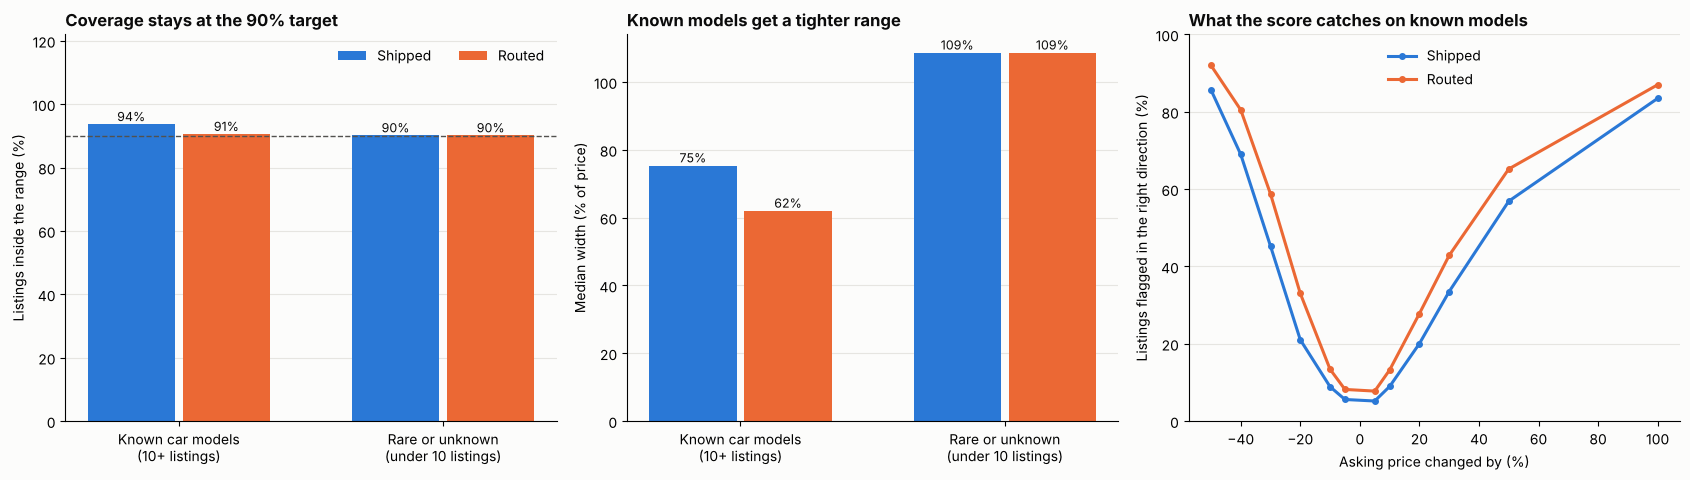

Saved: reports/figures/routed_system.png


In [68]:
# Cell 67: figure (blue = shipped, orange = routed)
BLUE, ORANGE, INK, MUTED, SURFACE = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e", "#fcfcfb"
fig, ax = plt.subplots(1, 3, figsize=(17, 4.9), facecolor=SURFACE)
for a in ax:
    a.set_facecolor(SURFACE)
    for side in ("top", "right"): a.spines[side].set_visible(False)
    a.grid(axis="y", color="#e6e5e1", linewidth=0.8); a.set_axisbelow(True)
seg = {"Known car models\n(10+ listings)": is_known, "Rare or unknown\n(under 10 listings)": unfamiliar}
x, w = np.arange(2), 0.36
for panel, (title, fn, ylabel) in enumerate([("Coverage stays at the 90% target", lambda lo, hi, m: 100 * np.mean((yl[m] >= lo[m]) & (yl[m] <= hi[m])), "Listings inside the range (%)"),
                                            ("Known models get a tighter range", lambda lo, hi, m: np.median(100 * (np.exp(hi[m]) - np.exp(lo[m])) / p_listed[m]), "Median width (% of price)")]):
    for xs, (lo, hi), col, lab in ((x - w / 2, (lo1, hi1), BLUE, "Shipped"), (x + w / 2, (lo2, hi2), ORANGE, "Routed")):
        vals = [fn(lo, hi, m) for m in seg.values()]
        bars = ax[panel].bar(xs, vals, w - 0.03, color=col, label=lab)
        for b_, v in zip(bars, vals): ax[panel].text(b_.get_x() + b_.get_width() / 2, v + 1, f"{v:.0f}%", ha="center", fontsize=9, color=INK)
    ax[panel].set_xticks(x); ax[panel].set_xticklabels(list(seg)); ax[panel].set_ylabel(ylabel); ax[panel].set_title(title, loc="left", fontweight="bold", color=INK)
ax[0].axhline(90, color=MUTED, linewidth=1, linestyle="--"); ax[0].set_ylim(0, 122); ax[0].legend(frameon=False, loc="upper right", ncol=2)
grid_m = [0.5, 0.6, 0.7, 0.8, 0.9, 0.95, 1.05, 1.1, 1.2, 1.3, 1.5, 2.0]
for (lo, hi), col, lab in (((lo1, hi1), BLUE, "Shipped"), ((lo2, hi2), ORANGE, "Routed")):
    ax[2].plot([100 * (k - 1) for k in grid_m], [dv.detection_rate(yl, lo, hi, k, is_known) for k in grid_m], color=col, linewidth=2.2, marker="o", markersize=4, label=lab)
ax[2].set_xlabel("Asking price changed by (%)"); ax[2].set_ylabel("Listings flagged in the right direction (%)"); ax[2].set_ylim(0, 100); ax[2].legend(frameon=False, loc="upper center")
ax[2].set_title("What the score catches on known models", loc="left", fontweight="bold", color=INK)
plt.tight_layout(); plt.savefig("../reports/figures/routed_system.png", dpi=120, facecolor=SURFACE); plt.show()
print("Saved: reports/figures/routed_system.png")

**Findings**
- **The shipped range is too wide for known car models and just right for the others, and the reverse is true of random calibration.** On known models the shipped range covers 93.7% of listings against a 90% target at a median width of 75% of the price; calibrated on random listings with identity features it covers 90.6% (95% interval 89.7 to 91.3) at 62%, which is **18% narrower**. On rare and unknown models the shipped range covers 90.1% (86.9 to 92.7) while random calibration would cover only 84.6%. That confirms the D45 suspicion that unfamiliar models behave like unseen ones. Most of the narrowing comes from the calibration change (75% to 64%); the identity features trim a little more (to 62%).
- **All four rules pass.** R1: the routed point model reproduces Section 10 (11.35% against 11.90%). R2: coverage 90.6%, 18% narrower. R3: 90.1% (the lower end of its 95% interval, 86.9%, is just below the 87% line, so read this as "close to target", not "proven"). R4: see below. Routing is adopted.
- **The whole repeat-listing picture improves.** Median error 11.90% to 11.35%, RMSE_log 0.222 to 0.218, coverage 93.4% to 90.5% (closer to the target), median width 76.6% to 64.1% of the price, interval score 1.044 to 0.960 (lower is better). Rare and unknown models and the unseen-model regime are unchanged by construction (17.6% median error, 88.2% coverage, 85.7% width for unseen models).
- **On known models the Deal Score catches more.** Detection of a 20% markup rises from 20.0% to 27.8%, a 20% cut from 21.0% to 33.0%, a 30% markup from 33.5% to 42.9%, a 30% cut from 45.3% to 58.8%. The price of that is more flags on untouched listings (6.3% to 9.4% flagged either way). That is expected: a range that really covers 90% must flag about 10%, and the shipped range was flagging fewer only because it was over-wide. As in Section 12, the untouched rate is an upper bound on false alarms, because some real listings are mispriced.
- **Limits.** The "never seen" group is only 39 listings in this regime (coverage 84.6%, interval 70 to 93), too few to prove anything on its own; the unseen-model regime (5,530 rows, 88.2%) is the sturdier evidence for that branch. Even for known models the range is still about 62% of the price, which fits the 11.6% price spread between listings of the very same car (Section 8) but was not tested here. The routing threshold (10) was not tuned: it is the one fixed in Section 10.
- **What changed in the code.** `models/known_model_routed.joblib` holds the identity point model, its range and the listing counts per car model. `deal_score(..., model_key=...)` and `explain_listing(..., model_key=...)` take the same route, so the fair price, the range, the SHAP drivers and the confidence notes always refer to the same model. Without a `model_key`, or without this artifact, everything takes the general route and behaves exactly as before.

## 14. The final test
Everything so far was scored on development data. This section scores the finished system once on the **locked test set**: 1,392 listings of 20% of the car models, set aside in Section 1 (decision D13) and touched since only to split the data and to assert that no car model is shared with development.

**Procedure.** The rules below, and the code that applies them (Cells 68 and 69), were committed to git *before* the test was run. The test is run once, on the shipped artifacts exactly as saved (the final point model, the shipped range model, and the known-model artifact). Nothing is tuned, re-fitted or re-chosen afterwards; a criterion that fails is reported as failed and is not repaired on the test set; and the models are not changed after the test.

**What this test can and cannot say.** The split is by car model, so every test car model is one the system has never seen and every test listing takes the *general* route (Section 13). The test therefore measures the stress-test regime, which is what a new car model will experience, and it **cannot** measure the known-model route, whose evidence stays development cross-validation (Section 13). Cell 68 asserts that all test listings take the general route.

### 14.1 Criteria fixed before the test was run
Thresholds come from development results and the fold-to-fold noise measured there, not from anything on the test set. "Development CV" means grouped cross-validation on unseen car models (Sections 5 and 6).

| Id | Criterion | Why this threshold |
|---|---|---|
| **T1a** (primary) | test median error (MedAPE) is at most the development CV mean plus 2 fold standard deviations | a different set of car models should not look worse than ordinary fold-to-fold variation |
| **T1b** (primary) | test RMSE_log is at most the development CV mean plus 2 fold standard deviations | same, on the squared-error scale |
| **T1c** (primary) | the model beats both baselines of Section 4 that use real features (B1 median by age, B2 linear on age and log km) on test MedAPE and RMSE_log, both fitted on development only | the model must earn its complexity |
| **T2a** (primary) | test range coverage is between 85% and 93% | the range is built for 90%; development gave 88.2% |
| **T2b** (primary) | test median range width is within +/-20% of the development width | a range that is honest only because it is huge is not useful |
| **T3a, T3b** | detection of a x1.20 markup and of a x0.80 cut on test is within 5 points of the development figure (Section 12) | the Deal Score's sensitivity should carry over |
| **T3c** | untouched test listings flagged either way: at most 15% | development gave 11.8% |
| **T4a, T4b, T4c** | median-error ratio flagged / unflagged is at least 1.3 for the old-car flag, the specs-missing flag and either flag (the Section 12 adoption rule); a flag with fewer than 30 test listings is reported "not evaluable" | the confidence notice must point at worse estimates on new data |
| **T5** | the ranking of price drivers by mean absolute SHAP on test matches development: Spearman at least 0.8 | the explanations should not describe a different model on new data |

**Primary result:** T1 and T2 all pass. **Secondary:** T3 to T5. Both are reported in full whatever the outcome.

In [ ]:
# Cell 68: THE FINAL TEST. It is run once, on the shipped artifacts exactly as saved. Everything is computed first and printed at the end.
# Nothing in this notebook is tuned, re-fitted or re-chosen after seeing these numbers (rules in 14.1).
TEST_FRAME = test
ds._point_artifact = ds._interval_artifact = ds._routed_artifact = None; ds._load_artifacts()           # load the artifacts from disk, as the demo will

# guards: this really is the sealed set, and it contains only car models the system has never seen
assert len(TEST_FRAME) == len(test) and not (set(TEST_FRAME.model_key) & set(dev.model_key)), "test set shares car models with development"

# 1. score every test listing through the production function (the listed price is the real asking price)
ft_out = pd.DataFrame([ds.deal_score(r, r.selling_price, model_key=r.model_key) for _, r in TEST_FRAME.iterrows()])
assert (ft_out.route == "general").all(), "unexpected known-model route on test: a test car model appears in the development counts"
ft_y = TEST_FRAME.log_price.values
ft_pred, ft_lo, ft_hi = np.log(ft_out.predicted_price.values), np.log(ft_out.lower_bound.values), np.log(ft_out.upper_bound.values)
ft_price = TEST_FRAME.selling_price.values
ft_ape = 100 * np.abs(ft_out.predicted_price.values - ft_price) / ft_price
ft_im = interval_metrics(ft_y, ft_lo, ft_hi)
ft_pt = score(ft_y, ft_pred)

# 2. development references (grouped CV, unseen car models) and the fixed baselines of Section 4, all fitted on development rows only
ft_dev_mean, ft_dev_sd, _ = cv_eval(candidates["LightGBM"], dev, FEATS, cv_group)
ft_dev = REG["Unseen car models"]; ft_dev_im = interval_metrics(yl, ft_dev["lo"], ft_dev["hi"])
ft_base = {}
for name, (m, feats) in baselines.items():
    ft_base[name] = score(ft_y, clone(m).fit(dev[feats], dev.log_price).predict(TEST_FRAME[feats]))

# 3. the five criteria of 14.1
checks = []
checks.append(("T1a", "test MedAPE <= development CV mean + 2 fold SDs", ft_pt["MedAPE_%"], ft_dev_mean["MedAPE_%"] + 2 * ft_dev_sd["MedAPE_%"], ft_pt["MedAPE_%"] <= ft_dev_mean["MedAPE_%"] + 2 * ft_dev_sd["MedAPE_%"]))
checks.append(("T1b", "test RMSE_log <= development CV mean + 2 fold SDs", ft_pt["RMSE_log"], ft_dev_mean["RMSE_log"] + 2 * ft_dev_sd["RMSE_log"], ft_pt["RMSE_log"] <= ft_dev_mean["RMSE_log"] + 2 * ft_dev_sd["RMSE_log"]))
b1b2 = [ft_base["B1 median by age"], ft_base["B2 linear: age + log km"]]
checks.append(("T1c", "beats B1 and B2 on MedAPE and RMSE_log (best baseline MedAPE shown)", ft_pt["MedAPE_%"], min(b["MedAPE_%"] for b in b1b2),
               all(ft_pt["MedAPE_%"] < b["MedAPE_%"] and ft_pt["RMSE_log"] < b["RMSE_log"] for b in b1b2)))
checks.append(("T2a", "test range coverage between 85% and 93%", ft_im["coverage_%"], "85 to 93", 85 <= ft_im["coverage_%"] <= 93))
checks.append(("T2b", "test median width within +/-20% of the development width", ft_im["med_width_%"], f"{0.8 * ft_dev_im['med_width_%']:.1f} to {1.2 * ft_dev_im['med_width_%']:.1f}",
               0.8 * ft_dev_im["med_width_%"] <= ft_im["med_width_%"] <= 1.2 * ft_dev_im["med_width_%"]))
for m_, name in ((1.2, "x1.20 markup"), (0.8, "x0.80 cut")):
    t_, d_ = dv.detection_rate(ft_y, ft_lo, ft_hi, m_), dv.detection_rate(yl, ft_dev["lo"], ft_dev["hi"], m_)
    checks.append(("T3" + ("a" if m_ > 1 else "b"), f"detection of a {name} within 5 points of development ({d_:.1f}%)", t_, f"{d_ - 5:.1f} to {d_ + 5:.1f}", abs(t_ - d_) <= 5))
ft_fa = 100 * np.mean(dv.three_level(ft_y, ft_lo, ft_hi) != "Fair")
checks.append(("T3c", "untouched test listings flagged either way <= 15%", ft_fa, "<= 15", ft_fa <= 15))
ft_old, ft_spec = TEST_FRAME.age.values >= dv.OLD_CAR_AGE, TEST_FRAME.specs_missing.values.astype(bool)
flag_tbl = pd.DataFrame({"old car (13+ yrs)": dv.error_by_flag(ft_ape, ft_old), "specs missing": dv.error_by_flag(ft_ape, ft_spec),
                         "either": dv.error_by_flag(ft_ape, ft_old | ft_spec)}).T
for cid, name, row in (("T4a", "old car", flag_tbl.loc["old car (13+ yrs)"]), ("T4b", "specs missing", flag_tbl.loc["specs missing"]), ("T4c", "either flag", flag_tbl.loc["either"])):
    if row["n flagged"] < 30:
        checks.append((cid, f"error ratio of '{name}' >= 1.3 (needs 30+ flagged listings)", f"n = {row['n flagged']}", ">= 1.3", "not evaluable"))
    else:
        checks.append((cid, f"error ratio of '{name}' >= 1.3", row["ratio"], ">= 1.3", bool(row["ratio"] >= 1.3)))
from scipy.stats import spearmanr
ft_model = ds._point_artifact["model"]
ft_c_test, _ = xp.driver_contributions(ft_model, TEST_FRAME, FEATS); ft_c_dev, _ = xp.driver_contributions(ft_model, dev, FEATS)
ft_rho = spearmanr(ft_c_test.abs().mean(), ft_c_dev.abs().mean())[0]
checks.append(("T5", "driver ranking (mean |SHAP|) on test vs development: Spearman >= 0.8", ft_rho, ">= 0.8", bool(ft_rho >= 0.8)))

# 4. extra context (descriptive, no criterion)
ft_cov_in = (ft_y >= ft_lo) & (ft_y <= ft_hi)
ft_age = pd.cut(TEST_FRAME.age, [-1, 3, 7, 12, 40], labels=["0-3 yrs", "4-7 yrs", "8-12 yrs", "13+ yrs"]).astype(str).values
by_age = pd.DataFrame({a: {"test n": int((ft_age == a).sum()), "test MedAPE %": np.median(ft_ape[ft_age == a]), "dev CV MedAPE %": np.median(ft_dev["ape"][AGE_B == a]),
                           "test coverage %": 100 * ft_cov_in[ft_age == a].mean()} for a in ["0-3 yrs", "4-7 yrs", "8-12 yrs", "13+ yrs"]}).T
ft_t = pd.DataFrame({"model_key": TEST_FRAME.model_key.values, "pe": 100 * (ft_out.predicted_price.values - ft_price) / ft_price})
worst = ft_t.groupby("model_key").pe.agg(["size", "median"]).query("size >= 8").assign(a=lambda d: d["median"].abs()).sort_values("a", ascending=False).head(6)[["size", "median"]]
report = pd.DataFrame({"development CV (unseen models)": {"MedAPE %": ft_dev_mean["MedAPE_%"], "RMSE_log": ft_dev_mean["RMSE_log"], "R2_log": ft_dev_mean["R2_log"],
                                                         "range coverage %": ft_dev_im["coverage_%"], "median width, % of price": ft_dev_im["med_width_%"]},
                       "final test": {"MedAPE %": ft_pt["MedAPE_%"], "RMSE_log": ft_pt["RMSE_log"], "R2_log": ft_pt["R2_log"],
                                      "range coverage %": ft_im["coverage_%"], "median width, % of price": ft_im["med_width_%"]}})
ft_extra = {"listings off by >30%": 100 * np.mean(ft_ape > 30), "false bargains (fair price >= 30% above listing)": 100 * np.mean(ft_out.predicted_price.values / ft_price - 1 >= 0.30),
            "MAE, INR": float(np.mean(np.abs(ft_out.predicted_price.values - ft_price))), "test listings": len(TEST_FRAME), "test car models": TEST_FRAME.model_key.nunique()}

# 5. print
print(f"FINAL TEST on {len(TEST_FRAME)} listings of {TEST_FRAME.model_key.nunique()} car models never seen in development (shipped artifacts, route: general for all)\n")
display(report.round(3))
print("Baselines on the same test listings (fitted on development only):"); display(pd.DataFrame(ft_base).T.round(3))
crit = pd.DataFrame(checks, columns=["id", "criterion", "test value", "threshold", "result"]).set_index("id")
crit["result"] = crit["result"].map(lambda v: "PASS" if v is True else ("FAIL" if v is False else v))
crit["test value"] = crit["test value"].map(lambda v: round(v, 2) if isinstance(v, (float, np.floating)) else v)
display(crit)
print("PRIMARY (T1 and T2):", "PASS" if all(crit.loc[crit.index.str.startswith(("T1", "T2")), "result"] == "PASS") else "FAIL",
      "| SECONDARY (T3 to T5):", "all pass" if all(crit.loc[crit.index.str.startswith(("T3", "T4", "T5")), "result"].isin(["PASS", "not evaluable"])) else "at least one FAIL")
print("\nConfidence flags on the test listings:"); display(flag_tbl)
print("Error and coverage by age:"); display(by_age.round(1))
print("Car models with 8+ test listings and the largest median signed error (% fair price vs listing):"); display(worst.round(0))
print({k: round(v, 1) if isinstance(v, float) else v for k, v in ft_extra.items()})

In [ ]:
# Cell 69: figure (blue = development CV on unseen car models, orange = final test)
BLUE, ORANGE, INK, MUTED, SURFACE = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e", "#fcfcfb"
fig, ax = plt.subplots(1, 3, figsize=(17, 4.9), facecolor=SURFACE)
for a in ax:
    a.set_facecolor(SURFACE)
    for side in ("top", "right"): a.spines[side].set_visible(False)
    a.grid(axis="y", color="#e6e5e1", linewidth=0.8); a.set_axisbelow(True)
# (a) predicted vs listed on the test listings
lo_, hi_ = 3e4, 1.2e7
ax[0].scatter(ft_price, ft_out.predicted_price, s=6, alpha=0.3, color=ORANGE, linewidths=0)
xx = np.array([lo_, hi_]); ax[0].plot(xx, xx, color=INK, linewidth=1.2); ax[0].plot(xx, xx * 1.3, color=MUTED, linewidth=1, linestyle="--"); ax[0].plot(xx, xx / 1.3, color=MUTED, linewidth=1, linestyle="--")
ax[0].set_xscale("log"); ax[0].set_yscale("log"); ax[0].set_xlim(lo_, hi_); ax[0].set_ylim(lo_, hi_)
ticks = [5e4, 1e5, 3e5, 1e6, 3e6, 1e7]; labs = ["0.5L", "1L", "3L", "10L", "30L", "100L"]
ax[0].set_xticks(ticks); ax[0].set_xticklabels(labs); ax[0].set_yticks(ticks); ax[0].set_yticklabels(labs); ax[0].minorticks_off(); ax[0].grid(axis="x", color="#e6e5e1", linewidth=0.8)
ax[0].set_xlabel("Listed price (lakh INR)"); ax[0].set_ylabel("Predicted fair price (lakh INR)"); ax[0].set_title("Final test: predicted vs listed (dashed: +/-30%)", loc="left", fontweight="bold", color=INK)
# (b) error by age, development against test
ages = ["0-3 yrs", "4-7 yrs", "8-12 yrs", "13+ yrs"]; x, w = np.arange(4), 0.36
for xs, col_, lab in ((x - w / 2, "dev CV MedAPE %", "Development CV"), (x + w / 2, "test MedAPE %", "Final test")):
    vals = by_age.loc[ages, col_].values; bars = ax[1].bar(xs, vals, w - 0.03, color=BLUE if col_.startswith("dev") else ORANGE, label=lab)
    for b_, v in zip(bars, vals): ax[1].text(b_.get_x() + b_.get_width() / 2, v + 0.6, f"{v:.0f}%", ha="center", fontsize=9, color=INK)
ax[1].set_xticks(x); ax[1].set_xticklabels(ages); ax[1].set_ylabel("Median error (%)"); ax[1].legend(frameon=False, loc="upper left"); ax[1].set_title("Error by age: test matches development", loc="left", fontweight="bold", color=INK)
# (c) what the Deal Score catches: development against test
grid_m = [0.5, 0.6, 0.7, 0.8, 0.9, 0.95, 1.05, 1.1, 1.2, 1.3, 1.5, 2.0]
for (yv, lo, hi), col_, lab in (((yl, ft_dev["lo"], ft_dev["hi"]), BLUE, "Development CV"), ((ft_y, ft_lo, ft_hi), ORANGE, "Final test")):
    ax[2].plot([100 * (k - 1) for k in grid_m], [dv.detection_rate(yv, lo, hi, k) for k in grid_m], color=col_, linewidth=2.2, marker="o", markersize=4, label=lab)
ax[2].set_xlabel("Asking price changed by (%)"); ax[2].set_ylabel("Listings flagged in the right direction (%)"); ax[2].set_ylim(0, 100); ax[2].legend(frameon=False, loc="upper center")
ax[2].set_title("What the Deal Score catches", loc="left", fontweight="bold", color=INK)
plt.tight_layout(); plt.savefig("../reports/figures/final_test.png", dpi=120, facecolor=SURFACE); plt.show()
print("Saved: reports/figures/final_test.png")